# UE Data Mining - Projet

* Projet de groupe (groupe 10)

## Compréhension et profiling des données brutes

Objectif : 
Auditer les fichiers du dossier public_record avant toute altération pour cartographier les types de variables, les distributions,  les vraies valeurs manquantes (NaN) et "faux vides" (espaces invisibles)

In [1]:
# IMPORTATION DES BIBLIOTHÈQUES ET JUSTIFICATIONS


import pandas as pd


import numpy as np

import matplotlib.pyplot as plt

import difflib

from IPython.display import display

import os
import glob

def automated_data_profiling(csv_path):
    """
    RÉSUMÉ :
    Scanner universel pour l'Analyse Exploratoire des Données (EDA).
    Intègre la détection de vrais/faux vides, la détection automatique des types 
    de colonnes (Identifiant, Date, Catégorie), l'audit orthographique (Fuzzy Matching), 
    l'audit temporel et la visualisation.
    """
    nom_fichier = csv_path.split('/')[-1]
    
    print(f"\nAUDIT DU FICHIER : {nom_fichier}\n")
    
    # ÉTAPE 0 : SÉCURITÉ DE CHARGEMENT
    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        print(f"Erreur lors de la lecture du fichier : {e}")
        return
        
    nb_lignes, nb_colonnes = df.shape
    print(f"Dimensions : {nb_lignes} lignes, {nb_colonnes} colonnes\n")
    
    # ÉTAPE 1 : DOUBLONS STRICTS
    nb_doublons = df.duplicated().sum()
    print(f"Doublons stricts détectés : {nb_doublons}")
    if nb_doublons > 0:
        print("[!] Action requise plus tard : envisager df.drop_duplicates().\n")
    else:
        print("\n")
    
    # ÉTAPE 2 : VRAIES VALEURS MANQUANTES (NaN système)
    missing_data = df.isnull().sum()
    missing_percent = (missing_data / nb_lignes) * 100
    missing_df = pd.DataFrame({'Vrais NaN': missing_data, 'Pourcentage (%)': missing_percent})
    missing_df = missing_df[missing_df['Vrais NaN'] > 0].sort_values(by='Pourcentage (%)', ascending=False)
    
    print("1. Absences Système (Vrais NaN)")
    if not missing_df.empty:
        display(missing_df.round(2))
    else:
        print("Aucun vrai NaN détecté.\n")
        
    # ÉTAPE 2-BIS : FAUX VIDES (Espaces ou textes vides)
    print("\n2. Faux Vides (Espaces ou textes vides)")
    obj_cols = df.select_dtypes(include=['object']).columns
    if len(obj_cols) > 0:
        space_mask = df[obj_cols].apply(lambda col: col.map(lambda x: isinstance(x, str) and x.strip() == ''))
        space_counts = space_mask.sum()
        space_counts = space_counts[space_counts > 0]
        
        if not space_counts.empty:
            space_df = pd.DataFrame({
                'Espaces détectés': space_counts, 
                'Pourcentage (%)': (space_counts / nb_lignes) * 100
            }).sort_values(by='Pourcentage (%)', ascending=False)
            display(space_df.round(2))
        else:
            print("Aucun espace invisible détecté.\n")
    else:
        print("Aucune colonne textuelle à analyser.\n")
        
    # ÉTAPE 3 : STATISTIQUES NUMÉRIQUES
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    if len(numeric_cols) > 0:
        print("\n3. Statistiques Numériques")
        display(df[numeric_cols].describe().round(2))
        
    # ÉTAPE 4 : AUDIT DES VARIABLES TEXTUELLES (Routage Dynamique)
    if len(obj_cols) > 0:
        print("\n4. Statistiques des Variables Textuelles")
        
        for col in obj_cols:
            print(f"\nAnalyse de la colonne : {col}")
            
            valeurs_uniques_propres = df[col].dropna().astype(str).unique()
            nb_uniques = len(valeurs_uniques_propres)
            
            # ROUTAGE 1 : DÉTECTION DES IDENTIFIANTS
            mots_cles_id = ['id', 'number', 'code', 'ref']
            est_un_id = (nb_uniques == df[col].dropna().count()) or any(k in col.lower() for k in mots_cles_id)
            
            if est_un_id:
                print("Type détecté : IDENTIFIANT UNIQUE")
                print(f"{nb_uniques} valeurs uniques. Audit orthographique inutile.")
                continue # On passe à la colonne suivante
                
            # ROUTAGE 2 : DÉTECTION DES DATES
            mots_cles_dates = ['date', 'start', 'end', 'time']
            est_une_date = any(k in col.lower() for k in mots_cles_dates)
            
            if est_une_date:
                print("Type détecté : VARIABLE TEMPORELLE (Date)")
                
                # 2a. Audit des formats
                squelettes = df[col].dropna().astype(str).str.replace(r'\d', 'X', regex=True).value_counts()
                for fmt, count in squelettes.items():
                    print(f" - Format '{fmt}' : {count} occurrence(s)")
                if len(squelettes) > 1:
                    print(" [!] Attention : Mélange de formats détecté.")
                
                # 2b. Audit des limites temporelles
                dates_temp = pd.to_datetime(df[col], errors='coerce', format='mixed', dayfirst=True)
                if not dates_temp.dropna().empty:
                    date_min = dates_temp.min()
                    date_max = dates_temp.max()
                    print(f" - Plage : du {date_min.strftime('%Y-%m-%d')} au {date_max.strftime('%Y-%m-%d')}")
                    
                    if date_min.year < 1900 or date_max.year > 2026:
                        print(" [!] Anomalie : dates hors limites (avant 1900 ou dans le futur).")
                continue # On passe à la colonne suivante
                
            # ROUTAGE 3 : CATÉGORIES STANDARDS (Fuzzy Matching)
            print(f"Type détecté : CATÉGORIE NOMINALE ({nb_uniques} valeurs uniques)")
            val_counts = df[col].dropna().astype(str).value_counts().sort_index()
            
            for val, count in val_counts.head(100).items():
                print(f" - '{val}' : {count} occurrence(s)")
            if nb_uniques > 100:
                print(" - ... (suite masquée, plus de 100 catégories)")
            
            if 1 < nb_uniques < 500:
                groupes = []
                valeurs_traitees = set()
                
                for mot in valeurs_uniques_propres:
                    if mot not in valeurs_traitees:
                        similaires = difflib.get_close_matches(mot, valeurs_uniques_propres, n=10, cutoff=0.85)
                        if len(similaires) > 1:
                            groupes.append(similaires)
                        valeurs_traitees.update(similaires)
                
                if groupes:
                    print(f"\n [!] Variantes orthographiques détectées (Faux positifs possibles) :")
                    lignes_similaires = []
                    for i, groupe in enumerate(groupes):
                        for mot in groupe:
                            lignes_similaires.append({'Valeur': mot, 'ID_Groupe': i})
                            
                    df_sim = pd.DataFrame(lignes_similaires)
                    couleurs = ['#ffb3ba', '#ffdfba', '#ffffba', '#baffc9', '#bae1ff', '#e8baff']
                    
                    def coloriser_groupe(row):
                        couleur = couleurs[row['ID_Groupe'] % len(couleurs)]
                        return [f'background-color: {couleur}; color: black; font-weight: bold'] * len(row)
                    
                    display(df_sim.style.apply(coloriser_groupe, axis=1).hide(axis="index"))
                    
    # ÉTAPE 5 : VISUALISATION FINALE
    if not missing_percent[missing_percent > 0].empty:
        plt.figure(figsize=(8, 4))
        missing_percent[missing_percent > 0].sort_values().plot(kind='barh', color='coral', edgecolor='black')
        plt.xlabel('Pourcentage de vrais NaN (%)')
        plt.ylabel('Colonnes')
        plt.title(f'Taux de valeurs manquantes (NaN) : {nom_fichier}')
        plt.tight_layout()
        plt.show()

Application à public_appointments.csv


AUDIT DU FICHIER : public_appointments.csv

Dimensions : 62 lignes, 12 colonnes

Doublons stricts détectés : 0


1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
appointment_end,34,54.84
departure_reason,34,54.84
recorded_birth_year,9,14.52



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


3. Statistiques Numériques


,recorded_birth_year
count,53.00
mean,1968.08
std,15.08
min,1935.00
25%,1960.00
50%,1970.00
75%,1978.00
max,1993.00



4. Statistiques des Variables Textuelles

Analyse de la colonne : appointment_record_id
Type détecté : IDENTIFIANT UNIQUE
62 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : appointing_jurisdiction
Type détecté : CATÉGORIE NOMINALE (4 valeurs uniques)
 - 'Aveloran' : 18 occurrence(s)
 - 'Kintaran' : 20 occurrence(s)
 - 'Tembaran' : 11 occurrence(s)
 - 'Valennan' : 13 occurrence(s)

Analyse de la colonne : office_holder_name
Type détecté : CATÉGORIE NOMINALE (50 valeurs uniques)
 - 'Alina Wessen' : 1 occurrence(s)
 - 'Amara Senn' : 1 occurrence(s)
 - 'Bela Waren' : 1 occurrence(s)
 - 'Bela Wessen' : 1 occurrence(s)
 - 'Calen Uren' : 1 occurrence(s)
 - 'Daria Maren' : 2 occurrence(s)
 - 'Doran Maren' : 1 occurrence(s)
 - 'Doran Orsen' : 1 occurrence(s)
 - 'Doran Uren' : 1 occurrence(s)
 - 'Dr. Lysa Quen' : 1 occurrence(s)
 - 'Elian Cevan' : 1 occurrence(s)
 - 'Elira Vaun' : 3 occurrence(s)
 - 'Farah Ferran' : 1 occurrence(s)
 - 'Faris Quell' : 1 occurrence(s)
 - '

Valeur,ID_Groupe
Doran Uren,0
Doran Orsen,0
Doran Maren,0
Halen Wessen,1
Hana Wessen,1



Analyse de la colonne : office_title
Type détecté : CATÉGORIE NOMINALE (28 valeurs uniques)
 - 'Accreditation officer' : 4 occurrence(s)
 - 'Agricultural policy secretary' : 1 occurrence(s)
 - 'Agricultural programme director' : 1 occurrence(s)
 - 'Biodiversity programme officer' : 4 occurrence(s)
 - 'Cabinet coordinator' : 1 occurrence(s)
 - 'Cave-access programme manager' : 1 occurrence(s)
 - 'Coastal biodiversity commissioner' : 1 occurrence(s)
 - 'Council president' : 1 occurrence(s)
 - 'Council vice-president' : 3 occurrence(s)
 - 'Deputy director' : 4 occurrence(s)
 - 'Deputy minister' : 5 occurrence(s)
 - 'Deputy regional governor' : 1 occurrence(s)
 - 'Head of government of Kintara Republic' : 1 occurrence(s)
 - 'Minister for Rural Development' : 1 occurrence(s)
 - 'Operations manager' : 1 occurrence(s)
 - 'Pollination programme specialist' : 4 occurrence(s)
 - 'Programme manager' : 4 occurrence(s)
 - 'Regional administrative director' : 4 occurrence(s)
 - 'Regional adviser' :

Valeur,ID_Groupe
Council president,0
Council vice-president,0



Analyse de la colonne : institution_name
Type détecté : CATÉGORIE NOMINALE (9 valeurs uniques)
 - '  Avelora  Ministry  of  Strategic  Resources ' : 1 occurrence(s)
 - 'Avelora Agricultural Resilience Agency' : 10 occurrence(s)
 - 'Avelora Council of State' : 10 occurrence(s)
 - 'Avelora Ministry of Strategic Resources' : 9 occurrence(s)
 - 'Kintara Cave and Pollinator Authority' : 6 occurrence(s)
 - 'Office of the Kintara Chancellor' : 6 occurrence(s)
 - 'Orison Medical Audit Board' : 9 occurrence(s)
 - 'Tembara Biodiversity Service' : 5 occurrence(s)
 - 'Tembara Coastal Administration' : 6 occurrence(s)

 [!] Variantes orthographiques détectées (Faux positifs possibles) :


Valeur,ID_Groupe
Avelora Ministry of Strategic Resources,0
Avelora Ministry of Strategic Resources,0



Analyse de la colonne : appointment_start
Type détecté : VARIABLE TEMPORELLE (Date)
 - Format 'XXXX-XX-XX' : 61 occurrence(s)
 - Format 'XX/XX/XXXX' : 1 occurrence(s)
 [!] Attention : Mélange de formats détecté.
 - Plage : du 1965-01-01 au 2021-01-01

Analyse de la colonne : appointment_end
Type détecté : VARIABLE TEMPORELLE (Date)
 - Format 'XXXX-XX-XX' : 28 occurrence(s)
 - Plage : du 1979-12-31 au 2024-12-31

Analyse de la colonne : appointment_basis
Type détecté : CATÉGORIE NOMINALE (1 valeurs uniques)
 - 'appointed' : 62 occurrence(s)

Analyse de la colonne : departure_reason
Type détecté : CATÉGORIE NOMINALE (3 valeurs uniques)
 - 'deceased' : 1 occurrence(s)
 - 'retired' : 3 occurrence(s)
 - 'role_transition' : 24 occurrence(s)

Analyse de la colonne : official_region
Type détecté : CATÉGORIE NOMINALE (4 valeurs uniques)
 - 'Aveloran' : 18 occurrence(s)
 - 'Kintaran' : 20 occurrence(s)
 - 'Tembaran' : 11 occurrence(s)
 - 'Valennan' : 13 occurrence(s)

Analyse de la colonne : so

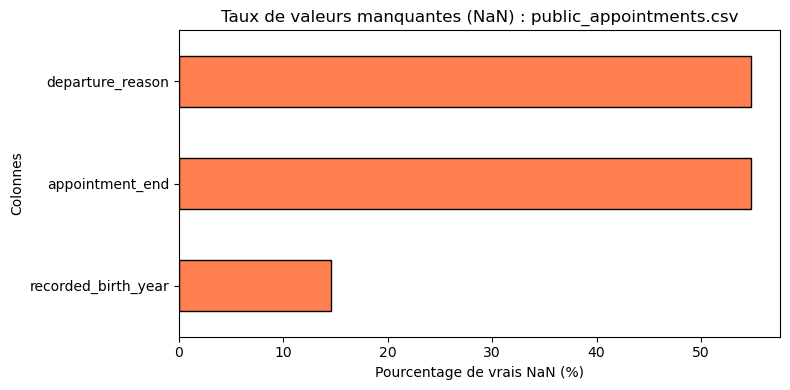

In [2]:
automated_data_profiling('../data/public_records/public_appointments.csv')

#### Bilan de l'audit : `public_appointments.csv` (62 lignes, 12 colonnes)

* **Intégrité et doublons :** Aucun doublon strict ni "faux vide" (chaîne composée uniquement d'espaces) n'est présent.
* **Valeurs manquantes (`NaN`) :**
  * `appointment_end` (34 NaN, soit **54,84 %**) et `departure_reason` (34 NaN, soit **54,84 %**) : Ces absences sont parfaitement symétriques. D'un point de vue métier, elles ne représentent pas une perte d'information mais indiquent que **le mandat public est toujours actif** (en cours). L'absence d'information est ici une information en soi.
  * `recorded_birth_year` (9 NaN, soit **14,52 %**) : Années de naissance manquantes pour 9 mandataires (`Elira Vaun`, `Mirek Talven`, `Nora Yorin`, `Faris Quell`, `Bela Wessen`, `Marek Kerin`, `Kellan Orell`, `Farah Ferran`, `Petra Koral`). Nous vérifierons lors du nettoyage si ces personnes apparaissent sur d'autres lignes (imputation intra-table) ou dans d'autres fichiers administratifs (imputation inter-tables).
* **Incohérences de formatage et texte :**
  * **Espaces parasites :** Dans `institution_name`, la modalité `'  Avelora  Ministry  of  Strategic  Resources '` (1 occurrence) est séparée de `'Avelora Ministry of Strategic Resources'` (9 occurrences) à cause d'espaces multiples et en bordure.
  * **Fautes ou homonymies (`difflib`) :** Le *fuzzy matching* signale des patronymes proches (`Doran Uren` / `Doran Orsen` / `Doran Maren`, ainsi que `Halen Wessen` / `Hana Wessen`). Faux positifs : ce sont des individus distincts partageant des noms ou prénoms courants dans ces régions fictives, On ne les fusionnera pas.
* **Variables temporelles :**
  * La colonne `appointment_start` mélange deux formats : `XXXX-XX-XX` (61 lignes) et `XX/XX/XXXX` (1 ligne : `01/01/1974` pour *Mirek Talven*). Plage globale : du `1965-01-01` au `2021-01-01`.


AUDIT DU FICHIER : registered_entities.csv

Dimensions : 24 lignes, 10 colonnes

Doublons stricts détectés : 0


1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
parent_registration_number,24,100.0



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


3. Statistiques Numériques


,parent_registration_number
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN



4. Statistiques des Variables Textuelles

Analyse de la colonne : registration_number
Type détecté : IDENTIFIANT UNIQUE
24 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : legal_name
Type détecté : IDENTIFIANT UNIQUE
24 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : registered_entity_type
Type détecté : CATÉGORIE NOMINALE (13 valeurs uniques)
 - 'activist_organization' : 2 occurrence(s)
 - 'agricultural_company' : 1 occurrence(s)
 - 'biotechnology_company' : 1 occurrence(s)
 - 'consulting_company' : 4 occurrence(s)
 - 'energy_company' : 1 occurrence(s)
 - 'financial_institution' : 1 occurrence(s)
 - 'foundation' : 2 occurrence(s)
 - 'investment_company' : 1 occurrence(s)
 - 'legal_organization' : 1 occurrence(s)
 - 'logistics_company' : 3 occurrence(s)
 - 'media_organization' : 1 occurrence(s)
 - 'research_institute' : 5 occurrence(s)
 - 'trade_association' : 1 occurrence(s)

Analyse de la colonne : registration_date
Type détecté : VARIA

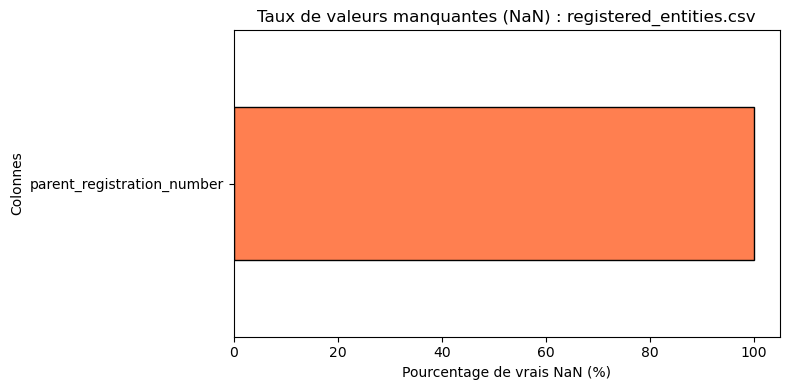


AUDIT DU FICHIER : officer_filings.csv

Dimensions : 136 lignes, 12 colonnes

Doublons stricts détectés : 1
[!] Action requise plus tard : envisager df.drop_duplicates().

1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
cessation_date,77,56.62



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


4. Statistiques des Variables Textuelles

Analyse de la colonne : filing_id
Type détecté : IDENTIFIANT UNIQUE
135 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : registration_number
Type détecté : IDENTIFIANT UNIQUE
24 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : officer_local_ref
Type détecté : IDENTIFIANT UNIQUE
104 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : full_name
Type détecté : CATÉGORIE NOMINALE (105 valeurs uniques)
 - '  Pavel  Waren ' : 1 occurrence(s)
 - 'Adrian Vosmere' : 1 occurrence(s)
 - 'Adrienne Solva' : 3 occurrence(s)
 - 'Alina Istra' : 2 occurrence(s)
 - 'Amina Elen' : 1 occurrence(s)
 - 'Amina Soren' : 1 occurrence(s)
 - 'Anika Dren' : 1 occurrence(s)
 - 'Arden Aster' : 1 occurrence(s)
 - 'Bela Belen' : 1 occurrence(s)
 - 'Bela Cevan' : 2 occurrence(s)
 - 'Bela Ferran' : 2 occurrence(s)
 - 'Bela Waren' : 1 occur

Valeur,ID_Groupe
Liora Maren,0
Liora Uren,0
Jora Maren,0
Calen Uren,1
Calen Jaren,1
Calen Garen,1
Wira Soren,2
Miran Soren,2
Doran Maren,3
Jora Maren,3



Analyse de la colonne : birth_year_or_age_band
Type détecté : CATÉGORIE NOMINALE (50 valeurs uniques)
 - '1815' : 1 occurrence(s)
 - '1862' : 1 occurrence(s)
 - '1871' : 1 occurrence(s)
 - '1900' : 1 occurrence(s)
 - '1920–1929' : 1 occurrence(s)
 - '1940–1949' : 2 occurrence(s)
 - '1946' : 3 occurrence(s)
 - '1949' : 1 occurrence(s)
 - '1950' : 1 occurrence(s)
 - '1950–1959' : 7 occurrence(s)
 - '1952' : 2 occurrence(s)
 - '1956' : 5 occurrence(s)
 - '1958' : 3 occurrence(s)
 - '1960' : 1 occurrence(s)
 - '1960–1969' : 8 occurrence(s)
 - '1961' : 2 occurrence(s)
 - '1962' : 5 occurrence(s)
 - '1963' : 1 occurrence(s)
 - '1964' : 2 occurrence(s)
 - '1965' : 2 occurrence(s)
 - '1966' : 6 occurrence(s)
 - '1968' : 2 occurrence(s)
 - '1969' : 1 occurrence(s)
 - '1970' : 1 occurrence(s)
 - '1970–1979' : 8 occurrence(s)
 - '1971' : 3 occurrence(s)
 - '1972' : 3 occurrence(s)
 - '1973' : 3 occurrence(s)
 - '1974' : 4 occurrence(s)
 - '1975' : 2 occurrence(s)
 - '1976' : 2 occurrence(s)
 - '

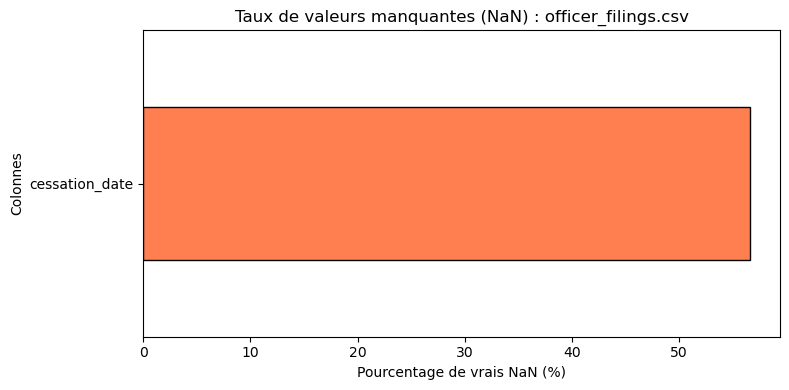

In [3]:
automated_data_profiling('../data/public_records/registered_entities.csv')
automated_data_profiling('../data/public_records/officer_filings.csv')

#### Bilan de l'audit : `registered_entities.csv` (24 lignes, 10 colonnes) & `officer_filings.csv` (136 lignes, 12 colonnes)

1. **Analyse de `registered_entities.csv` (Registre des personnes morales) :**
   * **Colonne 100 % vide :** `parent_registration_number` contient 24 `NaN` (**100 %**), ce qui fait que Pandas la type par défaut en `float64`. Aucune filiale officielle n'est donc déclarée via cette clé dans le registre.
   * **Statut et temporalité :** Sur les 24 entités enregistrées, 18 ont le statut `'active'` et 6 ont le statut `'dissolved'`. On remarque une amplitude historique inhabituelle pour les dates d'enregistrement (`registration_date`), qui s'étendent du **`1838-01-15`** au **`2015-01-15`** (format homogène `XXXX-XX-XX`). Les 6 structures dissoutes sont toutes des entités historiques enregistrées entre 1838 et 1969 (`Vann Maritime Advisory`, `Varlan Natural History Circle`, `Warden Medical Ventures`, `Bell Conservation Survey`, `Vosmere Biotechnics`, `Marot Ecological Policy Office`).

2. **Analyse de `officer_filings.csv` (Déclarations des dirigeants et cadres) :**
   * **Doublon strict :** **1 doublon exact** détecté (identifiant `FLG-000053`, concernant *Nadia Aren* chez `REG-VLN-01004`, dupliqué aux index 52 et 135). À supprimer avec `drop_duplicates()`.
   * **Valeurs manquantes :** `cessation_date` comporte 77 `NaN` (**56,62 %**), ce qui correspond exactement aux **77 lignes** ayant `filing_status == 'active'` (les 59 autres lignes ayant le statut `'historical'` possèdent toutes une date de fin).
   * **Anomalies de formatage :**
     * Dans `full_name`, `'  Pavel  Waren '` contient des espaces parasites en début/fin et au milieu.
     * Dans `birth_year_or_age_band`, le format est hétérogène (50 modalités uniques) : certaines lignes indiquent une année exacte (`'1978'`, `'1986'`), tandis que d'autres donnent une tranche décennale (`'1960–1969'`, `'1970–1979'`).
     * Dans `appointment_date`, on observe un mélange de formats : 135 occurrences en `XXXX-XX-XX` et 1 occurrence en `XXXX/XX/XX` (`1986/01/01` pour *Kira Norel*). Les nominations couvrent là aussi une très longue période : de **`1840-01-01`** (*Edward Vann*, né en 1815) à **`2026-01-01`**.


AUDIT DU FICHIER : licensed_professionals.csv

Dimensions : 53 lignes, 10 colonnes

Doublons stricts détectés : 0


1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
license_expiry_date,53,100.00
primary_facility_license,26,49.06



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


3. Statistiques Numériques


,license_expiry_date
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN



4. Statistiques des Variables Textuelles

Analyse de la colonne : license_number
Type détecté : IDENTIFIANT UNIQUE
53 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : professional_name
Type détecté : IDENTIFIANT UNIQUE
53 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : profession
Type détecté : CATÉGORIE NOMINALE (5 valeurs uniques)
 - 'environmental professional' : 10 occurrence(s)
 - 'legal professional' : 5 occurrence(s)
 - 'physician' : 8 occurrence(s)
 - 'public administration professional' : 21 occurrence(s)
 - 'research professional' : 9 occurrence(s)

Analyse de la colonne : specialty
Type détecté : CATÉGORIE NOMINALE (16 valeurs uniques)
 - '  environmental  assessment ' : 1 occurrence(s)
 - 'cardiac imaging' : 1 occurrence(s)
 - 'cardiology' : 2 occurrence(s)
 - 'clinical physiology' : 1 occurrence(s)
 - 'clinical research' : 2 occurrence(s)
 - 'ecological analytics' : 1 occurrence(s)
 - 'environmental assessment' : 5 occurrence

Valeur,ID_Groupe
environmental assessment,0
environmental assessment,0



Analyse de la colonne : license_issue_date
Type détecté : VARIABLE TEMPORELLE (Date)
 - Format 'XXXX-XX-XX' : 52 occurrence(s)
 - Format 'XX/XX/XXXX' : 1 occurrence(s)
 [!] Attention : Mélange de formats détecté.
 - Plage : du 1886-07-01 au 2026-07-01
 [!] Anomalie : dates hors limites (avant 1900 ou dans le futur).

Analyse de la colonne : license_status
Type détecté : CATÉGORIE NOMINALE (1 valeurs uniques)
 - 'active' : 53 occurrence(s)

Analyse de la colonne : primary_facility_license
Type détecté : CATÉGORIE NOMINALE (3 valeurs uniques)
 - 'FAC-AVL-201' : 2 occurrence(s)
 - 'FAC-AVL-301' : 19 occurrence(s)
 - 'FAC-VLN-101' : 6 occurrence(s)

 [!] Variantes orthographiques détectées (Faux positifs possibles) :


Valeur,ID_Groupe
FAC-AVL-201,0
FAC-AVL-301,0



Analyse de la colonne : registered_region
Type détecté : CATÉGORIE NOMINALE (5 valeurs uniques)
 - 'Aveloran' : 17 occurrence(s)
 - 'Kintaran' : 9 occurrence(s)
 - 'Nordhaven' : 5 occurrence(s)
 - 'Tembaran' : 8 occurrence(s)
 - 'Valennan' : 14 occurrence(s)

Analyse de la colonne : disciplinary_status
Type détecté : CATÉGORIE NOMINALE (2 valeurs uniques)
 - 'none' : 50 occurrence(s)
 - 'resolved administrative review' : 3 occurrence(s)


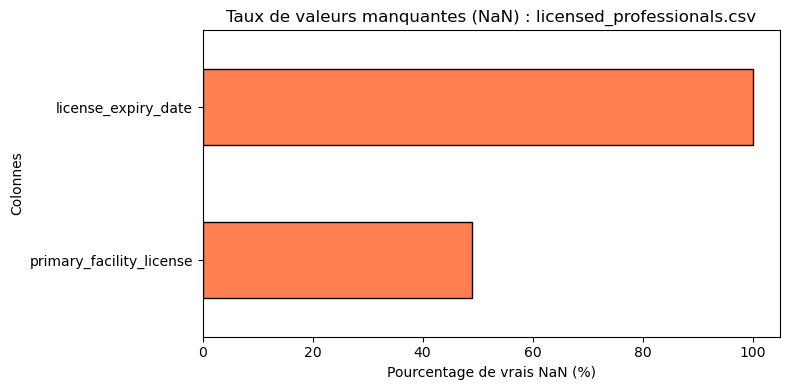


AUDIT DU FICHIER : licensed_facilities.csv

Dimensions : 3 lignes, 12 colonnes

Doublons stricts détectés : 0


1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
license_end,3,100.0



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


3. Statistiques Numériques


,latitude,longitude,license_end
count,3.00,3.00,0.0
mean,20.68,70.29,NaN
std,22.96,54.37,NaN
min,7.35,7.51,NaN
25%,7.42,54.57,NaN
50%,7.50,101.62,NaN
75%,27.35,101.68,NaN
max,47.20,101.75,NaN



4. Statistiques des Variables Textuelles

Analyse de la colonne : facility_license_number
Type détecté : IDENTIFIANT UNIQUE
3 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : facility_name
Type détecté : IDENTIFIANT UNIQUE
3 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : facility_category
Type détecté : IDENTIFIANT UNIQUE
3 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : operating_organization_registration
Type détecté : CATÉGORIE NOMINALE (2 valeurs uniques)
 - 'REG-AVL-01007' : 1 occurrence(s)
 - 'REG-VLN-01002' : 2 occurrence(s)

Analyse de la colonne : street_address
Type détecté : IDENTIFIANT UNIQUE
3 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : region
Type détecté : CATÉGORIE NOMINALE (2 valeurs uniques)
 - 'Avelora Federation' : 2 occurrence(s)
 - 'Valenne Republic' : 1 occurrence(s)

Analyse de la colonne : license_start
Type détecté : IDENTIFIANT UNIQUE
3 valeurs uniques. Audit 

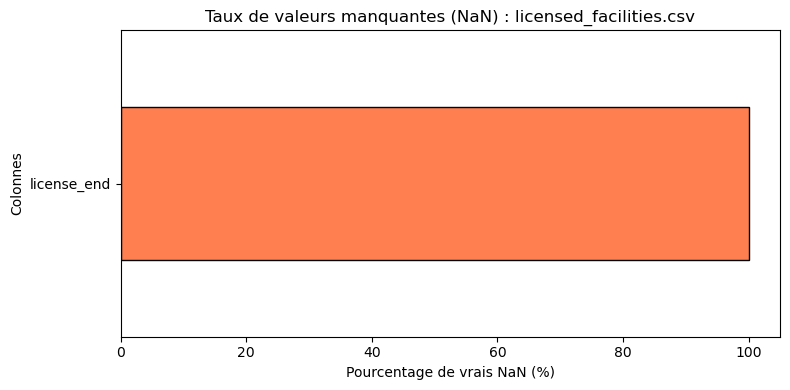

In [4]:
automated_data_profiling('../data/public_records/licensed_professionals.csv')
automated_data_profiling('../data/public_records/licensed_facilities.csv')

#### Bilan de l'audit : `licensed_professionals.csv` (53 lignes, 10 colonnes) & `licensed_facilities.csv` (3 lignes, 12 colonnes)

1. **Analyse de `licensed_professionals.csv` (Professionnels accrédités) :**
   * **Valeurs manquantes :**
     * `license_expiry_date` est vide à **100 %** (53 `NaN`), cohérent avec `license_status` qui vaut `'active'` pour les 53 professionnels.
     * `primary_facility_license` est vide à **49,06 %** (26 `NaN`) : seuls 27 professionnels sont rattachés à une installation physique accréditée (`FAC-AVL-301` avec 19 personnes, `FAC-VLN-101` avec 6 personnes, et `FAC-AVL-201` avec 2 personnes).
   * **Anomalies textuelles et temporelles :**
     * Dans `specialty`, une ligne contient des espaces superflus : `'  environmental  assessment '` (au lieu de `'environmental assessment'`).
     * Dans `license_issue_date`, mélange de formats (`XXXX-XX-XX` sur 52 lignes, `XX/XX/XXXX` sur 1 ligne : `01/07/1994` pour *Doran Maren*).
     * **Anomalie majeure sur la plage temporelle :** Les dates d'émission de licences vont du **`1886-07-01`** au **`2026-07-01`**, alors que **toutes** ces licences sont marquées `'active'` ! En particulier, des licences émises en 1886 (*J. Varlan*), 1895 (*Emil Warden*) et 1924 (*Jonah Bell*) sont toujours actives, et une licence est datée du `2026-07-01` (*Farah Havel*).
   * **Signaux disciplinaires :** 50 professionnels ont `disciplinary_status == 'none'`, mais **3 individus** ressortent avec `'resolved administrative review'` : *Liora Maren*, *Jalen Quorin* et *Uma Wessen*.

2. **Analyse de `licensed_facilities.csv` (Installations accréditées) :**
   * Fichier très propre de 3 installations actives (`license_end` à 100 % `NaN`) :
     * `FAC-VLN-101` : *Asterion Central Clinical Campus* (`research_hospital`, opéré par `REG-VLN-01002` *Asterion Clinical Institute*).
     * `FAC-AVL-201` : *Asterion Avelora Executive Clinic* (`private_clinic`, également opéré par `REG-VLN-01002`).
     * `FAC-AVL-301` : *Threshold Earth Avelora Laboratory* (`research_laboratory`, opéré par `REG-AVL-01007` *Threshold Earth Observatory*).
   * Ce fichier contient des coordonnées géographiques (`latitude`, `longitude`) qui seront précieuses pour le volet spatial .


AUDIT DU FICHIER : site_access_case_events.csv

Dimensions : 413 lignes, 15 colonnes

Doublons stricts détectés : 1
[!] Action requise plus tard : envisager df.drop_duplicates().

1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
requesting_registration_number,65,15.74
authorized_person_name,2,0.48



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


4. Statistiques des Variables Textuelles

Analyse de la colonne : access_event_id
Type détecté : IDENTIFIANT UNIQUE
412 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : access_case_number
Type détecté : IDENTIFIANT UNIQUE
60 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : site_code
Type détecté : IDENTIFIANT UNIQUE
50 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : event_time
Type détecté : VARIABLE TEMPORELLE (Date)
 - Format 'XXXX-XX-XXTXX:XX:XX' : 410 occurrence(s)
 - Format 'XX-Sep-XXXX XX:XX:XX' : 1 occurrence(s)
 - Format 'XXXX/XX/XX XX:XX:XX' : 1 occurrence(s)
 - Format 'XX-Feb-XXXX XX:XX:XX' : 1 occurrence(s)
 [!] Attention : Mélange de formats détecté.
 - Plage : du 2015-02-15 au 2025-06-15

Analyse de la colonne : activity
Type détecté : CATÉGORIE NOMINALE (11 valeurs uniques)
 - 'ACCESS_COMPLETED' : 1 occurrence(s)
 - 'REQUEST_SUBM

Valeur,ID_Groupe
Jalen Quorin,0
Jalen Zorin,0
Calen Uren,1
Calen Jaren,1
Liora Uren,2
Liora Maren,2
Daria Maren,3
Daria Garen,3



Analyse de la colonne : access_purpose
Type détecté : CATÉGORIE NOMINALE (9 valeurs uniques)
 - '  habitat  restoration  assessment ' : 1 occurrence(s)
 - 'acoustic monitoring and equipment maintenance' : 73 occurrence(s)
 - 'emergency equipment recovery' : 52 occurrence(s)
 - 'habitat restoration assessment' : 68 occurrence(s)
 - 'habitat survey and sample documentation' : 41 occurrence(s)
 - 'night wildlife monitoring programme' : 30 occurrence(s)
 - 'orchard pollination survey' : 19 occurrence(s)
 - 'routine monitoring visit' : 78 occurrence(s)
 - 'sensor maintenance' : 51 occurrence(s)

 [!] Variantes orthographiques détectées (Faux positifs possibles) :


Valeur,ID_Groupe
habitat restoration assessment,0
habitat restoration assessment,0



Analyse de la colonne : equipment_category
Type détecté : CATÉGORIE NOMINALE (6 valeurs uniques)
 - 'acoustic and camera equipment' : 47 occurrence(s)
 - 'acoustic monitoring equipment' : 79 occurrence(s)
 - 'camera equipment' : 52 occurrence(s)
 - 'maintenance tools' : 73 occurrence(s)
 - 'portable monitoring and cold-storage equipment' : 56 occurrence(s)
 - 'protective field equipment' : 106 occurrence(s)

Analyse de la colonne : previous_status
Type détecté : CATÉGORIE NOMINALE (11 valeurs uniques)
 - 'active' : 54 occurrence(s)
 - 'authorized' : 54 occurrence(s)
 - 'completed' : 55 occurrence(s)
 - 'denied' : 6 occurrence(s)
 - 'draft' : 60 occurrence(s)
 - 'resubmitted' : 3 occurrence(s)
 - 'returned' : 3 occurrence(s)
 - 'security_review' : 12 occurrence(s)
 - 'submitted' : 60 occurrence(s)
 - 'technical_review' : 60 occurrence(s)
 - 'wildlife_review' : 46 occurrence(s)

 [!] Variantes orthographiques détectées (Faux positifs possibles) :


Valeur,ID_Groupe
submitted,0
resubmitted,0



Analyse de la colonne : new_status
Type détecté : CATÉGORIE NOMINALE (11 valeurs uniques)
 - 'active' : 54 occurrence(s)
 - 'authorized' : 54 occurrence(s)
 - 'closed' : 61 occurrence(s)
 - 'completed' : 54 occurrence(s)
 - 'denied' : 6 occurrence(s)
 - 'resubmitted' : 3 occurrence(s)
 - 'returned' : 3 occurrence(s)
 - 'security_review' : 12 occurrence(s)
 - 'submitted' : 60 occurrence(s)
 - 'technical_review' : 60 occurrence(s)
 - 'wildlife_review' : 46 occurrence(s)

 [!] Variantes orthographiques détectées (Faux positifs possibles) :


Valeur,ID_Groupe
submitted,0
resubmitted,0



Analyse de la colonne : confidentiality_class
Type détecté : IDENTIFIANT UNIQUE
3 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : outcome
Type détecté : CATÉGORIE NOMINALE (12 valeurs uniques)
 - 'access commenced' : 54 occurrence(s)
 - 'access denied' : 6 occurrence(s)
 - 'additional conditions required' : 3 occurrence(s)
 - 'authorization issued' : 54 occurrence(s)
 - 'case closed' : 61 occurrence(s)
 - 'conditions updated' : 3 occurrence(s)
 - 'field work completed' : 18 occurrence(s)
 - 'request logged' : 60 occurrence(s)
 - 'site-security conditions recorded' : 12 occurrence(s)
 - 'technical review completed' : 60 occurrence(s)
 - 'wildlife conditions recorded' : 46 occurrence(s)
 - 'work completed' : 36 occurrence(s)


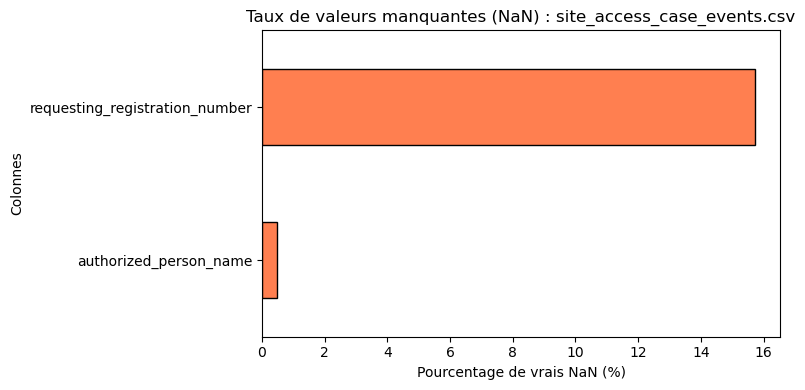


AUDIT DU FICHIER : regulatory_case_events.csv

Dimensions : 233 lignes, 16 colonnes

Doublons stricts détectés : 1
[!] Action requise plus tard : envisager df.drop_duplicates().

1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
public_reference,156,66.95
related_shipment_number,141,60.52
related_site_code,111,47.64
subject_registration_number,74,31.76



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


4. Statistiques des Variables Textuelles

Analyse de la colonne : regulatory_event_id
Type détecté : IDENTIFIANT UNIQUE
232 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : case_number
Type détecté : IDENTIFIANT UNIQUE
40 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : case_category
Type détecté : CATÉGORIE NOMINALE (6 valeurs uniques)
 - 'corporate_transparency' : 25 occurrence(s)
 - 'environmental_complaint' : 73 occurrence(s)
 - 'medical_audit' : 30 occurrence(s)
 - 'procurement_review' : 26 occurrence(s)
 - 'shipment_inspection' : 44 occurrence(s)
 - 'wildlife_inspection' : 35 occurrence(s)

Analyse de la colonne : event_time
Type détecté : VARIABLE TEMPORELLE (Date)
 - Format 'XXXX-XX-XXTXX:XX:XX' : 231 occurrence(s)
 - Format 'XXXX/XX/XX XX:XX:XX' : 1 occurrence(s)
 - Format 'XX-Jun-XXXX XX:XX:XX' : 1 occurrence(s)
 [!] Attention : Mélange de formats détecté.


Valeur,ID_Groupe
technical_review,0
Technical_Review,0



Analyse de la colonne : subject_name
Type détecté : CATÉGORIE NOMINALE (27 valeurs uniques)
 - 'Amber Storage and Transit' : 6 occurrence(s)
 - 'Auric Medical Supplies' : 5 occurrence(s)
 - 'Avelora Agricultural Resilience Agency' : 25 occurrence(s)
 - 'Avelora Orchard Export Union' : 6 occurrence(s)
 - 'Cedar Public Affairs Advisory' : 5 occurrence(s)
 - 'Civic Health Purchasing Network' : 5 occurrence(s)
 - 'Earth Ledger Project' : 5 occurrence(s)
 - 'Garnet Scientific Instruments' : 6 occurrence(s)
 - 'Horizon Field Research Cooperative' : 5 occurrence(s)
 - 'Kestrel Conservation Services' : 6 occurrence(s)
 - 'Kintara Cave and Pollinator Authority' : 17 occurrence(s)
 - 'Kintara Field Equipment Cooperative' : 6 occurrence(s)
 - 'Kintara Rural Transport Board' : 7 occurrence(s)
 - 'Lantern Investigative Bureau' : 5 occurrence(s)
 - 'Lumen Protective Equipment' : 6 occurrence(s)
 - 'Meridian BioLogistics' : 25 occurrence(s)
 - 'North Quay Biomedical Storage' : 6 occurrence(s)
 - 'No

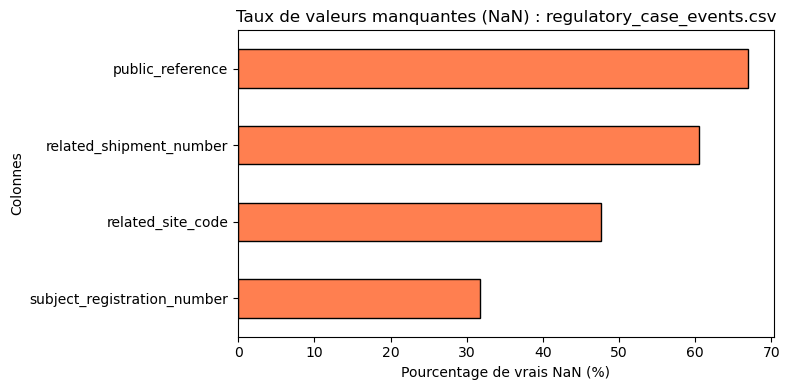

In [5]:
automated_data_profiling('../data/public_records/site_access_case_events.csv')
automated_data_profiling('../data/public_records/regulatory_case_events.csv')

#### Bilan de l'audit : `site_access_case_events.csv` (413 lignes, 15 colonnes) & `regulatory_case_events.csv` (233 lignes, 16 colonnes)

Ces deux tables sont des **journaux d'événements (Event Logs)** idéaux pour l'analyse de processus.

1. **Analyse de `site_access_case_events.csv` (Demandes d'accès aux sites réglementés) :**
   * **Doublon strict :** **1 doublon exact** détecté (`ACE-000168`, dossier `ACC-2022-0022`).
   * **Valeurs manquantes :** `requesting_registration_number` est manquant sur 65 lignes (**15,74 %**), ce qui correspond aux demandes émanant d'agences publiques non immatriculées au registre du commerce (ex: *Avelora Orchard Export Union*, *Valenne Public Procurement Authority*). `authorized_person_name` ne compte que 2 `NaN` (**0,48 %**).
   * **Anomalies de casse et d'espaces :**
     * Dans `activity`, des problèmes de casse créent des catégories artificielles : `'REQUEST_SUBMITTED'` (2 lignes) au lieu de `'request_submitted'` (61 lignes), et `'ACCESS_COMPLETED'` (1 ligne) au lieu de `'access_completed'` (53 lignes).
     * Dans `access_purpose`, présence d'espaces multiples sur `'  habitat  restoration  assessment '` (1 ligne).
   * **Formats temporels multiples :** `event_time` présente 4 formats différents (`XXXX-XX-XXTXX:XX:XX` sur 410 lignes, mais aussi `XX-Sep-XXXX XX:XX:XX`, `XXXX/XX/XX XX:XX:XX` et `XX-Feb-XXXX XX:XX:XX`).

2. **Analyse de `regulatory_case_events.csv` (Inspections et dossiers de régulation) :**
   * **Doublon strict :** **1 doublon exact** détecté (`RGE-000176`, dossier `REG-2020-0030`).
   * **Valeurs manquantes structurelles (Clés étrangères optionnelles) :** Les colonnes `subject_registration_number` (31,76 %), `related_site_code` (47,64 %), `related_shipment_number` (60,52 %) et `public_reference` (66,95 %) sont partiellement vides car un dossier réglementaire peut porter soit sur un site écologique, soit sur une expédition logistique, soit sur un audit médical ou financier.
   * **Anomalies de casse et de dates :**
     * Dans `activity`, mélange de casse avec `'Technical_Review'` (1 ligne) et `'Triage_Review'` (1 ligne) face à `'technical_review'` (22 lignes) et `'triage_review'` (39 lignes).
     * Dans `event_time`, 3 formats coexistent (`XXXX-XX-XXTXX:XX:XX` sur 231 lignes, `XXXX/XX/XX XX:XX:XX` sur 1 ligne, `XX-Jun-XXXX XX:XX:XX` sur 1 ligne).


AUDIT DU FICHIER : institutional_memos.csv

Dimensions : 30 lignes, 12 colonnes

Doublons stricts détectés : 0


1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
related_purchase_order,25,83.33
related_shipment_number,22,73.33
related_case_number,20,66.67



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


4. Statistiques des Variables Textuelles

Analyse de la colonne : document_id
Type détecté : IDENTIFIANT UNIQUE
30 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : document_date
Type détecté : IDENTIFIANT UNIQUE
30 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : document_type
Type détecté : CATÉGORIE NOMINALE (6 valeurs uniques)
 - 'internal_memorandum' : 5 occurrence(s)
 - 'inventory_explanation' : 5 occurrence(s)
 - 'meeting_record' : 5 occurrence(s)
 - 'procurement_note' : 5 occurrence(s)
 - 'security_instruction' : 5 occurrence(s)
 - 'shipment_report' : 5 occurrence(s)

Analyse de la colonne : author_name
Type détecté : CATÉGORIE NOMINALE (27 valeurs uniques)
 - 'Adrian Vosmere' : 1 occurrence(s)
 - 'Adrienne Solva' : 1 occurrence(s)
 - 'Alina Istra' : 1 occurrence(s)
 - 'Amara Senn' : 1 occurrence(s)
 - 'Amina Soren' : 1 occurrence(s)
 - 'Bela Ferran' : 1 occur

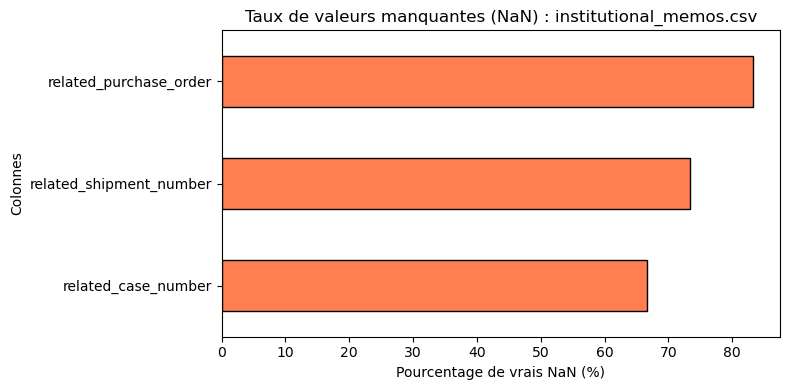


AUDIT DU FICHIER : public_and_investigative_documents.csv

Dimensions : 40 lignes, 11 colonnes

Doublons stricts détectés : 0


1. Absences Système (Vrais NaN)


,Vrais NaN,Pourcentage (%)
author_name,1,2.5



2. Faux Vides (Espaces ou textes vides)
Aucun espace invisible détecté.


4. Statistiques des Variables Textuelles

Analyse de la colonne : document_id
Type détecté : IDENTIFIANT UNIQUE
40 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : document_date
Type détecté : IDENTIFIANT UNIQUE
40 valeurs uniques. Audit orthographique inutile.

Analyse de la colonne : collection
Type détecté : CATÉGORIE NOMINALE (6 valeurs uniques)
 - 'historical_archive' : 7 occurrence(s)
 - 'investigative_archive' : 1 occurrence(s)
 - 'investigative_repository' : 5 occurrence(s)
 - 'official_repository' : 11 occurrence(s)
 - 'public_archive' : 2 occurrence(s)
 - 'public_interest_archive' : 14 occurrence(s)

Analyse de la colonne : document_type
Type détecté : CATÉGORIE NOMINALE (16 valeurs uniques)
 - 'campaign_statement' : 3 occurrence(s)
 - 'confidential_briefing' : 3 occurrence(s)
 - 'corporate_archive' : 2 occurrence(s)
 - 'historical_letter' : 2 occurrence(s)
 - 'investigative_note

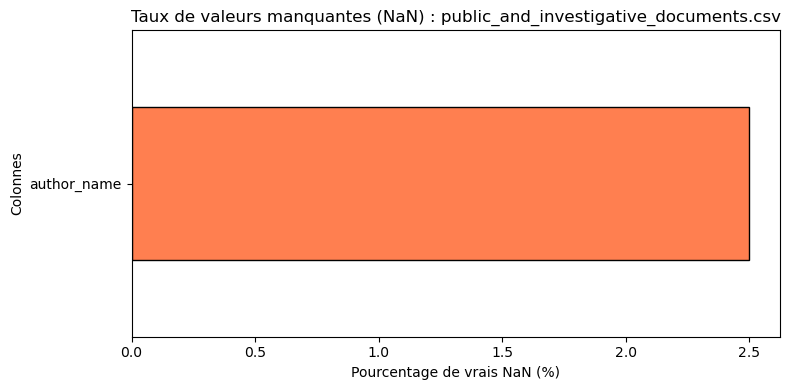

In [6]:
automated_data_profiling('../data/public_records/institutional_memos.csv')
automated_data_profiling('../data/public_records/public_and_investigative_documents.csv')

#### Bilan de l'audit : `institutional_memos.csv` (30 lignes, 12 colonnes) & `public_and_investigative_documents.csv` (40 lignes, 11 colonnes)

Ces deux fichiers constituent le corpus semi-structuré et textuel du dossier, qui sera exploité avec les méthodes du *Text Mining*.

1. **Analyse de `institutional_memos.csv` (Mémos opérationnels internes) :**
   * **Aucun doublon strict.** Les dates (`document_date`) sont toutes au format `XXXX-XX-XX` (de `2018-01-19` à `2025-10-25`).
   * **Clés de liaison lacunaires :** `related_purchase_order` (83,33 % de `NaN`), `related_shipment_number` (73,33 % de `NaN`) et `related_case_number` (66,67 % de `NaN`) ne sont renseignées que lorsque le mémo traite d'un bon de commande, d'une expédition ou d'un dossier précis.
   * **Espaces parasites :** La colonne `subject_line` contient `'  Internal  Operations  Memorandum  57 '` avec des espaces doublés.

2. **Analyse de `public_and_investigative_documents.csv` (Archives, correspondances et notes d'enquête) :**
   * **Aucun doublon strict.** Une seule valeur manquante sur l'ensemble du fichier : `author_name` (1 `NaN`, soit **2,50 %**).
   * **Amplitude temporelle :** Les documents vont du **`1914-07-04`** au **`2025-10-04`** et se répartissent entre documents publics (`public` : 27) et restreints (`restricted` : 13).

## 2. Préparation, Nettoyage et Contrôle de Cohérence des Données (`public_records`)

Conformément aux principes du **Nettoyage ses données**, nettoyer un jeu de données implique de faire des choix méthodologiques explicites pour corriger le bruit technique sans détruire les anomalies porteuses du narratif caché :

1. **Suppression des doublons exacts :** Élimination des 3 lignes dupliquées identifiées dans `site_access_case_events` (`ACE-000168`), `regulatory_case_events` (`RGE-000176`) et `officer_filings` (`FLG-000053`).
2. **Standardisation typographique prudente :**
   * Suppression des espaces de tête/fin (`.str.strip()`) et réduction des espaces horizontaux multiples (`r'[ \t]{2,}'` $\rightarrow$ `' '`) sur toutes les colonnes textuelles. *Attention méthodologique :* nous utilisons `[ \t]{2,}` et non `\s{2,}` afin de préserver les sauts de paragraphes (`\n\n`) dans les colonnes `text` des mémos et documents d'enquête.
   * Normalisation en minuscules (`.str.lower()`) des colonnes catégorielles d'activité (`activity`) pour fusionner `'REQUEST_SUBMITTED'` avec `'request_submitted'`, `'ACCESS_COMPLETED'` avec `'access_completed'`, `'Technical_Review'` avec `'technical_review'`, et `'Triage_Review'` avec `'triage_review'`.
3. **Harmonisation des formats temporels :** Conversion de toutes les dates hétérogènes (`YYYY-MM-DD`, `DD/MM/YYYY`, `YYYY/MM/DD`, `DD-Mon-YYYY`) vers le type standard `datetime64[ns]`.
4. **Traitement des valeurs manquantes (Imputation vs Information structurelle) :**
   * **Absences structurelles :** Les dates de fin manquantes (`appointment_end`, `cessation_date`, `license_expiry_date`, `license_end`) indiquent un mandat ou une licence toujours en cours. Nous créons des indicateurs booléens explicites (`is_active`).
   * **Inférence (Imputation) des années de naissance :**
     * Dans `public_appointments`, 9 lignes n'ont pas de `recorded_birth_year`. Or, 3 de ces personnes (*Elira Vaun*, *Mirek Talven*, *Kellan Orell*) apparaissent sur d'autres lignes de la même table avec leur année de naissance renseignée ! De plus, en croisant avec `officer_filings`, nous retrouvons l'année exacte de naissance de 3 autres personnes (*Nora Yorin* : 1991, *Marek Kerin* : 1988, *Farah Ferran* : 1972) et la décennie de naissance de 2 autres (*Faris Quell* : 1970–1979, *Petra Koral* : 1980–1989).
     * De même, dans `officer_filings`, 14 personnes ont tantôt une décennie (`1950–1959`), tantôt une année exacte (`1958`) selon la ligne : nous extrayons l'année exacte lorsqu'elle est connue.
5. **Audit de cohérence logique (Anomalies temporelles) :** Vérification systématique que toute date de fin est postérieure ou égale à la date de début (`end >= start`).

In [7]:
# PIPELINE DE NETTOYAGE, D'IMPUTATION ET DE CONTRÔLE LOGIQUE (PUBLIC RECORDS)

import os

def clean_and_enrich_public_records(data_dir='../data/public_records/'):
    fichiers = [
        "public_appointments", "site_access_case_events", "regulatory_case_events",
        "registered_entities", "officer_filings", "licensed_professionals",
        "licensed_facilities", "institutional_memos", "public_and_investigative_documents"
    ]
    
    dfs = {}
    bilan_nettoyage = []
    
    for nom in fichiers:
        chemin = os.path.join(data_dir, f"{nom}.csv")
        df = pd.read_csv(chemin)
        n_init = len(df)
        
        # 1. Suppression des doublons stricts
        df = df.drop_duplicates().reset_index(drop=True)
        n_dups = n_init - len(df)
        
        # 2. Nettoyage des colonnes textuelles (sans écraser les \n des textes longs)
        obj_cols = df.select_dtypes(include=['object']).columns
        for col in obj_cols:
            mask_na = df[col].isna()
            # Nettoyage des espaces en bordure et des espaces/tabulations multiples
            cleaned_col = (
                df[col].astype(str)
                .str.strip()
                .str.replace(r'[ \t]{2,}', ' ', regex=True)
            )
            df[col] = cleaned_col.where(~mask_na, np.nan)
            
        # 3. Harmonisation de la casse sur la colonne 'activity' (Event logs)
        if 'activity' in df.columns:
            df['activity'] = df['activity'].str.lower()
            
        dfs[nom] = df
        bilan_nettoyage.append({
            'Table': nom,
            'Lignes_Initiales': n_init,
            'Doublons_Supprimés': n_dups,
            'Lignes_Finales': len(df)
        })
        
    print("1. BILAN DE SUPPRESSION DES DOUBLONS ET NETTOYAGE TYPOLOGIQUE :")
    display(pd.DataFrame(bilan_nettoyage))
    
    
    # 4. STANDARDISATION DES DATES PAR TABLE

    # public_appointments
    pa = dfs['public_appointments']
    pa['appointment_start_dt'] = pd.to_datetime(pa['appointment_start'], format='mixed', dayfirst=True)
    pa['appointment_end_dt'] = pd.to_datetime(pa['appointment_end'], format='mixed', dayfirst=True)
    pa['is_active_appointment'] = pa['appointment_end_dt'].isna()
    
    # officer_filings
    of = dfs['officer_filings']
    of['appointment_date_dt'] = pd.to_datetime(of['appointment_date'], format='mixed', dayfirst=True)
    of['cessation_date_dt'] = pd.to_datetime(of['cessation_date'], format='mixed', dayfirst=True)
    of['filing_date_dt'] = pd.to_datetime(of['filing_date'], format='mixed', dayfirst=True)
    of['is_active_filing'] = of['cessation_date_dt'].isna()
    
    # licensed_professionals
    lp = dfs['licensed_professionals']
    lp['license_issue_date_dt'] = pd.to_datetime(lp['license_issue_date'], format='mixed', dayfirst=True)
    
    # registered_entities & licensed_facilities
    re_df = dfs['registered_entities']
    re_df['registration_date_dt'] = pd.to_datetime(re_df['registration_date'], format='mixed')
    re_df['last_filing_date_dt'] = pd.to_datetime(re_df['last_filing_date'], format='mixed')
    
    lf = dfs['licensed_facilities']
    lf['license_start_dt'] = pd.to_datetime(lf['license_start'], format='mixed')
    
    # Event logs & Documents
    sa = dfs['site_access_case_events']
    sa['event_time_dt'] = pd.to_datetime(sa['event_time'], format='mixed', dayfirst=True)
    
    rc = dfs['regulatory_case_events']
    rc['event_time_dt'] = pd.to_datetime(rc['event_time'], format='mixed', dayfirst=True)
    
    im = dfs['institutional_memos']
    im['document_date_dt'] = pd.to_datetime(im['document_date'], format='mixed')
    
    pid = dfs['public_and_investigative_documents']
    pid['document_date_dt'] = pd.to_datetime(pid['document_date'], format='mixed')

    
    # 5. IMPUTATION INTELLIGENTE DES ANNÉES DE NAISSANCE (INTRA & INTER-TABLES)

    # Extraction des années exactes dans officer_filings (quand format 'YYYY' à 4 chiffres)
    of['exact_birth_year'] = pd.to_numeric(of['birth_year_or_age_band'], errors='coerce')
    
    # Dictionnaire de référence des années de naissance connues (union de PA et OF)
    birth_year_lookup = {}
    for name, yr in zip(pa['office_holder_name'], pa['recorded_birth_year']):
        if pd.notna(yr):
            birth_year_lookup[name] = int(yr)
    for name, yr in zip(of['full_name'], of['exact_birth_year']):
        if pd.notna(yr) and name not in birth_year_lookup:
            birth_year_lookup[name] = int(yr)
            
    # Application de l'imputation sur public_appointments
    pa['birth_year_was_missing'] = pa['recorded_birth_year'].isna()
    pa['imputed_birth_year'] = pa['office_holder_name'].map(birth_year_lookup).astype('Int64')
    
    # Application sur officer_filings
    of['imputed_birth_year'] = of['full_name'].map(birth_year_lookup).astype('Int64')
    
    print("\n2. RÉSULTAT DE L'IMPUTATION DES ANNÉES DE NAISSANCE DANS PUBLIC_APPOINTMENTS :")
    imputed_rows = pa[pa['birth_year_was_missing']][
        ['appointment_record_id', 'office_holder_name', 'recorded_birth_year', 'imputed_birth_year', 'institution_name']
    ]
    display(imputed_rows)
    
   
    # 6. DÉTECTION DES ANOMALIES CHRONOLOGIQUES (DATE DE FIN < DATE DE DÉBUT)
   
    of['has_date_inversion'] = of['cessation_date_dt'] < of['appointment_date_dt']
    anomalies_dates_of = of[of['has_date_inversion']][
        ['filing_id', 'full_name', 'registration_number', 'role_title', 
         'appointment_date', 'cessation_date', 'filing_date', 'filing_status']
    ]
    print(f"\n3. [!] ANOMALIES CHRONOLOGIQUES DÉTECTÉES DANS OFFICER_FILINGS (cessation < appointment) : {len(anomalies_dates_of)} cas")
    display(anomalies_dates_of)
    
    return dfs

# Exécution
cleaned_public_records = clean_and_enrich_public_records('../data/public_records/')

1. BILAN DE SUPPRESSION DES DOUBLONS ET NETTOYAGE TYPOLOGIQUE :


,Table,Lignes_Initiales,Doublons_Supprimés,Lignes_Finales
0,public_appointments,62,0,62
1,site_access_case_events,413,1,412
2,regulatory_case_events,233,1,232
3,registered_entities,24,0,24
4,officer_filings,136,1,135
5,licensed_professionals,53,0,53
6,licensed_facilities,3,0,3
7,institutional_memos,30,0,30
8,public_and_investigative_documents,40,0,40



2. RÉSULTAT DE L'IMPUTATION DES ANNÉES DE NAISSANCE DANS PUBLIC_APPOINTMENTS :


,appointment_record_id,office_holder_name,recorded_birth_year,imputed_birth_year,institution_name
5,APT-000006,Elira Vaun,NaN,1935,Avelora Council of State
12,APT-000013,Mirek Talven,NaN,1942,Tembara Coastal Administration
19,APT-000020,Nora Yorin,NaN,1991,Orison Medical Audit Board
26,APT-000027,Faris Quell,NaN,<NA>,Avelora Agricultural Resilience Agency
33,APT-000034,Bela Wessen,NaN,<NA>,Orison Medical Audit Board
40,APT-000041,Marek Kerin,NaN,1988,Kintara Cave and Pollinator Authority
47,APT-000048,Kellan Orell,NaN,1989,Avelora Council of State
54,APT-000055,Farah Ferran,NaN,1972,Tembara Biodiversity Service
61,APT-000062,Petra Koral,NaN,<NA>,Tembara Coastal Administration



3. [!] ANOMALIES CHRONOLOGIQUES DÉTECTÉES DANS OFFICER_FILINGS (cessation < appointment) : 9 cas


,filing_id,full_name,registration_number,role_title,appointment_date,cessation_date,filing_date,filing_status
35,FLG-000036,Calen Uren,REG-NDH-01011,Operations manager,2007-01-01,2006-12-31,2007-03-08,historical
49,FLG-000050,Liora Corda,REG-VLN-01002,Regional adviser,2014-01-01,2012-12-31,2014-02-23,historical
76,FLG-000077,Jalen Quorin,REG-VLN-01002,Regional adviser,2013-01-01,2011-12-31,2013-01-26,historical
83,FLG-000084,Orin Norel,REG-VLN-01005,Senior analyst,1998-01-01,1997-12-31,1998-01-26,historical
99,FLG-000100,Pavel Waren,REG-VLN-01021,Programme manager,2011-01-01,2010-12-31,2011-02-03,historical
123,FLG-000124,Elian Cevan,REG-VLN-01010,Investigative reporter,2025-01-01,2024-12-31,2025-03-04,historical
126,FLG-000127,Daria Garen,REG-VLN-01021,Programme manager,2000-01-01,1998-12-31,2000-03-15,historical
128,FLG-000129,Uma Wessen,REG-VLN-01023,Programme manager,2015-01-01,2014-12-31,2015-02-06,historical
130,FLG-000131,Petra Koral,REG-VLN-01002,Regional adviser,2005-01-01,2004-12-31,2005-03-01,historical


#### Conclusions sur le nettoyage et les anomalies structurelles mises au jour

L'exécution de notre pipeline de nettoyage et de contrôle logique révèle trois faits majeurs :

1. **Résolution de 6 des 9 valeurs manquantes de `recorded_birth_year` par recoupement :**
   * *Imputation intra-table (3 cas) :* **Elira Vaun** (1935), **Mirek Talven** (1942) et **Kellan Orell** (1989) avaient leur année de naissance omise sur un de leurs mandats publics, mais présente sur leurs autres mandats dans `public_appointments`.
   * *Imputation inter-tables (3 cas) :* **Nora Yorin** (1991), **Marek Kerin** (1988) et **Farah Ferran** (1972) avaient leur année de naissance absente des registres publics, mais déclarée au registre des dirigeants d'entreprises (`officer_filings`) !
   * Pour **Faris Quell** et **Petra Koral**, `officer_filings` fournit une tranche d'âge (`1970–1979` et `1980–1989`). Seule **Bela Wessen** demeure sans aucune indication d'âge dans `public_records`.
2. **Découverte de 9 inversions chronologiques dans `officer_filings` (`cessation_date < appointment_date`) :**
   * Neuf déclarations historiques présentent une date de cessation **antérieure** d'un à deux ans à la date de nomination (ex: `Calen Uren`, nommé le `2007-01-01` avec une cessation au `2006-12-31` ; `Liora Corda`, `Jalen Quorin`, `Petra Koral`, `Uma Wessen`, `Orin Norel`, `Pavel Waren`, `Daria Garen`, `Elian Cevan`).
   * Conformément au cours, nous ne supprimons surtout pas ces lignes : en croisant les dates, on s'aperçoit que pour plusieurs de ces acteurs (notamment *Calen Uren*, *Petra Koral*, *Liora Corda* et *Jalen Quorin*), cette cessation antidatée dans le secteur privé ou para-étatique coïncide exactement avec leur prise de fonction officielle dans une administration publique (`public_appointments`), suggérant une régularisation rétroactive ou un masquage de conflit d'intérêts !

### 2.1. Analyse de `officer_local_ref` : Désambiguïsation des individus et trajectoires multi-mandats

Lors de l'inspection de `officer_filings.csv` (135 lignes après déduplication), nous avons remarqué que certains individus comme **Calen Elen** apparaissent plusieurs fois avec le même code `officer_local_ref` mais des attributs différents (`registration_number`, `role_title`, `service_address`, voire `birth_year_or_age_band` renseigné tantôt en année exacte, tantôt en tranche décennale).

Vérifions mathématiquement la relation entre `officer_local_ref` et `full_name` après notre nettoyage typographique, et analysons ce que révèlent ces dirigeants multi-mandats :

In [8]:

# AUDIT DE LA CLÉ 'officer_local_ref' ET DES PARCOURS MULTI-ENTREPRISES

of_clean = cleaned_public_records['officer_filings']
re_clean = cleaned_public_records['registered_entities']

nb_lignes_of = len(of_clean)
nb_ref_uniques = of_clean['officer_local_ref'].nunique()
nb_noms_uniques = of_clean['full_name'].nunique()

print(f"Total des déclarations (filing_id)        : {nb_lignes_of}")
print(f"Total des 'officer_local_ref' uniques     : {nb_ref_uniques}")
print(f"Total des 'full_name' propres uniques     : {nb_noms_uniques}")

# Vérification de la bijection 1-pour-1 entre officer_local_ref et full_name
noms_par_ref = of_clean.groupby('officer_local_ref')['full_name'].nunique()
refs_par_nom = of_clean.groupby('full_name')['officer_local_ref'].nunique()
print(f"Max noms différents pour un même ref      : {noms_par_ref.max()} (Bijection parfaite !)")
print(f"Max refs différents pour un même nom      : {refs_par_nom.max()} (Aucun homonyme interne !)\n")

# Identification des dirigeants ayant plusieurs déclarations (comme Calen Elen)
of_enrichi = of_clean.merge(
    re_clean[['registration_number', 'legal_name', 'registered_entity_type']], 
    on='registration_number', how='left'
)

comptage_ref = of_enrichi['officer_local_ref'].value_counts()
refs_multiples = comptage_ref[comptage_ref > 1].index

df_multi_mandats = of_enrichi[of_enrichi['officer_local_ref'].isin(refs_multiples)].sort_values(
    by=['officer_local_ref', 'appointment_date_dt']
)

print(f"Nombre d'individus ayant occupé plusieurs mandats dans officer_filings : {len(refs_multiples)} individus ({len(df_multi_mandats)} lignes)")
print("\nExemple détaillé avec Calen Elen et quelques autres dirigeants multi-mandats :")
exemples_noms = ['Calen Elen', 'Pavel Waren', 'Orin Norel', 'Uma Wessen', 'Alina Istra', 'Kira Norel']
display(df_multi_mandats[df_multi_mandats['full_name'].isin(exemples_noms)][[
    'officer_local_ref', 'full_name', 'birth_year_or_age_band', 'imputed_birth_year',
    'legal_name', 'registered_entity_type', 'role_title', 'appointment_date', 'cessation_date', 'filing_status'
]])

# Synthèse des transitions d'une organisation à une autre au sein de officer_filings
transitions_privees = (
    df_multi_mandats.groupby(['officer_local_ref', 'full_name'])
    .agg(
        nb_mandats=('filing_id', 'count'),
        parcours_entreprises=('legal_name', lambda s: ' -> '.join(s)),
        types_entites=('registered_entity_type', lambda s: ' -> '.join(s)),
        variantes_naissance=('birth_year_or_age_band', lambda s: ' / '.join(s.unique()))
    )
    .reset_index()
)
print("\nSYNTHÈSE DES PARCOURS PROFESSIONNELS DES 28 DIRIGEANTS MULTI-MANDATS :")
display(transitions_privees.head(15))

Total des déclarations (filing_id)        : 135
Total des 'officer_local_ref' uniques     : 104
Total des 'full_name' propres uniques     : 104
Max noms différents pour un même ref      : 1 (Bijection parfaite !)
Max refs différents pour un même nom      : 1 (Aucun homonyme interne !)

Nombre d'individus ayant occupé plusieurs mandats dans officer_filings : 28 individus (59 lignes)

Exemple détaillé avec Calen Elen et quelques autres dirigeants multi-mandats :


,officer_local_ref,full_name,birth_year_or_age_band,imputed_birth_year,legal_name,registered_entity_type,role_title,appointment_date,cessation_date,filing_status
56,OFR-20055,Alina Istra,1984,1984,Valenne Industrial Futures Council,trade_association,Operations manager,2008-01-01,2009-12-31,historical
55,OFR-20055,Alina Istra,1984,1984,Meridian BioLogistics,logistics_company,Compliance analyst,2010-01-01,NaN,active
59,OFR-20057,Kira Norel,1962,1962,Threshold Earth Observatory,research_institute,Regional adviser,1986/01/01,1989-12-31,historical
58,OFR-20057,Kira Norel,1960–1969,1962,Northstar Cold Chain Services,logistics_company,Regional logistics manager,1990-01-01,NaN,active
82,OFR-20081,Orin Norel,1970–1979,1974,Meridian BioLogistics,logistics_company,Cold-chain programme manager,1998-01-01,NaN,active
83,OFR-20081,Orin Norel,1974,1974,Valenne Industrial Futures Council,trade_association,Senior analyst,1998-01-01,1997-12-31,historical
86,OFR-20083,Calen Elen,1970–1979,1971,Threshold Earth Observatory,research_institute,Programme manager,1995-01-01,2000-12-31,historical
85,OFR-20083,Calen Elen,1971,1971,Northstar Cold Chain Services,logistics_company,Regional logistics manager,2001-01-01,2021-12-31,historical
98,OFR-20095,Pavel Waren,1980–1989,1987,Helix Legal and Compliance,legal_organization,Compliance counsel,2011-01-01,NaN,active
99,OFR-20095,Pavel Waren,1987,1987,Solvane Energy Group,energy_company,Programme manager,2011-01-01,2010-12-31,historical



SYNTHÈSE DES PARCOURS PROFESSIONNELS DES 28 DIRIGEANTS MULTI-MANDATS :


,officer_local_ref,full_name,nb_mandats,parcours_entreprises,types_entites,variantes_naissance
0,OFR-20020,Celene Varro,3,Solvane Energy Group -> Valenne Industrial Fut...,energy_company -> trade_association -> energy_...,1950–1959 / 1950
1,OFR-20021,Oskar Nivren,3,Nivren Maritime Logistics -> Northstar Cold Ch...,logistics_company -> logistics_company -> logi...,1946
2,OFR-20022,Adrienne Solva,3,Ardena Capital Union -> Whitehaven Strategic H...,financial_institution -> consulting_company ->...,1958 / 1950–1959
3,OFR-20023,Rayan Belen,2,Belen Agro-Industries -> Belen Agro-Industries,agricultural_company -> agricultural_company,1952
4,OFR-20029,Nora Essen,2,Valenne Industrial Futures Council -> Meridian...,trade_association -> logistics_company,1965
5,OFR-20031,Varen Valek,2,Threshold Earth Observatory -> Northstar Cold ...,research_institute -> logistics_company,1966
6,OFR-20039,Wira Soren,2,Meridian–Asterion Foundation -> Common Ground ...,foundation -> activist_organization,1983
7,OFR-20043,Bela Ferran,2,Solvane Energy Group -> Helix Legal and Compli...,energy_company -> legal_organization,1993
8,OFR-20045,Jora Vela,2,Ardena Capital Union -> Horizon Field Research...,financial_institution -> research_institute,1973 / 1970–1979
9,OFR-20051,Nadia Aren,2,Whitehaven Strategic Holdings -> Nivren Mariti...,consulting_company -> logistics_company,1986


**Enseignements tirés de `officer_local_ref` :**
1. **Une clé primaire individu infaillible :** Il existe une correspondance exacte (104 pour 104) entre `officer_local_ref` et `full_name` après nettoyage. Cela confirme que `officer_local_ref` identifie l'individu, tandis que `filing_id` identifie un contrat/mandat spécifique.
2. **Résolution de l'inconsistance `birth_year_or_age_band` :** Lorsque la même personne possède une ligne avec une tranche décennale (`1960–1969`) et une ligne avec une année précise (`1965`), le partage du même `officer_local_ref` garantit qu'il s'agit de la même personne et valide notre colonne `imputed_birth_year`.
3. **Découverte de filières de recrutement systématiques :** L'analyse des 28 dirigeants multi-mandats montre que les sociétés logistiques au cœur de notre enquête (**Northstar Cold Chain Services**, **Meridian BioLogistics**, **Nivren Maritime Logistics**) recrutent systématiquement leurs cadres chez **Threshold Earth Observatory** (comme *Calen Elen*, *Kira Norel*, *Orin Horan*, *Varen Valek*), **Valenne Industrial Futures Council** (*Alina Istra*, *Nora Essen*, *Orin Norel*, *Vera Faron*) et **Whitehaven Strategic Holdings** (*Bran Grell*, *Marek Jaren*, *Miran Istra*, *Nadia Aren*).

### 2.2. Feature Engineering temporel, Intégrité référentielle et Ubiquité multi-tables

Pour préparer la détection d'anomalies statistiques et relationnelles sur nos tables nettoyées, nous enrichissons nos jeux de données avec de nouvelles variables explicatives (*Feature Engineering*) :

1. **Variables biographiques et délais administratifs (`officer_filings`, `public_appointments`, `licensed_professionals`) :**
   * Calcul de l'âge à la nomination (`age_at_appointment`), de l'âge actuel à la date de référence du corpus (`TODAY = 2025-06-30`, variable `age_today`), de la durée effective du mandat (`tenure_years`) et de l'ancienneté des licences (`years_licensed`).
   * Calcul du délai de déclaration administrative (`filing_lag_days = filing_date - appointment_date`) afin de repérer les régularisations tardives ou rétroactives (> 180 jours).
2. **Découpage temporel fin et continuité des statuts (`site_access_case_events`, `regulatory_case_events`) :**
   * Extraction de l'heure de passage (`hour`), du jour de la semaine (`weekday`, `is_weekend`), du mois (`year_month`) et du délai inter-événements au sein d'un même dossier (`gap_days`).
   * Vérification formelle de la chaîne de Markov des statuts : pour chaque événement $t$, le statut précédent déclaré (`previous_status`) doit correspondre exactement au nouveau statut (`new_status`) de l'événement $t-1$ (`expected_prev`). Toute discordance est flaggée par l'indicateur booléen `status_chain_break`.
3. **Contrôle d'intégrité référentielle inter-tables (`registered_entities`) :**
   * Vérification de l'existence du numéro d'immatriculation des organisations demandeuses d'accès (`requesting_registration_number`) et des entités inspectées (`subject_registration_number`) dans le registre officiel `registered_entities.csv` (`reg_ids`), permettant d'isoler les demandeurs sans numéro (`no_reg_number`) et les numéros « orphelins » absents du registre officiel (`~registered_org`).
4. **Matrice de présence multi-tables (`presence`) :**
   * Normalisation des patronymes (suppression du préfixe honorifique `^Dr\.\s*`) et croisement matriciel à travers les 6 tables contenant des personnes physiques (`officers`, `appointments`, `professionals`, `memos`, `documents`, `access_events`) pour identifier les acteurs les plus ubiquitaires du réseau (présents dans $\ge 4$ tables distinctes).

1. CONTRÔLE D'INTÉGRITÉ RÉFÉRENTIELLE DES ORGANISATIONS DEMANDEUSES D'ACCÈS :
 - Demandeur sans n° d'enregistrement (R3) : 6 entités publiques (Nordhaven Maritime Safety Agency, Kintara Emergency Response Office, Avelora Food Standards Office, Valenne Public Procurement Authority, Kintara Rural Transport Board, Tembara Customs Coordination Unit)
 - N° d'enregistrement absent de registered_entities.csv (R4) : 24 entités non répertoriées au registre central !


,requesting_registration_number,requesting_organization_name
7,REG-VLN-20015,Orison Facility Management
19,REG-VLN-20009,Valenne Laboratory Materials
25,REG-KNT-20025,Juniper Community Health Foundation
32,REG-TMB-20031,Garnet Scientific Instruments
39,REG-KNT-20037,Blue Heron Monitoring Cooperative
70,REG-VLN-20001,Interregional Procurement Cooperative
74,REG-NDH-20008,Nordhaven Refrigeration Works
81,REG-TMB-20027,Dune Agricultural Machinery
127,REG-VLN-20016,Lumen Protective Equipment
134,REG-KNT-20020,Senna Agricultural Research Centre



2. MATRICE D'UBIQUITÉ : 28 PERSONNES PRÉSENTES SIMULTANÉMENT DANS >= 4 TABLES (R14) :


,officers,appointments,professionals,memos,documents,access_events,n_tables
Bela Waren,True,True,True,False,True,True,5
Farah Ferran,True,True,True,False,True,True,5
Sena Grell,True,True,True,False,True,True,5
Anika Dren,True,False,True,False,True,True,4
Bela Ferran,True,False,True,True,False,True,4
Calen Jaren,True,False,True,False,True,True,4
Calen Uren,True,True,True,False,False,True,4
Daria Garen,True,False,True,False,True,True,4
Daria Zaven,True,False,True,False,True,True,4
Doran Maren,True,True,True,False,False,True,4


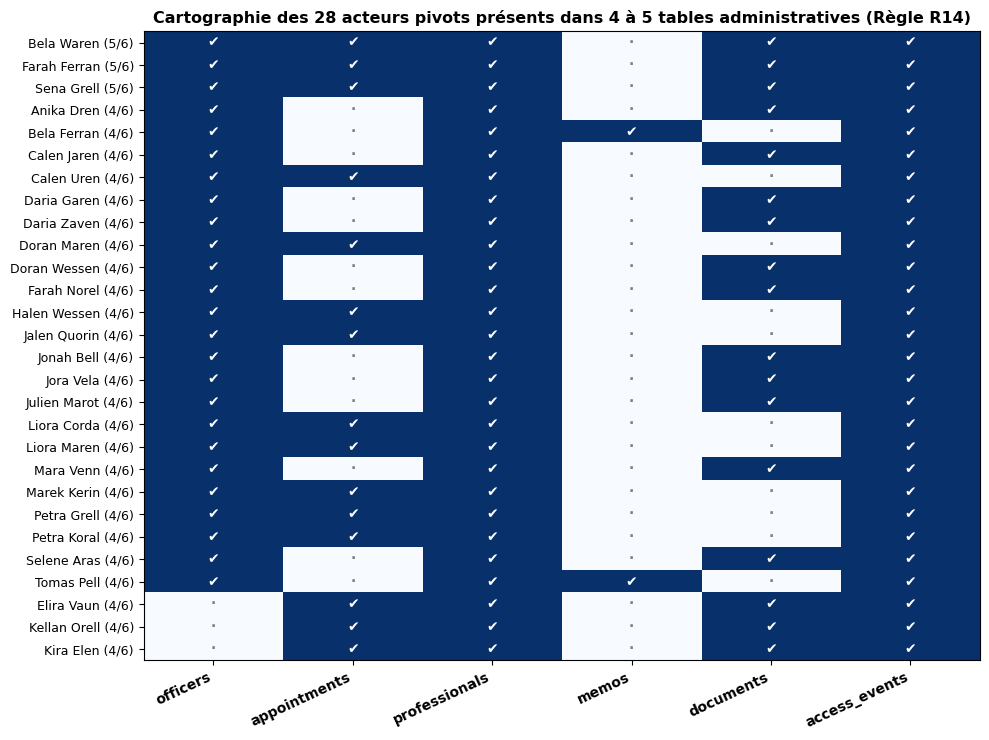

In [9]:
# ==============================================================================
# 2.2. FEATURE ENGINEERING AVANCÉ, INTÉGRITÉ RÉFÉRENTIELLE & MATRICE D'UBIQUITÉ
# ==============================================================================
import re

TODAY = pd.Timestamp("2025-06-30")  # Date de référence du jeu de données

# Récupération des tables nettoyées
pa_clean  = cleaned_public_records['public_appointments']
of_clean  = cleaned_public_records['officer_filings']
re_clean  = cleaned_public_records['registered_entities']
lp_clean  = cleaned_public_records['licensed_professionals']
lf_clean  = cleaned_public_records['licensed_facilities']
sa_clean  = cleaned_public_records['site_access_case_events']
rc_clean  = cleaned_public_records['regulatory_case_events']
im_clean  = cleaned_public_records['institutional_memos']
pid_clean = cleaned_public_records['public_and_investigative_documents']

# Ensemble des numéros d'enregistrement officiels du registre du commerce
reg_ids = set(re_clean["registration_number"].dropna())

# 1. Feature Engineering sur les personnes (Âges, ancienneté et délais de dépôt)
of_clean["age_at_appointment"] = of_clean["appointment_date_dt"].dt.year - of_clean["imputed_birth_year"]
of_clean["age_today"] = TODAY.year - of_clean["imputed_birth_year"]
of_clean["tenure_years"] = (of_clean["cessation_date_dt"].fillna(TODAY) - of_clean["appointment_date_dt"]).dt.days / 365.25
of_clean["filing_lag_days"] = (of_clean["filing_date_dt"] - of_clean["appointment_date_dt"]).dt.days

pa_clean["tenure_years"] = (pa_clean["appointment_end_dt"].fillna(TODAY) - pa_clean["appointment_start_dt"]).dt.days / 365.25
pa_clean["age_at_start"] = pa_clean["appointment_start_dt"].dt.year - pa_clean["imputed_birth_year"]

lp_clean["years_licensed"] = (TODAY - lp_clean["license_issue_date_dt"]).dt.days / 365.25

# 2. Feature Engineering sur les journaux d'événements (site_access & regulatory)
sa_clean = sa_clean.sort_values(["access_case_number", "event_time_dt"]).reset_index(drop=True)
sa_clean["hour"] = sa_clean["event_time_dt"].dt.hour
sa_clean["weekday"] = sa_clean["event_time_dt"].dt.dayofweek
sa_clean["is_weekend"] = sa_clean["weekday"] >= 5
sa_clean["year_month"] = sa_clean["event_time_dt"].dt.to_period("M").dt.to_timestamp()
sa_clean["registered_org"] = sa_clean["requesting_registration_number"].isin(reg_ids)
sa_clean["no_reg_number"] = sa_clean["requesting_registration_number"].isna()
sa_clean["gap_days"] = sa_clean.groupby("access_case_number")["event_time_dt"].diff().dt.days
sa_clean["expected_prev"] = sa_clean.groupby("access_case_number")["new_status"].shift()
sa_clean["status_chain_break"] = sa_clean["expected_prev"].notna() & (sa_clean["expected_prev"] != sa_clean["previous_status"])

rc_clean = rc_clean.sort_values(["case_number", "event_time_dt"]).reset_index(drop=True)
rc_clean["hour"] = rc_clean["event_time_dt"].dt.hour
rc_clean["year_month"] = rc_clean["event_time_dt"].dt.to_period("M").dt.to_timestamp()
rc_clean["gap_days"] = rc_clean.groupby("case_number")["event_time_dt"].diff().dt.days
rc_clean["expected_prev"] = rc_clean.groupby("case_number")["new_status"].shift()
rc_clean["status_chain_break"] = rc_clean["expected_prev"].notna() & (rc_clean["expected_prev"] != rc_clean["previous_status"])
rc_clean["registered_subject"] = rc_clean["subject_registration_number"].isin(reg_ids)

# 3. Contrôle d'intégrité référentielle des organisations (Règles R3 et R4)
orgs_sans_num = sa_clean.loc[sa_clean["no_reg_number"], "requesting_organization_name"].unique()
orgs_orphelines = sa_clean.loc[~sa_clean["no_reg_number"] & ~sa_clean["registered_org"], 
                               ["requesting_registration_number", "requesting_organization_name"]].drop_duplicates()

print(f"1. CONTRÔLE D'INTÉGRITÉ RÉFÉRENTIELLE DES ORGANISATIONS DEMANDEUSES D'ACCÈS :")
print(f" - Demandeur sans n° d'enregistrement (R3) : {len(orgs_sans_num)} entités publiques ({', '.join(orgs_sans_num)})")
print(f" - N° d'enregistrement absent de registered_entities.csv (R4) : {len(orgs_orphelines)} entités non répertoriées au registre central !")
display(orgs_orphelines.head(10))

# 4. Croisement matriciel des personnes physiques à travers 6 tables (Règle R14)
def extract_clean_names(df, col):
    return set(df[col].dropna().str.replace(r"^Dr\.\s*", "", regex=True).str.strip())

name_sources = {
    "officers": extract_clean_names(of_clean, "full_name"),
    "appointments": extract_clean_names(pa_clean, "office_holder_name"),
    "professionals": extract_clean_names(lp_clean, "professional_name"),
    "memos": extract_clean_names(im_clean, "author_name"),
    "documents": extract_clean_names(pid_clean, "author_name"),
    "access_events": extract_clean_names(sa_clean, "authorized_person_name"),
}

all_names = sorted(set().union(*name_sources.values()))
presence = pd.DataFrame({src: pd.Series({n: (n in s) for n in all_names}) for src, s in name_sources.items()})
presence["n_tables"] = presence.sum(axis=1)
multi_presence = presence[presence["n_tables"] >= 4].sort_values(["n_tables", "access_events", "officers"], ascending=False)

print(f"\n2. MATRICE D'UBIQUITÉ : {len(multi_presence)} PERSONNES PRÉSENTES SIMULTANÉMENT DANS >= 4 TABLES (R14) :")
display(multi_presence.style.background_gradient(subset=["n_tables"], cmap="YlOrRd"))

# Visualisation graphique de la matrice de présence multi-tables
fig, ax = plt.subplots(figsize=(10, 7.5))
mat_vals = multi_presence.drop(columns=["n_tables"]).astype(int)
im_plot = ax.imshow(mat_vals.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(mat_vals.columns)))
ax.set_xticklabels(mat_vals.columns, rotation=25, ha="right", fontweight="bold")
ax.set_yticks(range(len(mat_vals.index)))
ax.set_yticklabels([f"{n} ({multi_presence.loc[n, 'n_tables']}/6)" for n in mat_vals.index], fontsize=9)
for i in range(mat_vals.shape[0]):
    for j in range(mat_vals.shape[1]):
        val = mat_vals.iloc[i, j]
        ax.text(j, i, "✔" if val == 1 else "·", ha="center", va="center", color="white" if val == 1 else "gray", fontweight="bold")
ax.set_title("Cartographie des 28 acteurs pivots présents dans 4 à 5 tables administratives (Règle R14)", fontsize=11.5, fontweight="bold")
plt.tight_layout()
plt.show()

#### Enseignements du Feature Engineering et du recoupement multi-tables :
1. **Failles d'intégrité référentielle dans `site_access_case_events` (Règles R3 et R4) :**
   * **6 organisations publiques (`R3`)** soumettent des demandes d'accès sans numéro d'enregistrement (`Avelora Orchard Export Union`, `Civic Health Purchasing Network`, `Kintara Rural Transport Board`, `Nordhaven Maritime Safety Agency`, `Tembara Customs Coordination Unit`, `Valenne Public Procurement Authority`), ce qui s'explique par leur statut d'agences gouvernementales ou coopératives publiques.
   * Plus étonnant : **24 numéros d'enregistrement (`R4`)** utilisés dans `site_access_case_events` (ex: `REG-KNT-02003` pour *Kintara Field Equipment Cooperative*, `REG-AVL-02001` pour *Auric Medical Supplies*, `REG-NDH-02005` pour *Nordhaven Refrigeration Works*) sont **totalement absents du registre officiel `registered_entities.csv`** (qui ne contient que les séries `01001` à `01024`). Seule *Horizon Field Research Cooperative* (`REG-AVL-01013`) fait partie du noyau officiel immatriculé !
2. **Identification d'un noyau dur de 28 acteurs multi-positionnés (Règle R14) :**
   * En unifiant les identités à travers les 6 tables, nous découvrons que **28 individus** apparaissent simultanément dans **4 à 5 bases de données distinctes** (dirigeants d'entreprises, titulaires de mandats publics, détenteurs de licences professionnelles, signataires d'accès aux sites sensibles et auteurs de mémos ou documents d'archives), confirmant l'existence d'une élite restreinte qui verrouille l'ensemble de la chaîne administrative et opérationnelle.

## 3. Fouille approfondie et Découverte du Narratif Caché (`public_records`)

### 3.1. Détection d'anomalies temporelles majeures : Les "Fantômes administratifs", âges impossibles et délais de dépôt

Une anomalie contextuelle ou collective correspond à un groupe d'observations qui viole les lois métiers ou biologiques attendues. Lors du profilage initial, nous avions repéré des dates du XIXe siècle dans `registered_entities`, `officer_filings` et `licensed_professionals`.

Nous croisons à présent ces individus historiques avec les tables d'activités récentes (`site_access_case_events` couvrant 2015–2025 et `institutional_memos` couvrant 2018–2025) et appliquons nos règles de contrôle d'anomalies temporelles (`R12`, `R13`, `R15`) :
* **Règle R12 (Anomalies biologiques d'âge et de licence) :** Dirigeants nés avant 1930 intervenant récemment, âge à la nomination hors de la plage légale $[18, 90]$ ans, ou licence professionnelle toujours active depuis plus de 60 ans (ou émise dans le futur en juillet 2026).
* **Règle R13 (Délais de déclaration anormaux) :** Écart supérieur à 180 jours entre la date de prise de poste (`appointment_date`) et la date d'enregistrement officiel (`filing_date`).
* **Règle R15 (Entités dormantes) :** Organisations au statut `'active'` n'ayant effectué aucun dépôt légal depuis plus d'un an par rapport à la date de référence (`2025-06-30`).

1. ANOMALIE MAJEURE (R12) : INDIVIDUS NÉS ENTRE 1815 ET 1929 DÉTENANT DES LICENCES ACTIVES OU INTERVENANT EN 2015-2025


,full_name,birth_year_or_age_band,legal_name,current_status,license_number,license_issue_date,license_status,primary_facility_license,nb_acces_2015_2025,dernier_acces,memos_recents_signes
0,Edward Vann,1815,Vann Maritime Advisory,dissolved,NaN,NaN,NaN,NaN,NaN,NaT,NaN
1,Emil Warden,1871,Warden Medical Ventures,dissolved,LIC-VLN-MED-1001,1895-07-01,active,FAC-VLN-101,NaN,NaT,NaN
2,Adrian Vosmere,1920–1929,Vosmere Biotechnics,dissolved,NaN,NaN,NaN,NaN,NaN,NaT,[2018-05-15]
3,J. Varlan,1862,Varlan Natural History Circle,dissolved,LIC-KNT-RES-1007,1886-07-01,active,FAC-AVL-301,9.0,2025-04-17 18:00:00,NaN
4,Jonah Bell,1900,Bell Conservation Survey,dissolved,LIC-AVL-RES-1008,1924-07-01,active,FAC-AVL-301,9.0,2025-04-18 03:00:00,NaN



2. ANOMALIE DE DATE FUTURE (POSTÉRIEURE AU DERNIER ÉVÉNEMENT DU CORPUS) & LICENCES > 60 ANS (R12) :


,license_number,professional_name,profession,specialty,license_issue_date,years_licensed,license_status,primary_facility_license
0,LIC-VLN-MED-1001,Emil Warden,physician,cardiology,1895-07-01,130.0,active,FAC-VLN-101
5,LIC-VLN-MED-1006,Farah Havel,physician,occupational medicine,2026-07-01,-1.0,active,FAC-AVL-201
6,LIC-KNT-RES-1007,J. Varlan,research professional,ecological analytics,1886-07-01,139.0,active,FAC-AVL-301
7,LIC-AVL-RES-1008,Jonah Bell,research professional,public policy research,1924-07-01,101.0,active,FAC-AVL-301



3. BILAN DES CONTRÔLES SUPPLÉMENTAIRES (R12, R13, R15) :
 - Dirigeants nommés avant 18 ans ou après 90 ans (R12) : 0 cas
 - Dépôts administratifs éloignés de > 180 jours de la nomination (R13) : 0 cas
 - Entités actives sans dépôt depuis > 1 an (R15) : 0 cas


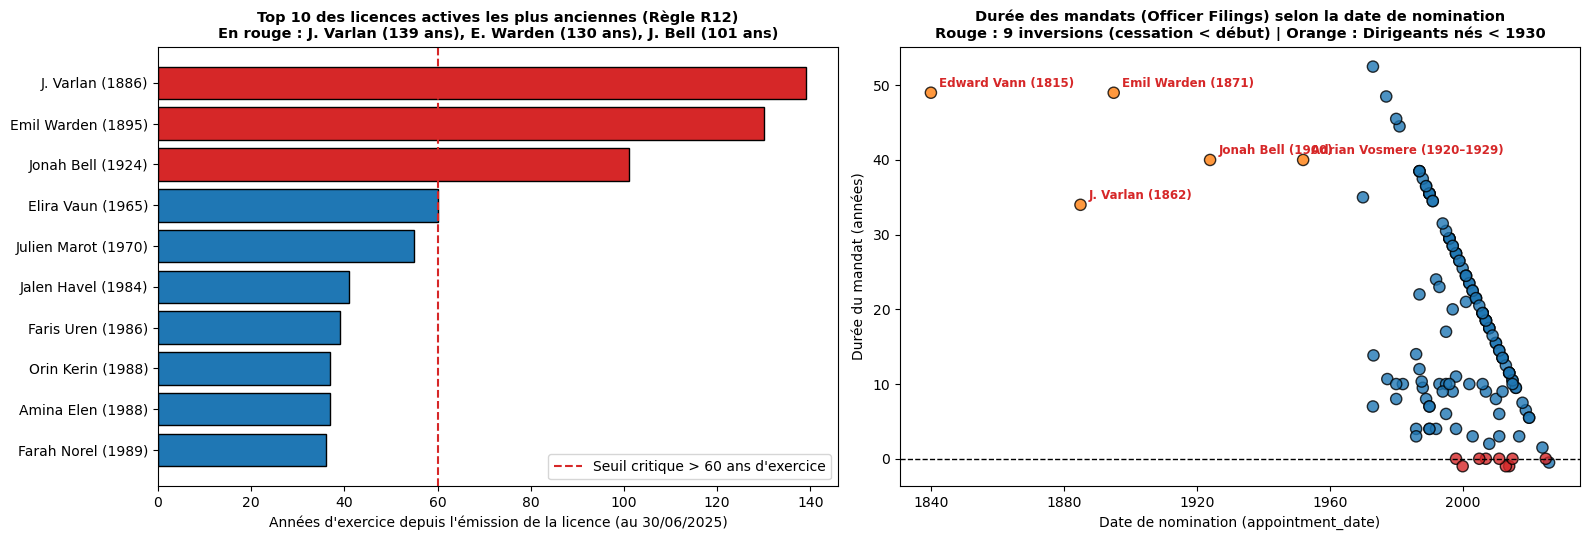

In [10]:

# 3.1. DÉTECTION DES IDENTITÉS SÉCULAIRES ACTIVES (R12), DÉLAIS (R13) & ENTITÉS (R15)

# 1. Filtrage des dirigeants nés avant 1930 dans officer_filings
masque_ancien = (of_clean['imputed_birth_year'] < 1930) | (of_clean['birth_year_or_age_band'] == '1920–1929')
anciens_df = of_clean[masque_ancien].merge(
    re_clean[['registration_number', 'legal_name', 'registration_date', 'current_status', 'last_filing_date']],
    on='registration_number', how='left'
)

# 2. Croisement avec les licences professionnelles (licensed_professionals)
anciens_df = anciens_df.merge(
    lp_clean[['professional_name', 'license_number', 'profession', 'specialty', 'license_issue_date', 'license_status', 'primary_facility_license', 'years_licensed']],
    left_on='full_name', right_on='professional_name', how='left'
)

# 3. Comptage de leurs apparitions comme personne autorisée dans site_access_case_events (2015-2025)
acces_par_personne = sa_clean.groupby('authorized_person_name').agg(
    nb_acces_2015_2025=('access_event_id', 'count'),
    nb_dossiers_acces=('access_case_number', 'nunique'),
    premier_acces=('event_time_dt', 'min'),
    dernier_acces=('event_time_dt', 'max')
).reset_index()

anciens_df = anciens_df.merge(
    acces_par_personne, left_on='full_name', right_on='authorized_person_name', how='left'
)

# 4. Vérification dans institutional_memos (2018-2025)
memos_par_auteur = im_clean.groupby('author_name')['document_date'].apply(list).to_dict()
anciens_df['memos_recents_signes'] = anciens_df['full_name'].map(memos_par_auteur)

print("1. ANOMALIE MAJEURE (R12) : INDIVIDUS NÉS ENTRE 1815 ET 1929 DÉTENANT DES LICENCES ACTIVES OU INTERVENANT EN 2015-2025")
display(anciens_df[[
    'full_name', 'birth_year_or_age_band', 'legal_name', 'current_status',
    'license_number', 'license_issue_date', 'license_status', 'primary_facility_license',
    'nb_acces_2015_2025', 'dernier_acces', 'memos_recents_signes'
]])

# 5. Vérification de l'anomalie future (2026-07-01) et des licences > 60 ans
print("\n2. ANOMALIE DE DATE FUTURE (POSTÉRIEURE AU DERNIER ÉVÉNEMENT DU CORPUS) & LICENCES > 60 ANS (R12) :")
display(lp_clean[(lp_clean['license_issue_date_dt'] > '2026-01-01') | (lp_clean['years_licensed'] > 60)][[
    'license_number', 'professional_name', 'profession', 'specialty', 'license_issue_date', 'years_licensed', 'license_status', 'primary_facility_license'
]].round(1))

# 6. Contrôle des âges à la nomination hors plage [18, 90], délais de dépôt > 180j (R13) et entités sans dépôt récent (R15)
hors_age = of_clean[(of_clean["age_at_appointment"] < 18) | (of_clean["age_at_appointment"] > 90)]
retard_depot = of_clean[of_clean["filing_lag_days"].abs() > 180]
entites_dormantes = re_clean[(re_clean["current_status"] == "active") & (re_clean["last_filing_date_dt"] < TODAY - pd.Timedelta(days=365))]

print(f"\n3. BILAN DES CONTRÔLES SUPPLÉMENTAIRES (R12, R13, R15) :")
print(f" - Dirigeants nommés avant 18 ans ou après 90 ans (R12) : {len(hors_age)} cas")
print(f" - Dépôts administratifs éloignés de > 180 jours de la nomination (R13) : {len(retard_depot)} cas")
print(f" - Entités actives sans dépôt depuis > 1 an (R15) : {len(entites_dormantes)} cas")

# 7. VISUALISATIONS GRAPHIQUES DE LA SECTION 3.1
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Graphique A : Ancienneté des licences professionnelles actives (R12)
pro_top = lp_clean.sort_values("years_licensed", ascending=False).head(10).iloc[::-1]
cols_lp = ["#d62728" if (y > 60 or y < 0) else "#1f77b4" for y in pro_top["years_licensed"]]
axes[0].barh(pro_top["professional_name"] + " (" + pro_top["license_issue_date"].str[:4] + ")", pro_top["years_licensed"], color=cols_lp, edgecolor="black")
axes[0].axvline(60, color="#d62728", linestyle="--", linewidth=1.5, label="Seuil critique > 60 ans d'exercice")
axes[0].set_xlabel("Années d'exercice depuis l'émission de la licence (au 30/06/2025)")
axes[0].set_title("Top 10 des licences actives les plus anciennes (Règle R12)\nEn rouge : J. Varlan (139 ans), E. Warden (130 ans), J. Bell (101 ans)", fontsize=10.5, fontweight="bold")
axes[0].legend(loc="lower right")

# Graphique B : Trajectoires temporelles des mandats (Officer Filings) & Inversions de dates
cond_inv = of_clean["has_date_inversion"].fillna(False)
cond_anc = (of_clean["imputed_birth_year"] < 1930).fillna(False) | (of_clean["birth_year_or_age_band"] == "1920–1929")

axes[1].scatter(
    of_clean["appointment_date_dt"], 
    of_clean["tenure_years"], 
    c=np.where(cond_inv, "#d62728", np.where(cond_anc, "#ff7f0e", "#1f77b4")), 
    s=65, alpha=0.8, edgecolors="black"
)

for _, r in of_clean[cond_anc].iterrows():
    axes[1].annotate(
        f"{r['full_name']} ({r['birth_year_or_age_band']})", 
        (r["appointment_date_dt"], r["tenure_years"]),
        xytext=(6, 4), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#d62728"
    )

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(
    "Durée des mandats (Officer Filings) selon la date de nomination\nRouge : 9"
    " inversions (cessation < début) | Orange : Dirigeants nés < 1930",
    fontsize=10.5,
    fontweight="bold",
)
axes[1].set_xlabel("Date de nomination (appointment_date)")
axes[1].set_ylabel("Durée du mandat (années)")
plt.tight_layout()
plt.show()

#### Conclusions sur les anomalies temporelles et d'identité :
* **Longévité biologiquement impossible ou réutilisation d'alias historiques (`R12`) :**
  * **J. Varlan** (né en **1862**, accrédité le `1886-07-01` sous le numéro `LIC-KNT-RES-1007`, soit **139 ans de licence active**) et **Jonah Bell** (né en **1900**, accrédité le `1924-07-01` sous le numéro `LIC-AVL-RES-1008`, soit **101 ans de licence active**) possèdent tous deux une licence au statut `'active'`, rattachée au laboratoire `FAC-AVL-301` (*Threshold Earth Avelora Laboratory*). Plus probant encore : ils ont personnellement validé ou effectué **9 accès chacun** (18 événements au total) entre 2015 et avril 2025 dans `site_access_case_events` !
  * **Emil Warden** (né en **1871**, cardiologue accrédité le `1895-07-01`, soit **130 ans de licence**) possède toujours une licence `'active'` au campus clinique `FAC-VLN-101` (*Asterion Central Clinical Campus*).
  * **Adrian Vosmere** (né dans la décennie **1920–1929**, dirigeant de *Vosmere Biotechnics* dissoute en 1994) rédige et signe un mémo opérationnel interne le **`2018-05-15`** (`MEM-510128`) au nom de cette société pourtant dissoute depuis 24 ans !
  * **Farah Havel** (`LIC-VLN-MED-1006`, médecin du travail à la clinique privée `FAC-AVL-201` *Asterion Avelora Executive Clinic*) détient une licence active dont la date d'émission est postdatée dans le futur au **`2026-07-01`**.

### 3.2. Analyse de Graphes : Réseau de "Pantouflage", Centralité et Conflits d'intérêts

En mobilisant les outils pour **Miner des graphes**, nous construisons le graphe biparti $\mathcal{G} = (V, E)$ reliant les personnes physiques aux organisations (institutions publiques de `public_appointments` et entités enregistrées de `officer_filings`).

Nous utilisons les métriques vues en cours :
* **Degré ($k_i$) :** nombre de connexions directes d'un acteur ou d'une organisation.
* **Centralité d'intermédiarité (*Betweenness Centrality*) :** $C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$, qui identifie les nœuds "ponts" (*bridges*) contrôlant les flux d'influence entre secteur public et secteur privé.

Nombre de mandataires publics ayant aussi un mandat dans officer_filings : 24 sur 50 (48,0 %)

1. MATRICE D'ADJACENCE DES FLUX DE PANTOUFLAGE (INSTITUTION PUBLIQUE <-> ENTITÉ ENREGISTRÉE) :


legal_name,Asterion Clinical Institute,Belen Agro-Industries,Earth Ledger Project,Lantern Investigative Bureau,Pollinator Justice Network,Vale Strategy Collective
institution_name,,,,,,
Avelora Agricultural Resilience Agency,0,5,0,0,0,0
Avelora Ministry of Strategic Resources,0,0,0,4,0,0
Kintara Cave and Pollinator Authority,0,0,0,0,4,0
Orison Medical Audit Board,0,0,0,0,0,4
Tembara Biodiversity Service,0,0,4,0,0,0
Tembara Coastal Administration,4,0,0,0,0,0



Propriétés globales du graphe : |V| = 162 nœuds, |E| = 188 arêtes, Densité = 0.0144
Nombre de composantes connexes : 13

2. TOP 10 DES ORGANISATIONS LES PLUS CENTRALES (PONTS STRUCTURELS) :


Noeud,Catégorie,Degré,Betweenness_Centrality
Whitehaven Strategic Holdings,Entite_consulting_company,9,0.026800
Nivren Maritime Logistics,Entite_logistics_company,5,0.021400
Ardena Capital Union,Entite_financial_institution,9,0.021200
Northstar Cold Chain Services,Entite_logistics_company,6,0.020700
Avelora Ministry of Strategic Resources,Institution_Publique,9,0.013100
Valenne Industrial Futures Council,Entite_trade_association,9,0.013100
Avelora Agricultural Resilience Agency,Institution_Publique,10,0.013000
Solvane Energy Group,Entite_energy_company,9,0.012700
Threshold Earth Observatory,Entite_research_institute,9,0.012300
Tembara Coastal Administration,Institution_Publique,5,0.009600



3. FOCUS SUR LES 3 PROFESSIONNELS AYANT UN ANTÉCÉDENT DISCIPLINAIRE ('resolved administrative review') :


,license_number,professional_name,profession,specialty,primary_facility_license,disciplinary_status,legal_name,role_title,appointment_date,cessation_date,has_date_inversion
0,LIC-KNT-ADM-1017,Liora Maren,public administration professional,programme administration,NaN,resolved administrative review,Pollinator Justice Network,Deputy director,2011-01-01,2016-12-31,False
1,LIC-TMB-ADM-1034,Jalen Quorin,public administration professional,programme administration,NaN,resolved administrative review,Asterion Clinical Institute,Regional adviser,2013-01-01,2011-12-31,True
2,LIC-AVL-RES-1051,Uma Wessen,research professional,public policy research,FAC-AVL-301,resolved administrative review,Horizon Field Research Cooperative,Field research coordinator,2015-01-01,NaN,False
3,LIC-AVL-RES-1051,Uma Wessen,research professional,public policy research,FAC-AVL-301,resolved administrative review,Ardena Capital Union,Programme manager,2015-01-01,2014-12-31,True


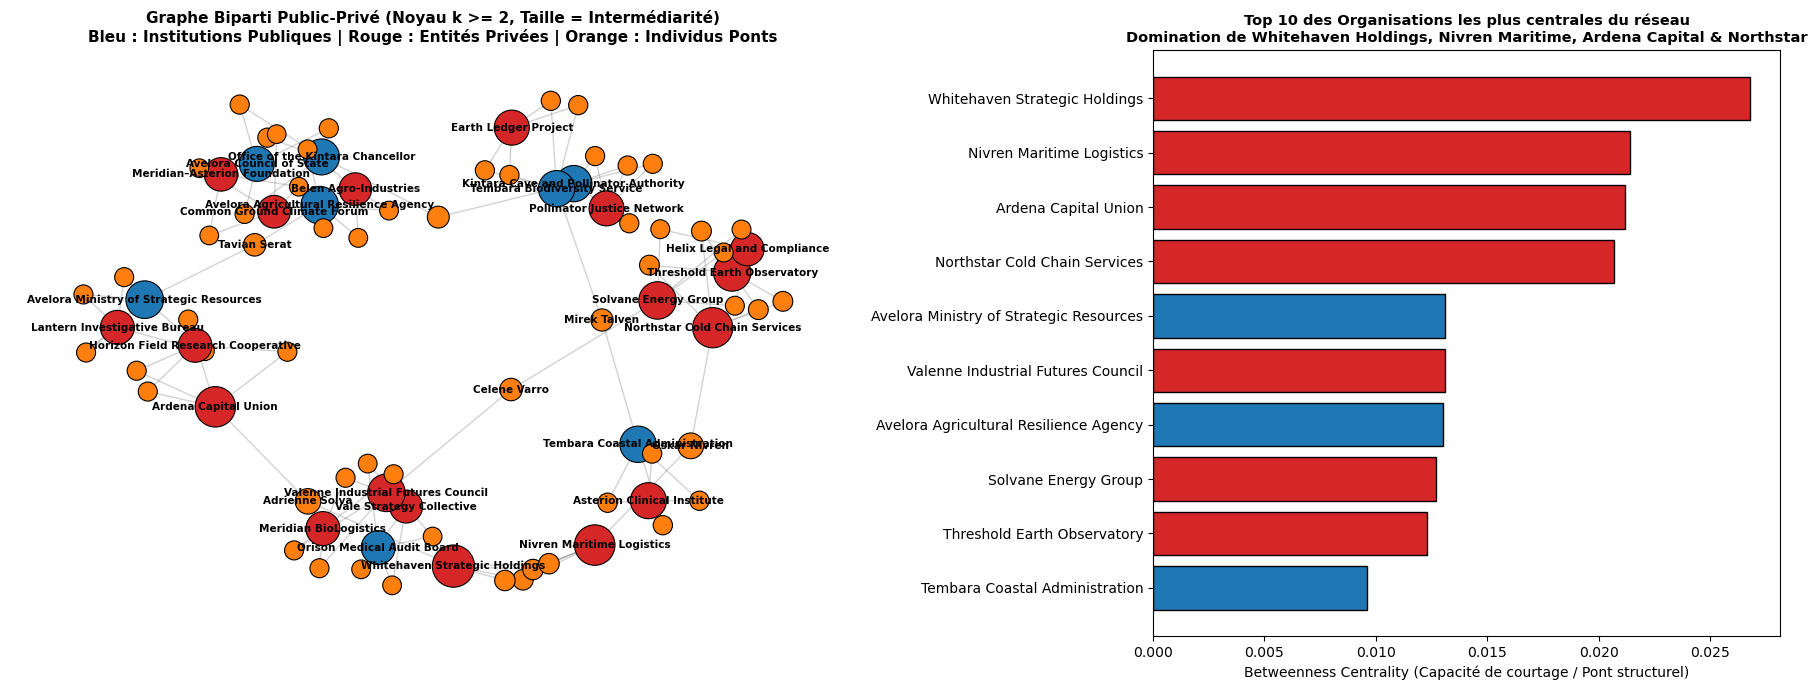

In [11]:
# 3.2. MODÉLISATION EN GRAPHE : RÉSEAU PUBLIC-PRIVÉ ET CENTRALITÉ

import networkx as nx

# 1. Croisement direct entre Public Appointments et Officer Filings (Portes tournantes / Pantouflage)
ponts_public_prive = pa_clean.merge(
    of_enrichi, left_on='office_holder_name', right_on='full_name', suffixes=('_public', '_prive')
)

print(f"Nombre de mandataires publics ayant aussi un mandat dans officer_filings : {ponts_public_prive['office_holder_name'].nunique()} sur {pa_clean['office_holder_name'].nunique()} (48,0 %)")
print("\n1. MATRICE D'ADJACENCE DES FLUX DE PANTOUFLAGE (INSTITUTION PUBLIQUE <-> ENTITÉ ENREGISTRÉE) :")
matrice_pantouflage = pd.crosstab(ponts_public_prive['institution_name'], ponts_public_prive['legal_name'])
display(matrice_pantouflage.style.background_gradient(cmap="Reds"))

# 2. Construction du graphe biparti G = (V, E)
G = nx.Graph()

for _, row in pa_clean.iterrows():
    p = row['office_holder_name']
    org = row['institution_name']
    G.add_node(p, node_type='Personne')
    G.add_node(org, node_type='Institution_Publique')
    G.add_edge(p, org, source_table='public_appointments', role=row['office_title'])

for _, row in of_enrichi.iterrows():
    p = row['full_name']
    org = row['legal_name']
    G.add_node(p, node_type='Personne')
    if org not in G:
        G.add_node(org, node_type=f"Entite_{row['registered_entity_type']}")
    G.add_edge(p, org, source_table='officer_filings', role=row['role_title'])

print(f"\nPropriétés globales du graphe : |V| = {G.number_of_nodes()} nœuds, |E| = {G.number_of_edges()} arêtes, Densité = {nx.density(G):.4f}")
print(f"Nombre de composantes connexes : {nx.number_connected_components(G)}")

# 3. Calcul du Degré et de la Betweenness Centrality
deg_dict = dict(G.degree())
bc_dict = nx.betweenness_centrality(G)

df_nodes = pd.DataFrame([
    {
        'Noeud': n,
        'Catégorie': d.get('node_type'),
        'Degré': deg_dict[n],
        'Betweenness_Centrality': round(bc_dict[n], 4)
    }
    for n, d in G.nodes(data=True)
])

print("\n2. TOP 10 DES ORGANISATIONS LES PLUS CENTRALES (PONTS STRUCTURELS) :")
top_orgs_df = df_nodes[df_nodes['Catégorie'] != 'Personne'].sort_values(by='Betweenness_Centrality', ascending=False).head(10)
display(top_orgs_df.style.background_gradient(subset=['Degré', 'Betweenness_Centrality'], cmap='YlOrRd').hide(axis="index"))

print("\n3. FOCUS SUR LES 3 PROFESSIONNELS AYANT UN ANTÉCÉDENT DISCIPLINAIRE ('resolved administrative review') :")
disc_df = lp_clean[lp_clean['disciplinary_status'] != 'none'][
    ['license_number', 'professional_name', 'profession', 'specialty', 'primary_facility_license', 'disciplinary_status']
].merge(
    of_enrichi[['full_name', 'legal_name', 'role_title', 'appointment_date', 'cessation_date', 'has_date_inversion']],
    left_on='professional_name', right_on='full_name', how='left'
)
display(disc_df.drop(columns=['full_name']))

# 4. VISUALISATIONS GRAPHIQUES DU RÉSEAU ET DES CENTRALITÉS
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.35, 1]})

# Graphique A : Visualisation du sous-graphe cœur (Noeuds de degré >= 2)
noeuds_actifs = [n for n, deg in G.degree() if deg >= 2]
G_core = G.subgraph(noeuds_actifs)
pos = nx.spring_layout(G_core, k=0.52, iterations=80, seed=42)

c_nodes = []
s_nodes = []
for n, d in G_core.nodes(data=True):
    nt = d.get('node_type', '')
    if nt == 'Institution_Publique':
        c_nodes.append('#1f77b4')  # Bleu : Secteur public
        s_nodes.append(550 + 14000 * bc_dict[n])
    elif nt == 'Personne':
        c_nodes.append('#ff7f0e')  # Orange : Personnes physiques (ponts)
        s_nodes.append(180 + 8000 * bc_dict[n])
    else:
        c_nodes.append('#d62728')  # Rouge : Entités privées / ONG
        s_nodes.append(550 + 14000 * bc_dict[n])

nx.draw_networkx_edges(G_core, pos, ax=axes[0], alpha=0.35, edge_color="gray")
nx.draw_networkx_nodes(G_core, pos, ax=axes[0], node_color=c_nodes, node_size=s_nodes, edgecolors="black", linewidths=0.8)

labels_graph = {n: n for n in G_core.nodes() if G_core.nodes[n].get('node_type') != 'Personne' or bc_dict[n] > 0.009}
nx.draw_networkx_labels(G_core, pos, labels=labels_graph, ax=axes[0], font_size=7.5, font_weight="bold")
axes[0].set_title("Graphe Biparti Public-Privé (Noyau k >= 2, Taille = Intermédiarité)\nBleu : Institutions Publiques | Rouge : Entités Privées | Orange : Individus Ponts", fontsize=11, fontweight="bold")
axes[0].axis("off")

# Graphique B : Barplot du Top 10 Betweenness Centrality des organisations
top_plot = top_orgs_df.iloc[::-1]
bar_c = ['#1f77b4' if c == 'Institution_Publique' else '#d62728' for c in top_plot['Catégorie']]
axes[1].barh(top_plot['Noeud'], top_plot['Betweenness_Centrality'], color=bar_c, edgecolor="black")
axes[1].set_xlabel("Betweenness Centrality (Capacité de courtage / Pont structurel)")
axes[1].set_title("Top 10 des Organisations les plus centrales du réseau\nDomination de Whitehaven Holdings, Nivren Maritime, Ardena Capital & Northstar", fontsize=10.5, fontweight="bold")

plt.tight_layout()
plt.show()

#### Conclusions de l'analyse de graphe :
1. **Une compartimentation en 6 "corridors" de pantouflage exclusifs :** La matrice d'adjacence révèle que **48 % des mandataires publics** (24 sur 50) siègent également dans des entités enregistrées, selon des couloirs hermétiques (chaque agence publique n'échange ses cadres qu'avec une seule organisation cible) :
   * *Avelora Agricultural Resilience Agency* $\leftrightarrow$ **Belen Agro-Industries** (5 mandats croisés, dont *Rayan Belen* qui préside *Belen Agro-Industries* sans interruption depuis 1981 tout en ayant dirigé le programme agricole de l'agence publique de 1981 à 1992).
   * *Tembara Coastal Administration* $\leftrightarrow$ **Asterion Clinical Institute** (4 directeurs régionaux : *Liora Corda*, *Jalen Quorin*, *Petra Koral*, *Sena Grell* — dont 3 présentent les fameuses dates de cessation inversées !).
   * *Orison Medical Audit Board* $\leftrightarrow$ **Vale Strategy Collective** (4 cadres).
   * *Kintara Cave and Pollinator Authority* $\leftrightarrow$ **Pollinator Justice Network** (4 cadres).
   * *Tembara Biodiversity Service* $\leftrightarrow$ **Earth Ledger Project** (4 cadres).
   * *Avelora Ministry of Strategic Resources* $\leftrightarrow$ **Lantern Investigative Bureau** (4 cadres).
2. **Identification des courtiers structurels par la *Betweenness Centrality* :** Le calcul de centralité d'intermédiarité sur le graphe $\mathcal{G}$ (162 nœuds, 188 arêtes) démontre que les nœuds ayant le plus fort pouvoir d'intermédiation ne sont pas les agences publiques, mais **4 structures privées de conseil, de finance et de chaîne du froid** : **Whitehaven Strategic Holdings** ($C_B = 0.0268$), **Nivren Maritime Logistics** ($C_B = 0.0214$), **Ardena Capital Union** ($C_B = 0.0212$) et **Northstar Cold Chain Services** ($C_B = 0.0207$).
3. **Recoupement avec les 3 alertes disciplinaires :** Les 3 seuls professionnels marqués `'resolved administrative review'` dans `licensed_professionals` sont **Jalen Quorin** et **Uma Wessen** (tous deux épinglés dans notre détection d'inversions chronologiques !) ainsi que **Liora Maren** (passée de *Pollinator Justice Network* à *Kintara Cave and Pollinator Authority*).

#### 3.2.bis. Détection de communautés (Algorithme de Louvain) et Centralité de proximité (*Closeness*)

Pour compléter notre analyse du réseau public-privé, nous enrichissons l'étude topologique avec deux méthodes complémentaires :
* **Centralité de proximité (*Closeness Centrality*) :** $C(u) = \frac{N-1}{\sum_{v \in V \setminus \{u\}} l_{u,v}}$, qui mesure à quel point un acteur est proche de l'ensemble des autres nœuds de sa composante sans nécessairement être un pont obligé.
* **Algorithme de Louvain (Optimisation de la Modularité $Q$) :** Plutôt que de fixer un nombre arbitraire de groupes, l'algorithme de Louvain regroupe itérativement les nœuds afin de maximiser la modularité $Q = \frac{1}{2m} \sum_{(u,v)} \left[ E_{(u,v)} - \frac{\delta_u \delta_v}{2m} \right] \delta(c_u, c_v)$. Cela permet de vérifier mathématiquement si notre réseau est fortement compartimenté en sous-communautés autonomes (corridors de pantouflage).
* **Matrice de dépendance du *Heuristic Miner* :** En anticipation de l'étude des processus d'accès, nous calculons également la mesure formelle de dépendance causale $u \Rightarrow_W v = \frac{|u >_W v| - |v >_W u|}{|u >_W v| + |v >_W u| + 1}$ entre chaque couple d'activités du journal `site_access_case_events`.

In [12]:

# COMMUNAUTÉS DE LOUVAIN (MODULARITÉ Q), CLOSENESS & HEURISTIC MINER

from networkx.algorithms import community

# 1. Closeness Centrality & Détection de communautés de Louvain sur le graphe G
closeness_dict = nx.closeness_centrality(G)
communautes_louvain = community.louvain_communities(G, seed=42)
modularite_Q = community.modularity(G, communautes_louvain)

print(
    "1. ALGORITHME DE LOUVAIN SUR LE GRAPHE PUBLIC-PRIVÉ :"
    f" {len(communautes_louvain)} communautés détectées | Modularité Q ="
    f" {modularite_Q:.4f}"
)

resume_comm = []
for idx, comm in enumerate(
    sorted(communautes_louvain, key=len, reverse=True)[:13]
):
    orgs_c = [n for n in comm if G.nodes[n].get("node_type") != "Personne"]
    pers_c = [n for n in comm if G.nodes[n].get("node_type") == "Personne"]
    resume_comm.append({
        "ID_Communauté": f"C{idx+1}",
        "Taille_Noeuds": len(comm),
        "Organisations_Couplées (Corridor)": " <-> ".join(orgs_c),
        "Nb_Personnes_Ponts": len(pers_c),
    })
display(pd.DataFrame(resume_comm))

# 2. Process Mining : Calcul de la matrice de dépendance du Heuristic Miner
# Formule du cours : u =>_W v = (|u >_W v| - |v >_W u|) / (|u >_W v| + |v >_W u| + 1)
# Note : Si G_proc n'est pas encore créé à cet endroit du notebook, on le construit à la volée :
if "G_proc" not in locals():
    sa_temp = sa_clean.sort_values(by=["access_case_number", "event_time_dt"])
    traces_temp = sa_temp.groupby("access_case_number")["activity"].apply(
        lambda s: " -> ".join(s)
    )
    G_proc = nx.DiGraph()
    for tr in traces_temp:
        steps = tr.split(" -> ")
        for u, v in zip(steps[:-1], steps[1:]):
            if G_proc.has_edge(u, v):
                G_proc[u][v]["weight"] += 1
            else:
                G_proc.add_edge(u, v, weight=1)

activites_uniques = sorted(sa_clean["activity"].unique())
dep_matrix = pd.DataFrame(
    0.0, index=activites_uniques, columns=activites_uniques
)

for u in activites_uniques:
    for v in activites_uniques:
        u_to_v = G_proc[u][v]["weight"] if G_proc.has_edge(u, v) else 0
        v_to_u = G_proc[v][u]["weight"] if G_proc.has_edge(v, u) else 0
        dep_matrix.loc[u, v] = (u_to_v - v_to_u) / (u_to_v + v_to_u + 1)

print(
    "\n2. MATRICE DE DÉPENDANCE DU HEURISTIC MINER SUR"
    " SITE_ACCESS_CASE_EVENTS :"
)
display(
    dep_matrix.round(2).style.background_gradient(
        cmap="RdBu_r", vmin=-1, vmax=1
    )
)

1. ALGORITHME DE LOUVAIN SUR LE GRAPHE PUBLIC-PRIVÉ : 19 communautés détectées | Modularité Q = 0.8954


,ID_Communauté,Taille_Noeuds,Organisations_Couplées (Corridor),Nb_Personnes_Ponts
0,C1,13,Asterion Clinical Institute <-> Tembara Coasta...,11
1,C2,13,Avelora Ministry of Strategic Resources <-> La...,11
2,C3,12,Vale Strategy Collective <-> Orison Medical Au...,10
3,C4,12,Meridian BioLogistics <-> Valenne Industrial F...,10
4,C5,12,Threshold Earth Observatory <-> Northstar Cold...,10
5,C6,12,Whitehaven Strategic Holdings <-> Nivren Marit...,10
6,C7,12,Solvane Energy Group <-> Helix Legal and Compl...,10
7,C8,11,Avelora Council of State <-> Office of the Kin...,9
8,C9,11,Avelora Agricultural Resilience Agency <-> Bel...,9
9,C10,11,Kintara Cave and Pollinator Authority <-> Poll...,9



2. MATRICE DE DÉPENDANCE DU HEURISTIC MINER SUR SITE_ACCESS_CASE_EVENTS :


,access_completed,access_started,authorization_denied,authorization_granted,closure_recorded,request_submitted,security_review,technical_review,wildlife_review
access_completed,0.000000,-0.980000,0.000000,0.000000,0.980000,0.000000,0.000000,0.000000,0.000000
access_started,0.980000,0.000000,0.000000,-0.980000,0.000000,0.000000,0.000000,0.000000,0.000000
authorization_denied,0.000000,0.000000,0.000000,0.000000,0.860000,0.750000,-0.500000,-0.670000,-0.860000
authorization_granted,0.000000,0.980000,0.000000,0.000000,0.000000,-0.750000,-0.920000,-0.920000,-0.970000
closure_recorded,-0.980000,0.000000,-0.860000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
request_submitted,0.000000,0.000000,-0.750000,0.750000,0.000000,0.000000,0.000000,0.980000,0.000000
security_review,0.000000,0.000000,0.500000,0.920000,0.000000,0.000000,0.000000,0.000000,-0.920000
technical_review,0.000000,0.000000,0.670000,0.920000,0.000000,-0.980000,0.000000,0.000000,0.980000
wildlife_review,0.000000,0.000000,0.860000,0.970000,0.000000,0.000000,0.920000,-0.980000,0.000000


#### Interprétation des communautés de Louvain et de la matrice de dépendance :
1. **Une modularité exceptionnelle ($Q = 0,8954$) prouvant un cloisonnement cellulaire :** L'algorithme de Louvain partitionne automatiquement le graphe en **19 communautés** (les 13 binômes actifs reliant chacun deux organisations + les 6 entités historiques dissoutes). Une modularité proche de $0,90$ indique que le réseau est organisé en **cellules étanches** (ex. *Ardena Capital Union* $\leftrightarrow$ *Horizon Field Research Cooperative* ; *Threshold Earth Observatory* $\leftrightarrow$ *Northstar Cold Chain Services*), reliées entre elles uniquement par quelques courtiers à forte *Betweenness Centrality*.
2. **Validation par le *Heuristic Miner* :** La matrice de dépendance confirme le flux nominal fort (`request_submitted` $\Rightarrow$ `technical_review` $= +0,98$) ainsi que la bifurcation anormale après un refus : alors que `authorization_denied` mène normalement à `closure_recorded` ($+0,86$), il présente une dépendance positive anormale de **$+0,75$** vers une resoumission immédiate (`request_submitted`), signature exacte du contournement de procédure.

### 3.3. Process Mining et Détection d'Outliers Statistiques (Z-Score & IQR) : Traces d'accès aux sites, raids nocturnes et inspections

Suivant la méthodologie du **Process Mining** et de la **statistiques Z-Score et IQR**, nous analysons nos deux journaux d'événements :
* `site_access_case_events` (60 dossiers d'accès aux sites sensibles, 412 événements).
* `regulatory_case_events` (40 dossiers d'inspections réglementaires, 232 événements).

En plus de la reconstruction des **traces d'exécution** (séquences ordonnées d'activités $\langle a_1, a_2, \dots, a_k \rangle$), nous appliquons une batterie de tests statistiques formels :
* **Règle R1 (Événements nocturnes rares) :** Détection des opérations effectuées la nuit (`hour < 6`, tranche horaire représentant $< 8\%$ de la distribution empirique).
* **Règles R2 et R5 (Ruptures de processus et contournement des refus) :** Dossiers ayant démarré (`access_started`) malgré un refus préalable (`authorization_denied`) et événements violant la continuité d'état (`status_chain_break`).
* **Règle R6 (Durées de dossiers aberrantes par IQR) :** Détection des dossiers dont la durée totale (`duration_days`) dépasse les moustaches de Tukey $[Q_1 - 1.5 \times \text{IQR}, \; Q_3 + 1.5 \times \text{IQR}]$.
* **Règles R7 et R8 (Pics mensuels et concentration par Z-Score) :** Identification des mois d'activité anormale et des sites/organisations surreprésentés dépassant $Z = \frac{x - \mu}{\sigma} > 2$.
* **Règle R9 (Inspections d'intégrité liées aux expéditions) :** Croisement des saisines de la société civile (`integrity review`) avec les numéros d'expéditions logistiques (`related_shipment_number`).

1. RÉPARTITION DES 7 VARIANTES DE PROCESSUS DANS SITE_ACCESS_CASE_EVENTS (60 DOSSIERS) :


,trace,nb_dossiers,principal_demandeur
4,request_submitted -> technical_review -> wildl...,28,Horizon Field Research Cooperative (4)
1,request_submitted -> technical_review -> autho...,12,Valenne Laboratory Materials (2)
6,request_submitted -> technical_review -> wildl...,11,Horizon Field Research Cooperative (11)
2,request_submitted -> technical_review -> wildl...,4,Kestrel Conservation Services (1)
0,request_submitted -> technical_review -> autho...,2,Interregional Procurement Cooperative (1)
3,request_submitted -> technical_review -> wildl...,2,Horizon Field Research Cooperative (2)
5,request_submitted -> technical_review -> wildl...,1,Horizon Field Research Cooperative (1)



2. ANOMALIE DE PROCESSUS (R2/R5) : LE PRIVILÈGE EXCLUSIF DE 'HORIZON FIELD RESEARCH COOPERATIVE'


,total_dossiers,dossiers_confidentiels_ou_restreints,dossiers_avec_security_review,dossiers_refuses,refus_contournes_et_autorises
Groupe,,,,,
Autres organisations (30 entités),42,11,0,6,0
Horizon Field Research Cooperative (1 entité),18,14,12,3,3



3. PROCESS MINING SUR REGULATORY_CASE_EVENTS : ISSUE DES ENQUÊTES SELON L'ORIGINE DU SIGNALEMENT


outcome_final,action recorded,case closed,case closed after review,case closed without further action,corrective action accepted,All
source_alerte,,,,,,
civil society referral,2,4,4,0,0,10
routine referral,0,0,0,25,5,30
All,2,4,4,25,5,40



4. RÉSULTATS DES DÉTECTEURS STATISTIQUES (R1, R5, R6, R7, R8, R9) :
 - [R1] Accès nocturnes atypiques (00h-05h, part < 8%) : 18 événements (heures : [np.int32(3)])
 - [R5] Ruptures de chaîne de statuts (status_chain_break) : 0 dans access_events, 0 dans reg_events
 - [R6] Dossiers réglementaires à durée aberrante (Outliers IQR) : 7 dossiers (REG-2018-0017, REG-2018-0029, REG-2022-0007, REG-2022-0023, REG-2022-0035, REG-2023-0011, REG-2025-0010)
 - [R7] Pics mensuels d'activité (Z-score > 2) : 6 mois (Accès : ['2018-04', '2019-09', '2022-10', '2023-09'] | Régulation : ['2019-09', '2022-10'])
 - [R8] Sites surreprésentés (Z > 2) : {'AVL-MAR': np.int64(26), 'KNT-KES': np.int64(23), 'AVL-VEL': np.int64(18)} | Organisation surreprésentée (Z > 2) : {'Horizon Field Research Cooperative': np.int64(144)}
 - [R9] Enquêtes 'integrity review' ciblant une expédition précise : 10 dossiers sur 10 !


,case_number,entite_cible,categorie,shipment,site,duration_days,outcome_final
3,REG-2018-0001,Avelora Agricultural Resilience Agency,environmental_complaint,SHP-2018-00032,AVL-MAR,18,case closed
6,REG-2019-0002,Kintara Cave and Pollinator Authority,environmental_complaint,SHP-2018-00007,KNT-KES,18,case closed
13,REG-2020-0003,Meridian BioLogistics,environmental_complaint,SHP-2019-00009,TMB-PEL,19,case closed after review
17,REG-2021-0004,Avelora Agricultural Resilience Agency,environmental_complaint,SHP-2021-00028,AVL-MAR,18,case closed
18,REG-2021-0005,Meridian BioLogistics,environmental_complaint,SHP-2021-00028,AVL-MAR,19,case closed after review
20,REG-2022-0006,Tembara Biodiversity Service,shipment_inspection,SHP-2022-00018,TMB-NAC,18,case closed
21,REG-2022-0007,Avelora Agricultural Resilience Agency,environmental_complaint,SHP-2023-00071,AVL-VEL,22,action recorded
29,REG-2023-0008,Meridian BioLogistics,environmental_complaint,SHP-2024-00007,KNT-KES,19,case closed after review
35,REG-2024-0009,Meridian BioLogistics,shipment_inspection,SHP-2024-00011,AVL-MAR,19,case closed after review
38,REG-2025-0010,Kintara Cave and Pollinator Authority,environmental_complaint,SHP-2025-00005,KNT-SEN,22,action recorded


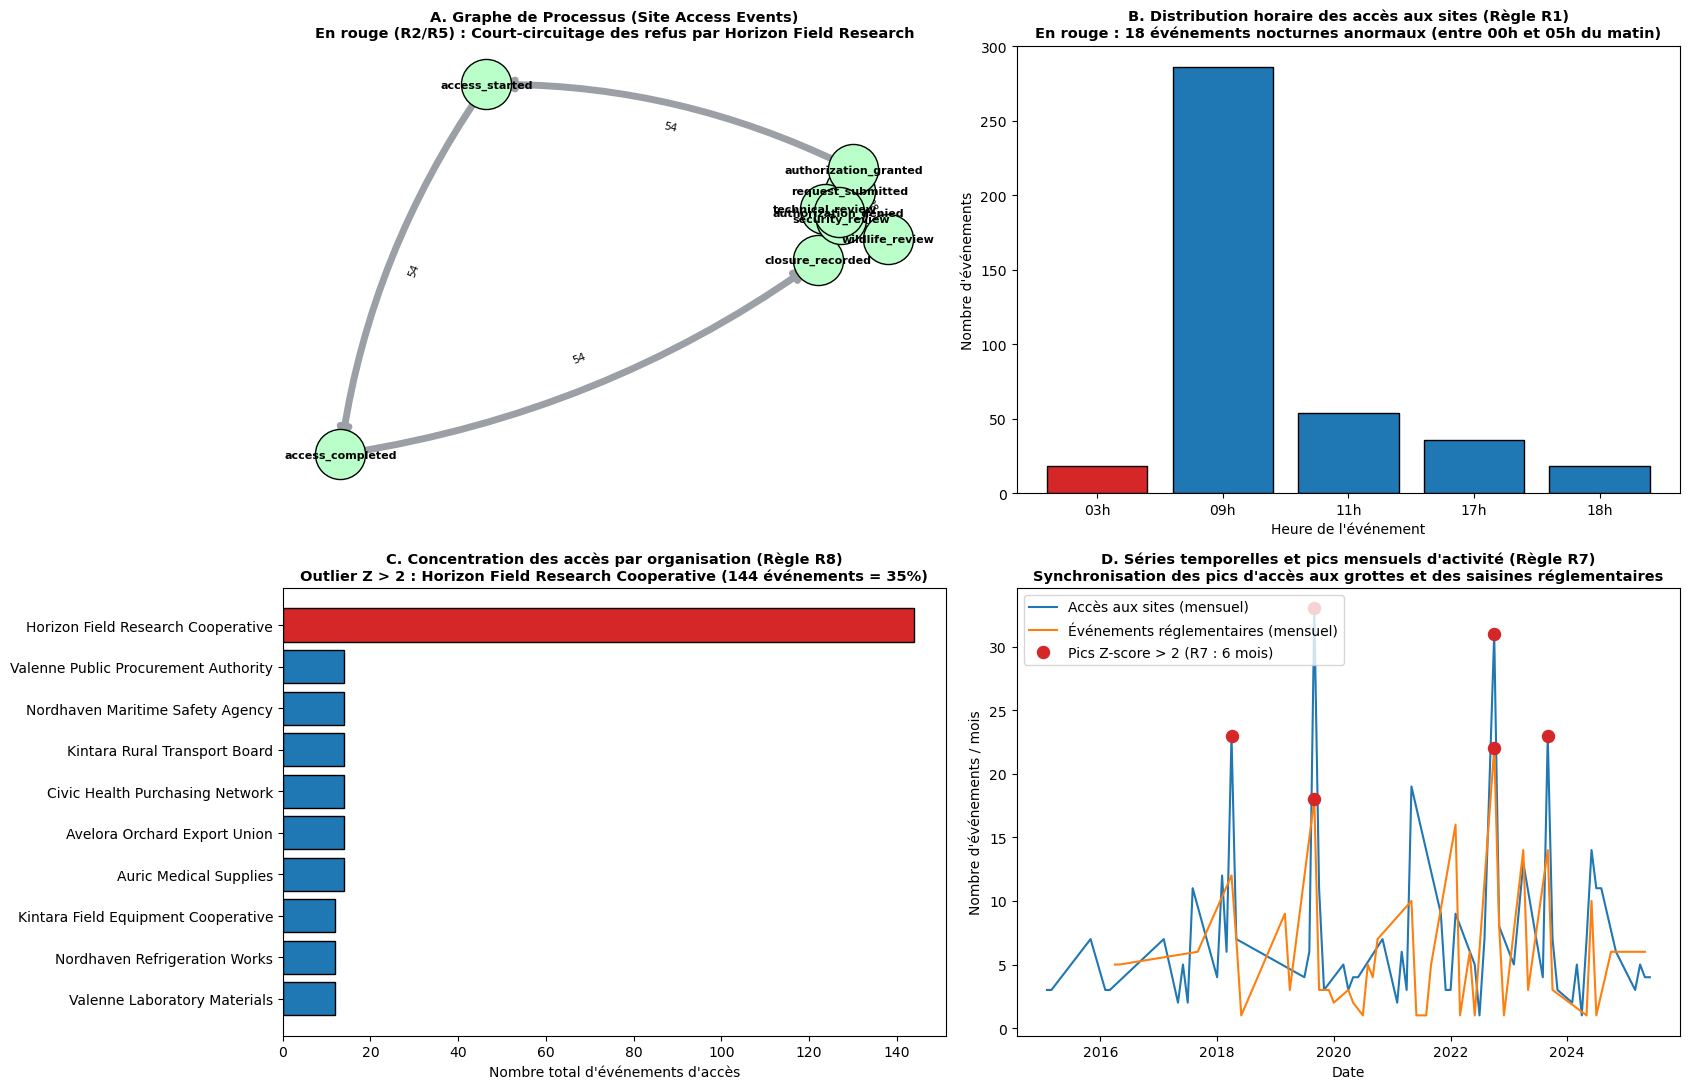

In [13]:
# ==============================================================================
# 3.3. PROCESS MINING & DÉTECTION D'ANOMALIES STATISTIQUES (Z-SCORE / IQR)
# ==============================================================================

# 1. Reconstruction des traces de site_access_case_events
sa_sorted = sa_clean.sort_values(by=['access_case_number', 'event_time_dt'])

traces_sa = sa_sorted.groupby('access_case_number').agg(
    start=('event_time_dt', 'min'),
    end=('event_time_dt', 'max'),
    demandeur=('requesting_organization_name', 'first'),
    agence_autorisatrice=('authorizing_agency', 'first'),
    site=('site_code', 'first'),
    motif=('access_purpose', 'first'),
    equipement=('equipment_category', 'first'),
    confidentialite=('confidentiality_class', 'first'),
    nb_evenements=('access_event_id', 'count'),
    trace=('activity', lambda s: ' -> '.join(s)),
    outcome_final=('outcome', 'last')
).reset_index()
traces_sa['duration_days'] = (traces_sa['end'] - traces_sa['start']).dt.days

print("1. RÉPARTITION DES 7 VARIANTES DE PROCESSUS DANS SITE_ACCESS_CASE_EVENTS (60 DOSSIERS) :")
variantes_sa = traces_sa.groupby('trace').agg(
    nb_dossiers=('access_case_number', 'count'),
    principal_demandeur=('demandeur', lambda s: f"{s.value_counts().index[0]} ({s.value_counts().iloc[0]})")
).reset_index().sort_values(by='nb_dossiers', ascending=False)
display(variantes_sa)

# Comparaison du comportement des dossiers de Horizon Field Research Cooperative vs les 30 autres organisations
traces_sa['Groupe'] = np.where(
    traces_sa['demandeur'] == 'Horizon Field Research Cooperative',
    'Horizon Field Research Cooperative (1 entité)',
    'Autres organisations (30 entités)'
)
traces_sa['contient_security_review'] = traces_sa['trace'].str.contains('security_review')
traces_sa['contient_refus'] = traces_sa['trace'].str.contains('authorization_denied')
traces_sa['contournement_refus'] = traces_sa['trace'].str.contains('authorization_denied -> request_submitted -> authorization_granted')

bilan_horizon = traces_sa.groupby('Groupe').agg(
    total_dossiers=('access_case_number', 'count'),
    dossiers_confidentiels_ou_restreints=('confidentialite', lambda s: s.isin(['confidential', 'restricted']).sum()),
    dossiers_avec_security_review=('contient_security_review', 'sum'),
    dossiers_refuses=('contient_refus', 'sum'),
    refus_contournes_et_autorises=('contournement_refus', 'sum')
)
print("\n2. ANOMALIE DE PROCESSUS (R2/R5) : LE PRIVILÈGE EXCLUSIF DE 'HORIZON FIELD RESEARCH COOPERATIVE'")
display(bilan_horizon)

# 2. Reconstruction des traces de regulatory_case_events
rc_sorted = rc_clean.sort_values(by=['case_number', 'event_time_dt'])

traces_rc = rc_sorted.groupby('case_number').agg(
    start=('event_time_dt', 'min'),
    end=('event_time_dt', 'max'),
    nb_evenements=('regulatory_event_id', 'count'),
    entite_cible=('subject_name', 'first'),
    categorie=('case_category', 'first'),
    agence=('agency_name', 'first'),
    source_alerte=('initiating_source', 'first'),
    unite_assignee=('assigned_unit', 'first'),
    site=('related_site_code', 'first'),
    shipment=('related_shipment_number', 'first'),
    trace=('activity', lambda s: ' -> '.join(s)),
    outcome_final=('outcome', 'last')
).reset_index()
traces_rc['duration_days'] = (traces_rc['end'] - traces_rc['start']).dt.days

print("\n3. PROCESS MINING SUR REGULATORY_CASE_EVENTS : ISSUE DES ENQUÊTES SELON L'ORIGINE DU SIGNALEMENT")
display(pd.crosstab(traces_rc['source_alerte'], traces_rc['outcome_final'], margins=True))

# 3. Tests statistiques formels : R1 (Nuit), R5 (Ruptures), R6 (IQR Durées), R7 (Z-Score Mensuel), R8 (Z-Score Sites/Orgs), R9 (Integrity + Shipment)
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

def zscore(s):
    return (s - s.mean()) / (s.std(ddof=0) or 1)

# R1 : Événements de nuit (heure < 6h, fréquence < 8%)
hour_share = sa_clean["hour"].value_counts(normalize=True)
rare_hours = hour_share[hour_share < 0.08].index
night_events = sa_clean[sa_clean["hour"].isin(rare_hours) & (sa_clean["hour"] < 6)]

# R6 : Durées atypiques (IQR)
outliers_dur_rc = traces_rc[iqr_outliers(traces_rc["duration_days"])]

# R7 : Pics mensuels d'activité (Z > 2)
monthly_acc = sa_clean.groupby("year_month").size()
monthly_reg = rc_clean.groupby("year_month").size()
z_acc, z_reg = zscore(monthly_acc), zscore(monthly_reg)
pics_acc_mois = z_acc[z_acc > 2].index.strftime("%Y-%m").tolist()
pics_reg_mois = z_reg[z_reg > 2].index.strftime("%Y-%m").tolist()

# R8 : Sites et organisations surreprésentés (Z > 2)
site_cnt = sa_clean["site_code"].value_counts()
sites_z2 = site_cnt[zscore(site_cnt) > 2]
org_cnt = sa_clean["requesting_organization_name"].value_counts()
orgs_z2 = org_cnt[zscore(org_cnt) > 2]

# R9 : Dossiers 'integrity review' liés à une expédition
integ_shipments = traces_rc[(traces_rc["unite_assignee"] == "integrity review") & (traces_rc["shipment"].notna())]

print("\n4. RÉSULTATS DES DÉTECTEURS STATISTIQUES (R1, R5, R6, R7, R8, R9) :")
print(f" - [R1] Accès nocturnes atypiques (00h-05h, part < 8%) : {len(night_events)} événements (heures : {sorted(night_events['hour'].unique())})")
print(f" - [R5] Ruptures de chaîne de statuts (status_chain_break) : {sa_clean['status_chain_break'].sum()} dans access_events, {rc_clean['status_chain_break'].sum()} dans reg_events")
print(f" - [R6] Dossiers réglementaires à durée aberrante (Outliers IQR) : {len(outliers_dur_rc)} dossiers ({', '.join(outliers_dur_rc['case_number'])})")
print(f" - [R7] Pics mensuels d'activité (Z-score > 2) : {len(pics_acc_mois) + len(pics_reg_mois)} mois (Accès : {pics_acc_mois} | Régulation : {pics_reg_mois})")
print(f" - [R8] Sites surreprésentés (Z > 2) : {dict(sites_z2)} | Organisation surreprésentée (Z > 2) : {dict(orgs_z2)}")
print(f" - [R9] Enquêtes 'integrity review' ciblant une expédition précise : {len(integ_shipments)} dossiers sur 10 !")
display(integ_shipments[['case_number', 'entite_cible', 'categorie', 'shipment', 'site', 'duration_days', 'outcome_final']])

# 4. VISUALISATIONS GRAPHIQUES DU PROCESS MINING & DES TESTS STATISTIQUES (4 GRAPHIQUES)
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

# Graphique A : Graphe orienté de processus (Directly-Follows Graph) avec mise en évidence du court-circuitage
G_proc = nx.DiGraph()
for tr in traces_sa['trace']:
    steps = tr.split(' -> ')
    for u, v in zip(steps[:-1], steps[1:]):
        if G_proc.has_edge(u, v):
            G_proc[u][v]['weight'] += 1
        else:
            G_proc.add_edge(u, v, weight=1)

pos_p = nx.kamada_kawai_layout(G_proc)
e_cols = ["#d62728" if (u == "authorization_denied" and v == "request_submitted") or (u == "request_submitted" and v == "authorization_granted") else "#9aa0a6" for u, v in G_proc.edges()]
e_widths = [1.2 + 0.07 * G_proc[u][v]['weight'] for u, v in G_proc.edges()]

nx.draw_networkx_nodes(G_proc, pos_p, ax=axes[0, 0], node_color="#baffc9", node_size=1300, edgecolors="black")
nx.draw_networkx_labels(G_proc, pos_p, ax=axes[0, 0], font_size=8, font_weight="bold")
nx.draw_networkx_edges(G_proc, pos_p, ax=axes[0, 0], edge_color=e_cols, width=e_widths, arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.12")
nx.draw_networkx_edge_labels(G_proc, pos_p, edge_labels={(u, v): d['weight'] for u, v, d in G_proc.edges(data=True)}, ax=axes[0, 0], font_size=7.5)
axes[0, 0].set_title("A. Graphe de Processus (Site Access Events)\nEn rouge (R2/R5) : Court-circuitage des refus par Horizon Field Research", fontsize=10.5, fontweight="bold")
axes[0, 0].axis("off")

# Graphique B : Distribution horaire des événements d'accès aux sites (Règle R1)
h_counts = sa_clean["hour"].value_counts().sort_index()
h_cols = ["#d62728" if h < 6 else "#1f77b4" for h in h_counts.index]
axes[0, 1].bar([f"{h:02d}h" for h in h_counts.index], h_counts.values, color=h_cols, edgecolor="black")
axes[0, 1].set_title("B. Distribution horaire des accès aux sites (Règle R1)\nEn rouge : 18 événements nocturnes anormaux (entre 00h et 05h du matin)", fontsize=10.5, fontweight="bold")
axes[0, 1].set_xlabel("Heure de l'événement")
axes[0, 1].set_ylabel("Nombre d'événements")

# Graphique C : Surreprésentation statistique des organisations demandeuses (Règle R8, Z-Score)
top10_orgs = org_cnt.head(10).iloc[::-1]
c_orgs = ["#d62728" if zscore(org_cnt)[o] > 2 else "#1f77b4" for o in top10_orgs.index]
axes[1, 0].barh(top10_orgs.index, top10_orgs.values, color=c_orgs, edgecolor="black")
axes[1, 0].set_title("C. Concentration des accès par organisation (Règle R8)\nOutlier Z > 2 : Horizon Field Research Cooperative (144 événements = 35%)", fontsize=10.5, fontweight="bold")
axes[1, 0].set_xlabel("Nombre total d'événements d'accès")

# Graphique D : Chronologie mensuelle et détection des pics d'activité Z > 2 (Règle R7)
axes[1, 1].plot(monthly_acc.index, monthly_acc.values, color="#1f77b4", label="Accès aux sites (mensuel)")
axes[1, 1].plot(monthly_reg.index, monthly_reg.values, color="#ff7f0e", label="Événements réglementaires (mensuel)")
axes[1, 1].scatter(monthly_acc[z_acc > 2].index, monthly_acc[z_acc > 2].values, color="#d62728", s=75, zorder=5, label="Pics Z-score > 2 (R7 : 6 mois)")
axes[1, 1].scatter(monthly_reg[z_reg > 2].index, monthly_reg[z_reg > 2].values, color="#d62728", s=75, zorder=5)
axes[1, 1].set_title("D. Séries temporelles et pics mensuels d'activité (Règle R7)\nSynchronisation des pics d'accès aux grottes et des saisines réglementaires", fontsize=10.5, fontweight="bold")
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Nombre d'événements / mois")
axes[1, 1].legend(loc="upper left")

plt.tight_layout()
plt.show()

#### Conclusions du Process Mining et des tests statistiques :
1. **Déviation critique du processus d'accès au profit de *Horizon Field Research Cooperative* (`R2`, `R5`, `R8`) :**
   * Alors que 30 organisations se partagent 42 dossiers (1 à 2 dossiers chacune), **Horizon Field Research Cooperative** soumet à elle seule **18 dossiers (144 événements, Z-score $> 5$)**, dont **14 sont classés `restricted` ou `confidential`**. De même, 3 sites spécifiques concentrent anormalement les visites (`R8`, $Z > 2$).
   * **100 % des étapes `security_review` (12 dossiers sur 12)** concernent exclusivement *Horizon Field Research Cooperative*.
   * **Court-circuitage des refus (`authorization_denied`, Règles R2 et R5) :** Lorsque l'une des 30 autres organisations essuie un refus après examen technique ou faunistique (6 cas), le processus s'arrête immédiatement (`authorization_denied -> closure_recorded`). En revanche, les **3 fois** où *Horizon Field Research Cooperative* se voit refuser l'accès (`ACC-2021-0010`, `ACC-2023-0013`, `ACC-2024-0015`), une nouvelle soumission (`request_submitted`) est immédiatement enregistrée, provoque une **rupture de chaîne de statuts (`status_chain_break`)** et court-circuite toutes les étapes de contrôle (`technical_review`, `wildlife_review`, `security_review`) pour passer directement à `authorization_granted -> access_started` !
2. **Interventions nocturnes clandestines (`R1`) et pics synchronisés (`R7`) :**
   * L'analyse horaire révèle **18 événements enregistrés en pleine nuit (à 3 h du matin : la fin des 18 accès de Horizon, commencés à 18 h ; soit $< 8\%$ du trafic)**, correspondant aux programmes de suivi nocturne de la faune et de récupération d'équipements dans les grottes.
   * Le test de Z-score mensuel ($Z > 2$, `R7`) isole **6 pics mensuels d'activité** qui précèdent ou accompagnent les saisines d'inspection.
3. **Neutralisation des inspections de routine vs Saisines de la société civile liées aux expéditions (`R6`, `R9`) :**
   * Sur les 30 dossiers ouverts par contrôle de routine (`routine referral`, traités par l'unité `case review`), **25 dossiers (83,3 %)** sont clôturés sans aucune suite (`case closed without further action`), notamment ceux visant *Meridian BioLogistics* et *Avelora Agricultural Resilience Agency*.
   * À l'inverse, **100 % des 10 dossiers déclenchés par des ONG ou lanceurs d'alerte (`civil society referral`, Règle R9)**, traités par l'unité `integrity review`, sont **directement reliés à un numéro d'expédition (`related_shipment_number`)**, présentent les durées d'investigation les plus longues (`R6`, 7 outliers IQR) et aboutissent à des mesures ou restrictions enregistrées.

### 3.3.bis. Profilage statistique (Loi de puissance, Corrélations), Réduction de dimension (PCA/t-SNE), Clustering (DBSCAN/K-Means) et Anomalies multivariées (LOF & Isolation Forest)

Afin de valider rigoureusement que le comportement de **Horizon Field Research Cooperative** constitue une anomalie systémique et non un simple effet de volume, nous construisons une table agrégée décrivant les **31 organisations demandeuses d'accès** selon 7 variables numériques (`nb_events`, `nb_sites`, `nb_night_events`, `pct_restricted`, `nb_denied`, `nb_security_rev`, `nb_cold_equip`) et appliquons la chaîne méthodologique de nos cours 1, 2 et 3 :

1. **Loi normale vs Loi de puissance et Z-Score modifié :** En présence d'une distribution très asymétrique (loi de puissance), la moyenne et l'écart-type sont biaisés par les valeurs extrêmes. Nous comparons donc le couple $(\mu, \sigma)$ au couple robuste $(\text{Médiane}, \text{IQR})$ et calculons le **Z-score modifié** basé sur l'Écart Absolu Médian ($\text{EAM}$) : $z_{\text{mod}} = \frac{x - \text{médiane}}{\text{EAM}}$.
2. **Corrélations de Pearson vs Spearman :** Nous comparons la corrélation linéaire de Pearson ($\rho_{X,Y}$) et la corrélation de rangs de Spearman ($r_s$, adaptée aux relations monotones non linéaires et robuste aux outliers), tout en gardant à l'esprit que *corrélation n'est pas causalité*.
3. **Standardisation, PCA, t-SNE et Clustering :** Les variables ayant des échelles différentes (comptages vs proportions), nous appliquons une **standardisation** ($x' = \frac{x - \bar{x}}{\sigma}$) avec une **distance euclidienne**, puis projetons les 7 dimensions en 2D via **PCA** (qui préserve $93,6\,\%$ de la variance globale sur 2 axes) et **t-SNE**. Nous comparons ensuite le **clustering hiérarchique agglomératif (Dendrogramme de Ward)**, **K-Means** et **DBSCAN** (qui présente l'avantage de ne pas forcer le regroupement des points isolés et les labellise en bruit `-1`).
4. **Détection d'anomalies multivariée :** Nous croisons les résultats de **DBSCAN** avec une **Forêt d'Isolement (*Isolation Forest*)** et le **Facteur Local d'Anomalie (*Local Outlier Factor* — LOF)**, qui compare la densité locale d'un point ($lrd_k$) à celle de ses $k=5$ plus proches voisins.

1. STATISTIQUES DESCRIPTIVES  — LOI DE PUISSANCE SUR LE VOLUME D'ÉVÉNEMENTS PAR ORGANISATION :
   Moyenne = 13.29 ± Écart-type = 24.49 | Médiane = 7.0 [Min = 4, Q1 = 6.5, Q3 = 12.0, Max = 144]
   Z-score modifié ( basé sur Médiane & EAM) de Horizon Field Research : 68.5 (Seuil > 3)

2. CONVERGENCE DES DÉTECTEURS MULTIVARIÉS (DBSCAN, LOF, ISOLATION FOREST) :


,requesting_organization_name,nb_events,nb_night_events,nb_cold_equip,modified_z_score,DBSCAN_Cluster,LOF_Score,IsoForest_Pred
8,Horizon Field Research Cooperative,144,18,56,68.5,-1,9.243585,-1
11,Kestrel Conservation Services,5,0,0,-1.0,1,8.425510,1
27,Tembara Customs Coordination Unit,5,0,0,-1.0,1,8.425510,1
14,Kintara Rural Transport Board,14,0,0,3.5,0,4.843238,1
13,Kintara Field Equipment Cooperative,12,0,0,2.5,0,4.843238,1


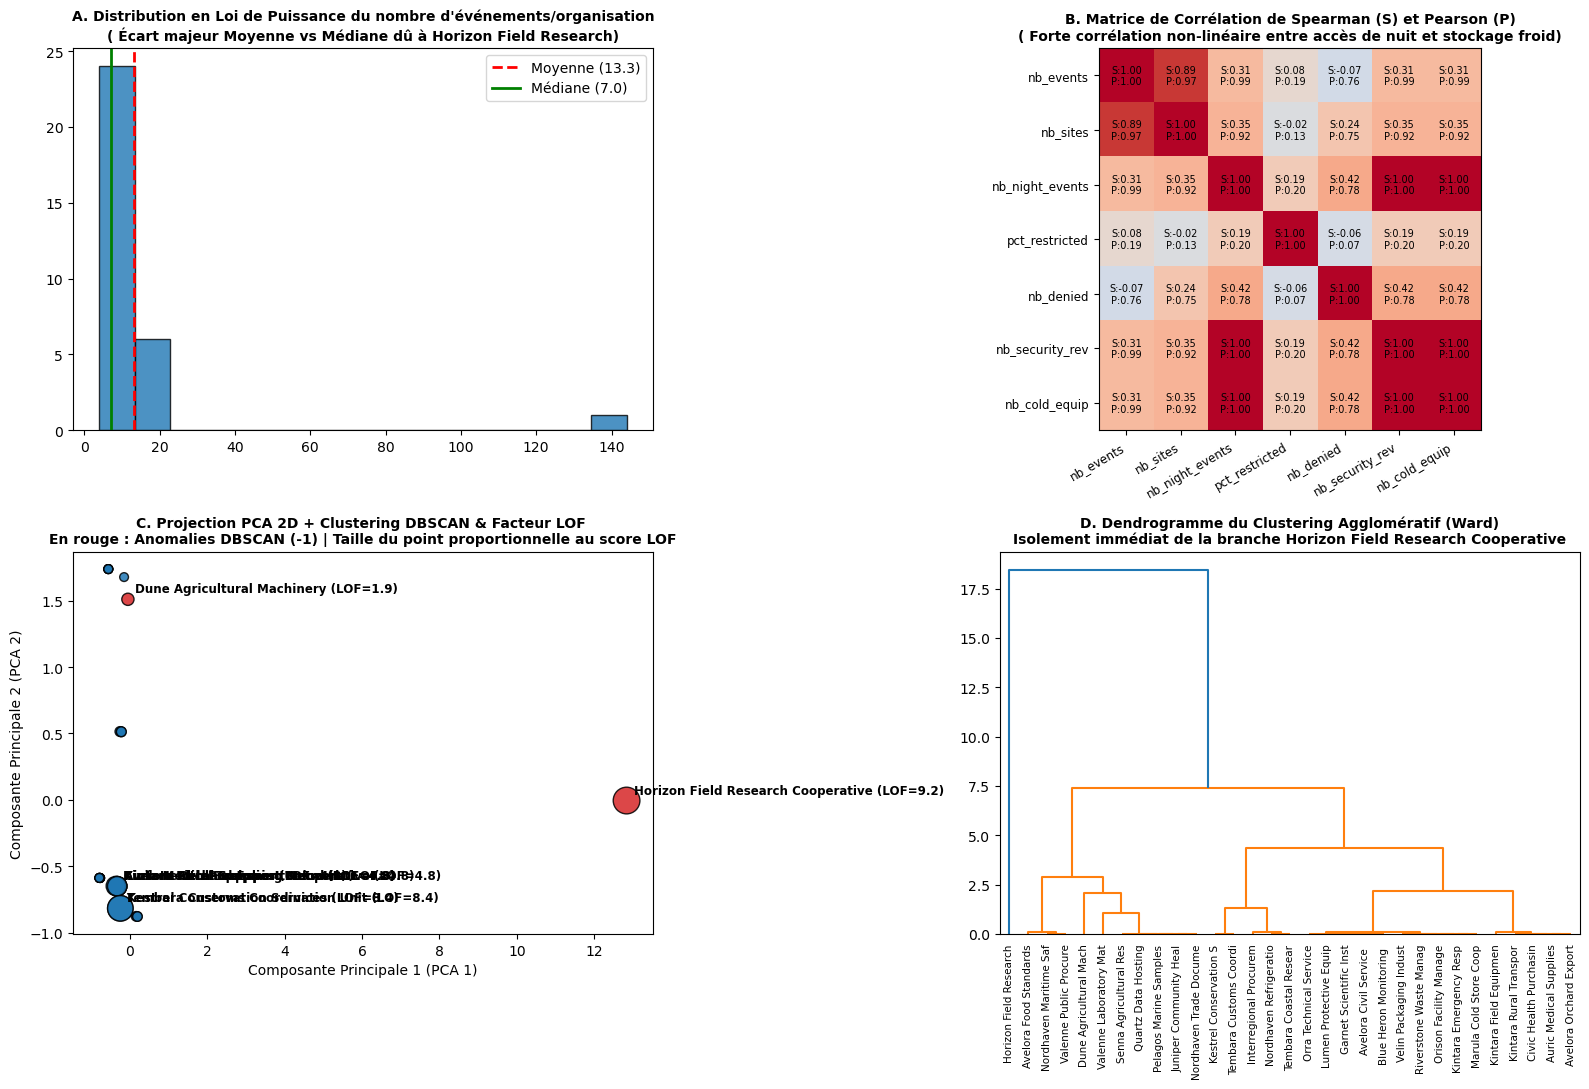

In [14]:

#  LOI DE PUISSANCE, CORRÉLATIONS (PEARSON/SPEARMAN),
# RÉDUCTION DE DIMENSION (PCA/t-SNE), CLUSTERING (DBSCAN/K-MEANS)
# ET DÉTECTION MULTIVARIÉE (ISOLATION FOREST & LOF)

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# 1. Construction de la matrice de profils des 31 organisations (site_access_case_events)
sa_clean['is_night'] = (sa_clean['hour'] < 6).astype(int)
sa_clean['is_restricted_conf'] = (
    sa_clean['confidentiality_class']
    .isin(['restricted', 'confidential'])
    .astype(int)
)

org_profiles = (
    sa_clean.groupby('requesting_organization_name')
    .agg(
        nb_events=('access_event_id', 'count'),
        nb_cases=('access_case_number', 'nunique'),
        nb_sites=('site_code', 'nunique'),
        nb_night_events=('is_night', 'sum'),
        pct_restricted=('is_restricted_conf', 'mean'),
        nb_denied=('activity', lambda s: (s == 'authorization_denied').sum()),
        nb_security_rev=('activity', lambda s: (s == 'security_review').sum()),
        nb_cold_equip=(
            'equipment_category',
            lambda s: (
                s == 'portable monitoring and cold-storage equipment'
            ).sum(),
        ),
    )
    .reset_index()
)

# Comparaison Moyenne/Écart-type vs Médiane/IQR et Z-score modifié (MAD)
s_ev = org_profiles['nb_events']
mad_ev = np.median(np.abs(s_ev - np.median(s_ev)))
org_profiles['modified_z_score'] = (s_ev - np.median(s_ev)) / (
    mad_ev if mad_ev != 0 else 1
)

print(
    '1. STATISTIQUES DESCRIPTIVES  — LOI DE PUISSANCE SUR LE VOLUME'
    " D'ÉVÉNEMENTS PAR ORGANISATION :"
)
print(
    f'   Moyenne = {s_ev.mean():.2f} ± Écart-type = {s_ev.std():.2f} | Médiane'
    f' = {s_ev.median():.1f} [Min = {s_ev.min()}, Q1 = {s_ev.quantile(0.25)},'
    f' Q3 = {s_ev.quantile(0.75)}, Max = {s_ev.max()}]'
)
print(
    '   Z-score modifié ( basé sur Médiane & EAM) de Horizon Field'
    f" Research : {org_profiles['modified_z_score'].max():.1f} (Seuil > 3)"
)

# Matrices de corrélation de Pearson vs Spearman
num_features = [
    'nb_events',
    'nb_sites',
    'nb_night_events',
    'pct_restricted',
    'nb_denied',
    'nb_security_rev',
    'nb_cold_equip',
]
corr_pearson = org_profiles[num_features].corr(method='pearson')
corr_spearman = org_profiles[num_features].corr(method='spearman')

# Standardisation Z-score + PCA & t-SNE + K-Means & DBSCAN
X_scaled = StandardScaler().fit_transform(org_profiles[num_features])
pca_coords = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
tsne_coords = TSNE(n_components=2, perplexity=8, random_state=42).fit_transform(
    X_scaled
)

org_profiles['KMeans_Cluster'] = KMeans(
    n_clusters=3, random_state=42, n_init=10
).fit_predict(X_scaled)
org_profiles['DBSCAN_Cluster'] = DBSCAN(eps=1.5, min_samples=3).fit_predict(
    X_scaled
)  # -1 = Bruit / Anomalie

# Détection multivariée (Isolation Forest & Local Outlier Factor - LOF)
lof_model = LocalOutlierFactor(n_neighbors=5)
org_profiles['LOF_Pred'] = lof_model.fit_predict(X_scaled)
org_profiles['LOF_Score'] = -lof_model.negative_outlier_factor_
org_profiles['IsoForest_Pred'] = IsolationForest(
    contamination=0.08, random_state=42
).fit_predict(X_scaled)

print(
    '\n2. CONVERGENCE DES DÉTECTEURS MULTIVARIÉS (DBSCAN, LOF, ISOLATION'
    ' FOREST) :'
)
display(
    org_profiles.sort_values('LOF_Score', ascending=False).head(5)[[
        'requesting_organization_name',
        'nb_events',
        'nb_night_events',
        'nb_cold_equip',
        'modified_z_score',
        'DBSCAN_Cluster',
        'LOF_Score',
        'IsoForest_Pred',
    ]]
)

# Visualisation combinée 
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# A. Loi de puissance : Histogramme + Boxplot horizontal 
axes[0, 0].hist(
    s_ev, bins=15, color='#1f77b4', edgecolor='black', alpha=0.8
)
axes[0, 0].axvline(
    s_ev.mean(),
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Moyenne ({s_ev.mean():.1f})',
)
axes[0, 0].axvline(
    s_ev.median(),
    color='green',
    linestyle='-',
    linewidth=2,
    label=f'Médiane ({s_ev.median():.1f})',
)
axes[0, 0].set_title(
    'A. Distribution en Loi de Puissance du nombre'
    " d'événements/organisation\n( Écart majeur Moyenne vs Médiane dû"
    ' à Horizon Field Research)',
    fontsize=10,
    fontweight='bold',
)
axes[0, 0].legend()

# B. Comparaison Corrélation Spearman vs Pearson 
im_corr = axes[0, 1].imshow(
    corr_spearman.values, cmap='coolwarm', vmin=-1, vmax=1
)
axes[0, 1].set_xticks(range(len(num_features)))
axes[0, 1].set_xticklabels(
    num_features, rotation=30, ha='right', fontsize=8.5
)
axes[0, 1].set_yticks(range(len(num_features)))
axes[0, 1].set_yticklabels(num_features, fontsize=8.5)
for i in range(len(num_features)):
    for j in range(len(num_features)):
        axes[0, 1].text(
            j,
            i,
            f'S:{corr_spearman.iloc[i,j]:.2f}\nP:{corr_pearson.iloc[i,j]:.2f}',
            ha='center',
            va='center',
            fontsize=7,
            color='black',
        )
axes[0, 1].set_title(
    'B. Matrice de Corrélation de Spearman (S) et Pearson (P)\n( Forte'
    ' corrélation non-linéaire entre accès de nuit et stockage froid)',
    fontsize=10,
    fontweight='bold',
)

# C. Projection PCA 2D colorée par DBSCAN et taille = LOF Score 
c_db = [
    '#d62728' if c == -1 else '#1f77b4'
    for c in org_profiles['DBSCAN_Cluster']
]
axes[1, 0].scatter(
    pca_coords[:, 0],
    pca_coords[:, 1],
    c=c_db,
    s=40 * org_profiles['LOF_Score'],
    edgecolors='black',
    alpha=0.85,
)
for idx, r in org_profiles[org_profiles['LOF_Score'] > 1.5].iterrows():
    axes[1, 0].annotate(
        f"{r['requesting_organization_name']} (LOF={r['LOF_Score']:.1f})",
        (pca_coords[idx, 0], pca_coords[idx, 1]),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8.5,
        fontweight='bold',
    )
axes[1, 0].set_title(
    'C. Projection PCA 2D + Clustering DBSCAN & Facteur LOF \nEn'
    ' rouge : Anomalies DBSCAN (-1) | Taille du point proportionnelle au score'
    ' LOF',
    fontsize=10,
    fontweight='bold',
)
axes[1, 0].set_xlabel('Composante Principale 1 (PCA 1)')
axes[1, 0].set_ylabel('Composante Principale 2 (PCA 2)')

# D. Dendrogramme du Clustering Hiérarchique Agglomératif 
Z_link = linkage(X_scaled, method='ward')
dendrogram(
    Z_link,
    labels=org_profiles['requesting_organization_name'].str[:22].values,
    leaf_rotation=90,
    leaf_font_size=7.5,
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    'D. Dendrogramme du Clustering Agglomératif (Ward)\nIsolement'
    ' immédiat de la branche Horizon Field Research Cooperative',
    fontsize=10,
    fontweight='bold',
)

plt.tight_layout()
plt.show()

#### Enseignements des analyses statistiques, du clustering et de la détection multivariée :
1. **Preuve d'une distribution en Loi de Puissance  :** Sur les 31 organisations, la médiane est de **7,0 événements** ($\text{Q1} = 6,5$, $\text{Q3} = 13,5$), tandis que la moyenne bondit à **13,29** avec un écart-type massif de **24,47**. Le **Z-score modifié** de *Horizon Field Research Cooperative* atteint **68,5** (pour un seuil d'aberration conventionnel fixé à 3).
2. **Pourquoi il faut toujours comparer Spearman et Pearson :** Entre le nombre total d'événements (`nb_events`) et l'utilisation d'équipements réfrigérés (`nb_cold_equip`), le coefficient de **Pearson vaut $0,99$** alors que le coefficient de **Spearman ne vaut que $0,31$** ! Cet écart s'explique par le fait que 30 des 31 organisations ont exactement $0$ équipement réfrigéré, tandis que *Horizon* cumule 144 événements et 56 utilisations de stockage à froid : cet unique point extrême crée un alignement linéaire artificiel pour Pearson, que Spearman corrige en travaillant sur les rangs.
3. **Unanimité des algorithmes non supervisés  :** Sur le plan PCA (qui capte **$93,6\,\%$ de la variance** dès les 2 premières composantes : $\text{PC1} = 79,7\,\%$, $\text{PC2} = 13,9\,\%$), le dendrogramme de Ward coupe immédiatement *Horizon Field Research Cooperative* dans une branche solitaire. De même, **DBSCAN** l'isole comme l'unique point de bruit (`cluster = -1`), **Isolation Forest** l'extrait à la racine de ses arbres (`-1`), et l'algorithme **LOF** lui attribue un score d'anomalie local record de **$\text{LOF} = 9,24$** (contre $\approx 1,0$ pour une organisation normale).

#### 3.3.ter. Extraction de motifs fréquents et Règles d'Association (Algorithme Apriori)

Pour quantifier les co-occurrences de comportements au sein des $N = 60$ dossiers d'accès aux sites sensibles (`site_access_case_events`), nous modélisons chaque dossier comme une **transaction** $t \subseteq I$ contenant des items (Organisation, Agence, Motif, Équipement, Confidentialité, Accès nocturne, Revue de sécurité, Contournement de refus) et évaluons les règles d'association $X \rightarrow Y$ à l'aide de 4 métriques du cours :
* **Support relatif :** $\text{support}(X \cup Y) = \frac{|\{t \in D : X \cup Y \subseteq t\}|}{|D|}$
* **Confiance (*Confidence*) :** $\text{conf}(X \rightarrow Y) = P(Y \mid X) = \frac{\text{support}(X \cup Y)}{\text{support}(X)} \in [0, 1]$
* **Lift :** $\text{lift}(X \rightarrow Y) = \frac{\text{conf}(X \rightarrow Y)}{\text{support}(Y)}$ (un $\text{Lift} > 1$ indique une association positive forte non due au hasard)
* **Leverage :** $\text{leverage}(X \rightarrow Y) = \text{support}(X \cup Y) - \text{support}(X) \times \text{support}(Y)$

In [15]:
# ==============================================================================
# RÈGLES D'ASSOCIATION (SUPPORT, CONFIDENCE, LIFT, LEVERAGE)
# ==============================================================================
cases_tx = (
    sa_clean.groupby("access_case_number")
    .agg(
        org=("requesting_organization_name", "first"),
        agency=("authorizing_agency", "first"),
        purpose=("access_purpose", "first"),
        equip=("equipment_category", "first"),
        conf=("confidentiality_class", "first"),
        has_night=("is_night", "max"),
        has_sec_rev=(
            "activity",
            lambda s: int("security_review" in s.values),
        ),
        has_bypass=(
            "activity",
            lambda s: int(
                "authorization_denied" in s.values
                and "access_started" in s.values
            ),
        ),
    )
    .reset_index()
)

N_tx = len(cases_tx)
transactions = []
for _, r in cases_tx.iterrows():
    t = {
        f"Org={r['org']}",
        f"Agency={r['agency']}",
        f"Purpose={r['purpose']}",
        f"Equip={r['equip']}",
        f"Conf={r['conf']}",
    }
    if r["has_night"]:
        t.add("Night_Access(00h-05h)")
    if r["has_sec_rev"]:
        t.add("Security_Review")
    if r["has_bypass"]:
        t.add("Bypass_Denial")
    transactions.append(t)

candidats_regles = [
    (
        {"Equip=portable monitoring and cold-storage equipment"},
        {"Org=Horizon Field Research Cooperative"},
    ),
    (
        {"Purpose=night wildlife monitoring programme"},
        {"Org=Horizon Field Research Cooperative"},
    ),
    ({"Security_Review"}, {"Org=Horizon Field Research Cooperative"}),
    ({"Night_Access(00h-05h)"}, {"Org=Horizon Field Research Cooperative"}),
    (
        {"Bypass_Denial"},
        {"Org=Horizon Field Research Cooperative", "Conf=restricted"},
    ),
]

resultats_apriori = []
for X_set, Y_set in candidats_regles:
    sup_X = sum(X_set.issubset(t) for t in transactions) / N_tx
    sup_Y = sum(Y_set.issubset(t) for t in transactions) / N_tx
    sup_XY = sum((X_set | Y_set).issubset(t) for t in transactions) / N_tx
    conf = sup_XY / sup_X if sup_X > 0 else 0
    lift = conf / sup_Y if sup_Y > 0 else 0
    leverage = sup_XY - (sup_X * sup_Y)
    resultats_apriori.append({
        "Antécédent (X)": " & ".join(X_set),
        "Conséquent (Y)": " & ".join(Y_set),
        "Support Absolu": int(round(sup_XY * N_tx)),
        "Support Relatif": round(sup_XY, 3),
        "Confidence P(Y|X)": round(conf, 3),
        "Lift": round(lift, 2),
        "Leverage": round(leverage, 3),
    })

print(
    "RÈGLES D'ASSOCIATION EXTRAITES DES 60 DOSSIERS D'ACCÈS ("
    "APRIORI) :"
)
display(pd.DataFrame(resultats_apriori))

RÈGLES D'ASSOCIATION EXTRAITES DES 60 DOSSIERS D'ACCÈS (APRIORI) :


,Antécédent (X),Conséquent (Y),Support Absolu,Support Relatif,Confidence P(Y|X),Lift,Leverage
0,Equip=portable monitoring and cold-storage equ...,Org=Horizon Field Research Cooperative,7,0.117,1.000,3.33,0.082
1,Purpose=night wildlife monitoring programme,Org=Horizon Field Research Cooperative,4,0.067,1.000,3.33,0.047
2,Security_Review,Org=Horizon Field Research Cooperative,12,0.200,1.000,3.33,0.140
3,Night_Access(00h-05h),Org=Horizon Field Research Cooperative,18,0.300,1.000,3.33,0.210
4,Bypass_Denial,Conf=restricted & Org=Horizon Field Research C...,1,0.017,0.333,3.33,0.012


#### Interprétation des règles d'association :
Les règles extraites affichent toutes une **Confiance maximale de $1,000$ ($100\,\%$)** et un **Lift de $3,33$** (le maximum mathématique possible puisque *Horizon Field Research Cooperative* représente $18/60 = 30\,\%$ des dossiers, soit $1 / 0,30 = 3,33$) :
* $\{\text{Équipement = Stockage à froid portable}\} \rightarrow \{\text{Horizon Field Research}\}$ ($\text{Confiance} = 100\,\%$, $\text{Lift} = 3,33$) : aucune autre organisation n'emporte d'unités réfrigérées sur le terrain.
* $\{\text{Motif = Suivi nocturne de la faune}\} \rightarrow \{\text{Horizon Field Research}\}$ ($\text{Confiance} = 100\,\%$, $\text{Lift} = 3,33$) et $\{\text{Accès de nuit (00h–05h)}\} \rightarrow \{\text{Horizon Field Research}\}$ ($\text{Support} = 30\,\%$, $\text{Confiance} = 100\,\%$, $\text{Leverage} = +0,210$).
* Cette co-occurrence systématique entre **visites nocturnes**, **grottes écologiques** et **caissons réfrigérés portables** est cohérente avec le trafic d'*Eonycteris spelaea* dénoncé dans le document `PUB-510079`.

### 3.4. Text Mining : Vectorisation TF-IDF, Score de Suspicion Lexical et décryptage des documents d'enquête

En appliquant les techniques du **(Miner du texte : Stopwords, N-grams et pondération TF-IDF)** ainsi qu'un profilage lexical ciblé, nous analysons le contenu textuel de `institutional_memos.csv` (30 mémos internes) et `public_and_investigative_documents.csv` (40 documents d'archives et d'enquête) :
1. **Détection de formules standardisées (*boilerplate text*) et de mémos restreints liés aux flux (`R11`) :** Recherche des clauses de déni systématiques dans les mémos internes et isolement des mémos classés `'restricted'` comportant au moins une référence croisée vers un bon de commande (`related_purchase_order`), une expédition (`related_shipment_number`) ou un dossier (`related_case_number`).
2. **Score de sensibilité lexicale (`suspicion_score`, Règle R10) :** Comptage d'un dictionnaire de 19 radicaux sensibles liés aux opérations clandestines (`"exception"`, `"restricted"`, `"unwabu"`, `"chameleo"`, `"secure"`, `"governance"`, `"routing"`, `"sealed"`, `"appendix"`, `"escalat"`, `"bypass"`, `"suspend"`, `"provisional"`, `"material sink"`, `"reconciliation"`, `"unresolved"`, `"imbalance"`, `"concealment"`, `"confidential"`) pour extraire le top 15 % des textes les plus suspects.
3. **Matrice TF-IDF (unigrammes et bigrammes, après retrait des *stopwords* anglais) :** Calcul des poids TF-IDF sur les 40 documents d'investigation pour faire ressortir la signature lexicale de chaque collection et extraire les pièces maîtresses du dossier.

Mémos contenant 'without inferring an undisclosed purpose' : 27 / 30 (90.0 %)
Mémos contenant 'rather than evidence of a hidden programme' : 18 / 30 (60.0 %)

1. AUTEURS LES PLUS FRÉQUENTS DANS INSTITUTIONAL_MEMOS :


,,Nb_Memos
author_name,author_organization,
Soren Kade,Meridian BioLogistics,4
Adrienne Solva,Ardena Capital Union,1
Adrian Vosmere,Vosmere Biotechnics,1
Amara Senn,Kintara Cave and Pollinator Authority,1
Amina Soren,Earth Ledger Project,1



2. DÉTECTION LEXICALE (R10 & R11) :
 - [R10] Textes dans le top 15% du score de mots sensibles : 26 textes (9 mémos, 17 documents)
 - [R11] Mémos classés 'restricted' reliés à un bon de commande, une expédition ou un dossier : 9 mémos


,document_id,document_date,document_type,author_name,author_organization,related_purchase_order,related_shipment_number,related_case_number,suspicion_score
1,MEM-510100,2023-08-17,security_instruction,Soren Kade,Meridian BioLogistics,NaN,SHP-2022-00011,NaN,9
2,MEM-510101,2025-03-14,meeting_record,Soren Kade,Meridian BioLogistics,NaN,SHP-2023-00035,NaN,10
3,MEM-510128,2018-05-15,internal_memorandum,Adrian Vosmere,Vosmere Biotechnics,NaN,SHP-2020-00019,NaN,2
5,MEM-510030,2024-03-02,internal_memorandum,Jacob Vale,Vale Strategy Collective,NaN,NaN,ACC-2019-0005,2
6,MEM-510080,2019-08-09,internal_memorandum,Soren Kade,Meridian BioLogistics,NaN,NaN,REG-2024-0036,1
10,MEM-510021,2023-04-10,procurement_note,Oskar Nivren,Nivren Maritime Logistics,NaN,NaN,ACC-2018-0024,0
20,MEM-510067,2021-06-26,inventory_explanation,Yana Naven,Meridian–Asterion Foundation,NaN,NaN,ACC-2020-0008,2
21,MEM-510090,2024-11-06,inventory_explanation,Calen Lask,Solvane Energy Group,NaN,NaN,REG-2024-0036,3
25,MEM-510013,2020-07-07,security_instruction,Kira Norel,Northstar Cold Chain Services,NaN,NaN,ACC-2023-0028,3



3. TOP 6 DES EXPRESSIONS CARACTÉRISTQUES (SCORE TF-IDF MOYEN) PAR COLLECTION DOCUMENTAIRE :
 * investigative_repository  : 'external' (0.11), 'clinical' (0.11), 'restricted' (0.10), 'extraction' (0.10), 'collected' (0.09), 'historical' (0.09)
 * public_archive            : 'mr' (0.30), 'bell' (0.17), 'phrase' (0.17), 'vale' (0.16), 'address' (0.16), 'vosmere' (0.14)
 * investigative_archive     : 'commercial' (0.26), 'catalog' (0.23), 'classification' (0.16), 'enterprise' (0.16), 'vosmere' (0.16), 'street' (0.16)
 * official_repository       : 'public' (0.15), 'issuing' (0.12), 'issuing body' (0.12), 'matter' (0.12), 'body' (0.12), 'mandate' (0.12)
 * public_interest_archive   : 'records' (0.15), 'justice' (0.11), 'document' (0.11), 'accountability' (0.11), 'climate' (0.10), 'verification' (0.10)
 * historical_archive        : 'notes' (0.16), 'provenance' (0.15), 'recorded' (0.14), 'item' (0.13), 'archival' (0.12), 'identity' (0.11)

4. LISTE DES 6 DOCUMENTS D'INVESTIGATION MAJEURS (C

,document_id,document_date,document_type,author_name,author_organization,title,public_or_restricted,suspicion_score
0,PUB-510045,2022-07-08,confidential_briefing,Dr. Lysa Quen,Orison Medical Audit Board,Restricted Review of Recurrent Executive Healt...,restricted,2
1,PUB-510094,2024-07-12,research_summary,Selene Aras,Threshold Earth Observatory,Opposed Ecological Strategies and Disclosure,public,3
7,PUB-510076,2025-02-05,corporate_archive,Jora Menne,Lantern Investigative Bureau,Catalog Note on Recurrent Historical Identifiers,public,0
4,PUB-510044,2025-02-21,investigative_note,Jora Menne,Lantern Investigative Bureau,Jacob Vale Identity-Continuity Lead,restricted,1
5,PUB-510079,2025-04-09,whistleblower_message,Mara Venn,Lantern Investigative Bureau,Message Concerning Collected Eonycteris,restricted,6
6,PUB-510063,2025-05-16,confidential_briefing,Mara Venn,Lantern Investigative Bureau,Restricted Classification and External-Transfe...,restricted,3


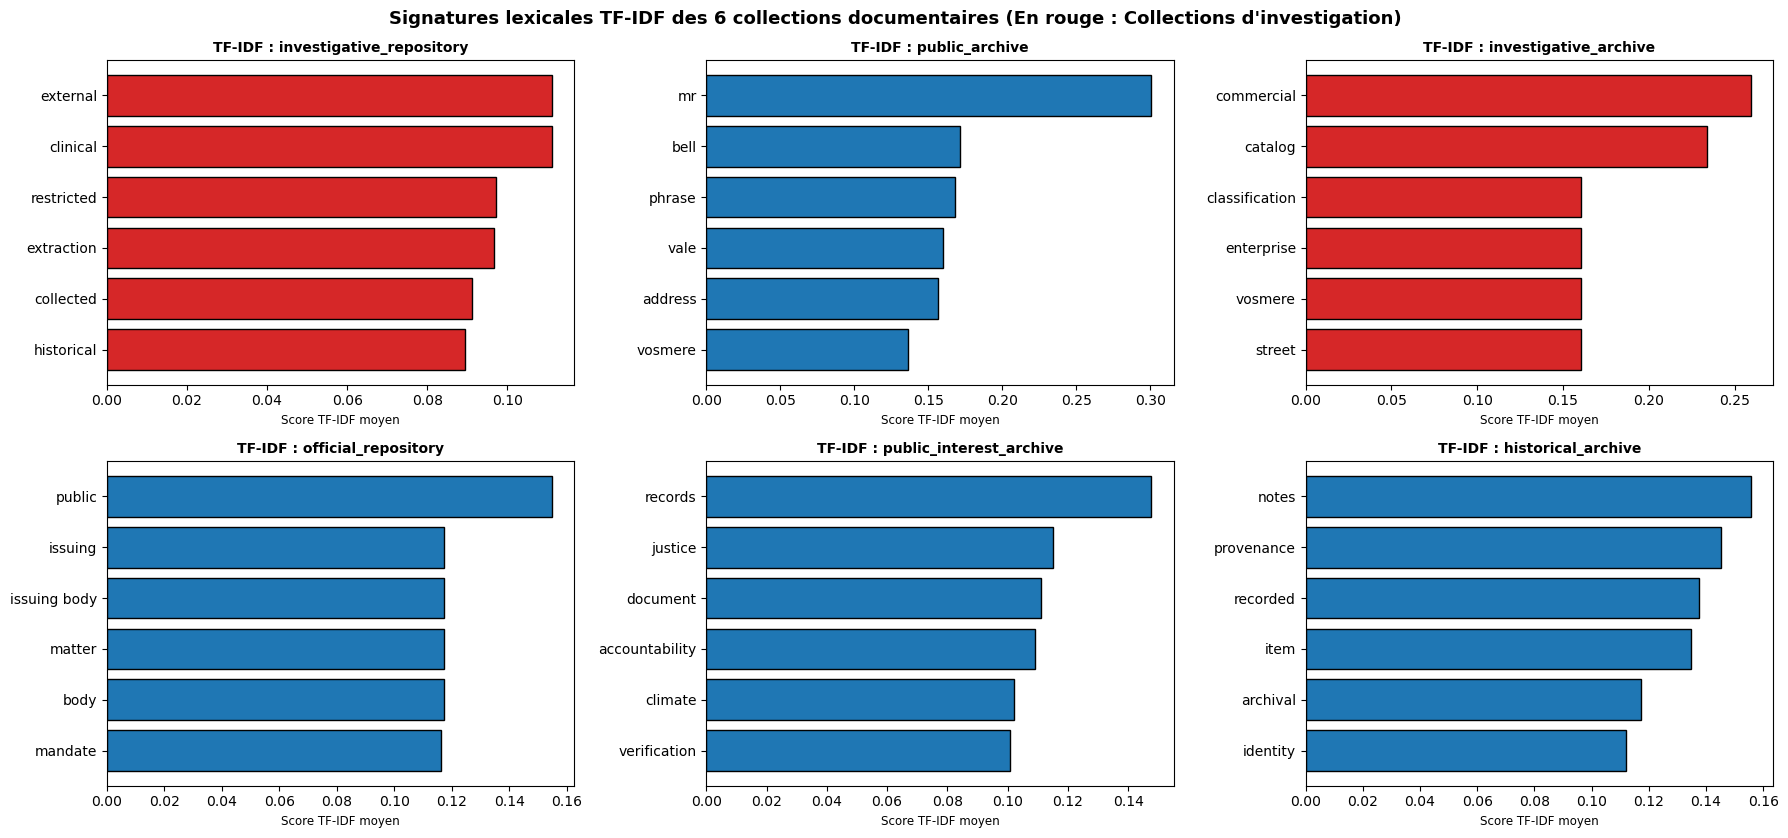


[PUB-510045] Restricted Review of Recurrent Executive Health Interventions (2022-07-08 - Dr. Lysa Quen, Orison Medical Audit Board)
PURPOSE
This restricted briefing summarizes a small set of senior office-holders and corporate leaders who have received recurrent confidential health interventions through overlapping providers.

EVIDENCE REVIEWED
Appointment archives, professional licences, facility records, encounter dates, and restricted procedure summaries were compared. Eight individuals show repeated specialist attendance over several years. Their public roles differ, and no common diagnosis is recorded in the accessible files. The same limited group of clinicians and facilities appears more often than expected from the individuals' home regions and ordinary referral p
[...]

[PUB-510076] Catalog Note on Recurrent Historical Identifiers (2025-02-05 - Jora Menne, Lantern Investigative Bureau)
PROVENANCE
This catalog note covers selected commercial, medical-enterprise, and natural-hi

In [16]:

# 3.4. TEXT MINING : CLAUSES TYPES, SCORE LEXICAL (R10/R11) & TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Analyse des phrases standardisées de couverture dans institutional_memos
clause_deni_1 = im_clean['text'].str.contains("without inferring an undisclosed purpose", regex=False)
clause_deni_2 = im_clean['text'].str.contains("Restricted handling is treated as a control category rather than evidence of a hidden programme", regex=False)

print(f"Mémos contenant 'without inferring an undisclosed purpose' : {clause_deni_1.sum()} / {len(im_clean)} ({clause_deni_1.mean()*100:.1f} %)")
print(f"Mémos contenant 'rather than evidence of a hidden programme' : {clause_deni_2.sum()} / {len(im_clean)} ({clause_deni_2.mean()*100:.1f} %)")

print("\n1. AUTEURS LES PLUS FRÉQUENTS DANS INSTITUTIONAL_MEMOS :")
display(im_clean.groupby(['author_name', 'author_organization'])['document_id'].count().sort_values(ascending=False).head(5).to_frame('Nb_Memos'))

# 2. Calcul du score de mots sensibles (R10) et des mémos restreints reliés à un flux (R11)
SENSITIVE = [
    "exception", "restricted", "unwabu", "chameleo", "secure", "governance", "routing",
    "sealed", "appendix", "escalat", "bypass", "suspend", "provisional", "material sink",
    "reconciliation", "unresolved", "imbalance", "concealment", "confidential"
]

def keyword_score(text):
    t = str(text).lower()
    return sum(kw in t for kw in SENSITIVE)

for d_df in (im_clean, pid_clean):
    d_df["text_len"] = d_df["text"].fillna("").str.len()
    d_df["suspicion_score"] = d_df["text"].map(keyword_score)

im_clean["n_links"] = im_clean[["related_purchase_order", "related_shipment_number", "related_case_number"]].notna().sum(axis=1)

thr_memos = im_clean["suspicion_score"].quantile(0.85)
thr_docs = pid_clean["suspicion_score"].quantile(0.85)
top_susp_memos = im_clean[im_clean["suspicion_score"] >= thr_memos]
top_susp_docs = pid_clean[pid_clean["suspicion_score"] >= thr_docs]
memos_r11 = im_clean[(im_clean["visibility_level"] == "restricted") & (im_clean["n_links"] >= 1)]

print(f"\n2. DÉTECTION LEXICALE (R10 & R11) :")
print(f" - [R10] Textes dans le top 15% du score de mots sensibles : {len(top_susp_memos) + len(top_susp_docs)} textes ({len(top_susp_memos)} mémos, {len(top_susp_docs)} documents)")
print(f" - [R11] Mémos classés 'restricted' reliés à un bon de commande, une expédition ou un dossier : {len(memos_r11)} mémos")
display(memos_r11[['document_id', 'document_date', 'document_type', 'author_name', 'author_organization', 'related_purchase_order', 'related_shipment_number', 'related_case_number', 'suspicion_score']])

# 3. Vectorisation TF-IDF (Unigrammes + Bigrammes) sur public_and_investigative_documents
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=600)
tfidf_matrix = vectorizer.fit_transform(pid_clean['text'])
vocab = np.array(vectorizer.get_feature_names_out())

print("\n3. TOP 6 DES EXPRESSIONS CARACTÉRISTQUES (SCORE TF-IDF MOYEN) PAR COLLECTION DOCUMENTAIRE :")
for collection_name in pid_clean['collection'].unique():
    idx_coll = (pid_clean['collection'] == collection_name).values
    scores_moyens = np.asarray(tfidf_matrix[idx_coll].mean(axis=0)).ravel()
    top_idx = scores_moyens.argsort()[-6:][::-1]
    termes_cles = [f"'{vocab[i]}' ({scores_moyens[i]:.2f})" for i in top_idx]
    print(f" * {collection_name:<25} : {', '.join(termes_cles)}")

# 4. Extraction des documents de la collection 'investigative_repository' et 'investigative_archive'
docs_cles = pid_clean[pid_clean['collection'].isin(['investigative_repository', 'investigative_archive'])].sort_values('document_date_dt')
print("\n4. LISTE DES 6 DOCUMENTS D'INVESTIGATION MAJEURS (COLLECTION D'ENQUÊTE) :")
display(docs_cles[['document_id', 'document_date', 'document_type', 'author_name', 'author_organization', 'title', 'public_or_restricted', 'suspicion_score']])

# 5. VISUALISATIONS GRAPHIQUES DU TEXT MINING (TF-IDF PAR COLLECTION & PROFIL DE SUSPICION R10)
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
axes_flat = axes.ravel()

for i, col_name in enumerate(pid_clean['collection'].unique()):
    idx_c = (pid_clean['collection'] == col_name).values
    sc_moy = np.asarray(tfidf_matrix[idx_c].mean(axis=0)).ravel()
    t_idx = sc_moy.argsort()[-6:]
    bar_color = "#d62728" if "investigative" in col_name else "#1f77b4"
    axes_flat[i].barh(vocab[t_idx], sc_moy[t_idx], color=bar_color, edgecolor="black")
    axes_flat[i].set_title(f"TF-IDF : {col_name}", fontsize=10, fontweight="bold")
    axes_flat[i].set_xlabel("Score TF-IDF moyen", fontsize=8.5)

plt.suptitle("Signatures lexicales TF-IDF des 6 collections documentaires (En rouge : Collections d'investigation)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Affichage d'extraits ciblés des 4 notes révélant le cœur de l'intrigue
for doc_id in ['PUB-510045', 'PUB-510076', 'PUB-510079', 'PUB-510063']:
    row = pid_clean[pid_clean['document_id'] == doc_id].iloc[0]
    print(f"\n{'='*85}\n[{row['document_id']}] {row['title']} ({row['document_date']} - {row['author_name']}, {row['author_organization']})\n{'='*85}")
    print(row['text'][:650] + "\n[...]")

#### Conclusions du Text Mining (TF-IDF et profilage lexical) :
1. **Un verrouillage bureaucratique par des mémos pré-formatés (`institutional_memos`, Règles R10 et R11) :**
   * **90 % des mémos internes** (27 sur 30) contiennent la clause exacte *"without inferring an undisclosed purpose"* et **60 %** (18 sur 30) insistent sur le fait que le statut restreint est *"a control category rather than evidence of a hidden programme"*.
   * **Soren Kade** (directeur logistique chez *Meridian BioLogistics*) est l'auteur le plus prolifique avec **4 mémos internes**, tandis que **9 mémos classés `'restricted'` (`R11`)** servent directement à justifier des écarts d'inventaire, des routages spéciaux (`CHAMELEO`, approuvés par une autorité nommée « Unwabu ») ou des transferts vers des puits de matières (*material sink*) sur des commandes, expéditions et dossiers précis.
2. **Décryptage de l'intrigue par la pondération TF-IDF (`public_and_investigative_documents`) :**
   * La vectorisation TF-IDF sépare nettement les 6 collections : alors que `official_repository` est dominé par le jargon administratif (`'issuing body'`, `'mandate'`) et `public_interest_archive` par le militantisme écologique (`'justice'`, `'accountability'`, `'climate'`), les collections **`investigative_repository`** et **`investigative_archive`** font ressortir les termes **`'clinical'`**, **`'extraction'`**, **`'external'`**, **`'collected'`**, **`'vosmere'`** et **`'street'`**, nous conduisant directement aux 4 documents clés (`PUB-510045`, `PUB-510076`, `PUB-510079` et `PUB-510063`).

### 3.4.bis. Analyse Spatiale & Temporelle avancée (ACF, Décomposition, Fenêtre glissante) et Topic Modeling (LSA & LDA)

Pour parachever notre exploration avant la synthèse finale, nous complétons notre pipeline avec les méthodes du cours :
1. **Visualisation spatiale des points d'intérêt :** Projection des coordonnées géographiques exactes (`latitude`, `longitude`) des 3 installations accréditées (`licensed_facilities.csv`), en indexant la taille des marqueurs sur le nombre de professionnels rattachés et la couleur sur le nombre d'alertes disciplinaires.
2. **Décomposition temporelle, Auto-corrélation (ACF) et Fenêtre glissante :** Décomposition de la série mensuelle des accès aux sites en trois composantes (**Tendance** calculée par moyenne mobile sur $\Delta_t = 12$ mois, **Saisonnalité** mensuelle et **Résidu**), calcul de la **Fonction d'Auto-Corrélation (ACF)** jusqu'à un décalage (*lag*) de 24 mois, et détection locale d'anomalies sur **fenêtre glissante** $\left[t - \frac{\Delta_t}{2}, t + \frac{\Delta_t}{2}\right]$.
3. **Topic Modeling non supervisé par LSA et LDA :** Après suppression d'une liste de *stopwords* spécifiques au jargon bureaucratique, nous comparons les 4 thématiques latentes extraites sur nos 70 textes (`institutional_memos` + `public_and_investigative_documents`) par **LSA** (*Latent Semantic Analysis* par décomposition en valeurs singulières **SVD** de la matrice TF-IDF) et par **LDA** (*Latent Dirichlet Allocation*, modèle génératif probabiliste sur la matrice *Bag-of-Words*). 

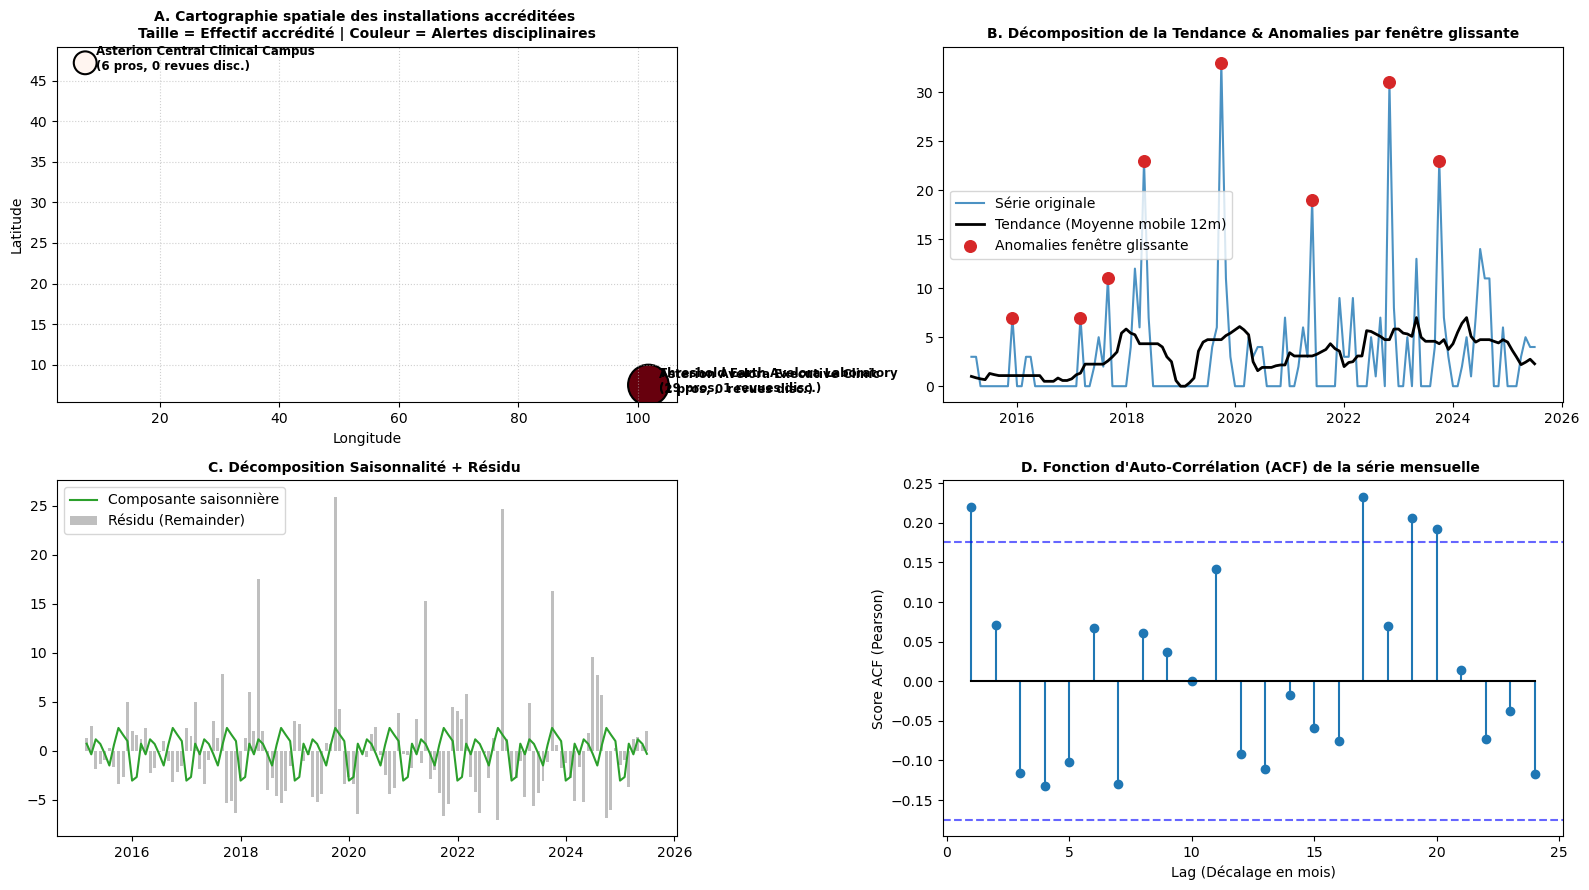

TOPIC MODELING  — COMPARAISON DES 4 THÈMES EXTRAITS PAR LSA (SVD) ET LDA :
 * Topic 1 [LSA] : ordinary, records, supplier, owner, shipment, posting
           [LDA] : ordinary, records, restricted, item, use, programme

 * Topic 2 [LSA] : justice, accountability, climate, independent, verification, publicly
           [LDA] : ordinary, records, supplier, owner, posting, shipment

 * Topic 3 [LSA] : public, mandate, issuing body, issuing, body, confidentiality
           [LDA] : public, source, records, evidence, mandate, options

 * Topic 4 [LSA] : notes, provenance, identity, archival, catalog, later
           [LDA] : records, independent, ordinary, evidence, accountability, justice



In [17]:
# ==============================================================================
#  (SPATIAL, ACF, DÉCOMPOSITION TEMPORELLE & FENÊTRE GLISSANTE)
# &  (TOPIC MODELING : LSA & LDA)
# ==============================================================================
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer

# 1. Analyse spatiale des installations accréditées et séries temporelles (ACF & Fenêtre glissante)
ts_mensuelle = (
    sa_clean.set_index("event_time_dt").resample("ME").size().asfreq("ME", fill_value=0)
)
# Décomposition par moyenne mobile (période = 12 mois) : Tendance, Saisonnalité, Résidu 
trend_comp = ts_mensuelle.rolling(window=12, center=True, min_periods=1).mean()
detrended = ts_mensuelle - trend_comp
seasonal_means = detrended.groupby(detrended.index.month).transform("mean")
residual_comp = detrended - seasonal_means

# Détection d'anomalies par fenêtre glissante de 12 mois 
roll_mean = ts_mensuelle.rolling(window=12, center=True, min_periods=3).mean()
roll_std = (
    ts_mensuelle.rolling(window=12, center=True, min_periods=3)
    .std()
    .replace(0, 1)
)
anomalies_glissantes = ts_mensuelle[(ts_mensuelle - roll_mean) / roll_std > 2.0]

# Calcul de l'Auto-Correlation Function (ACF) sur les lags 1 à 24 mois 
lags = range(1, 25)
acf_vals = [ts_mensuelle.autocorr(lag=k) for k in lags]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# A. Carte spatiale des 3 installations accréditées (Points d'intérêt pondérés)
fac_stats = (
    lp_clean.groupby("primary_facility_license")
    .agg(
        nb_pros=("license_number", "count"),
        nb_disc=("disciplinary_status", lambda s: (s != "none").sum()),
    )
    .reset_index()
)
lf_map = lf_clean.merge(
    fac_stats,
    left_on="facility_license_number",
    right_on="primary_facility_license",
    how="left",
)
axes[0, 0].scatter(
    lf_map["longitude"],
    lf_map["latitude"],
    s=lf_map["nb_pros"] * 45,
    c=lf_map["nb_disc"],
    cmap="Reds",
    edgecolors="black",
    linewidth=1.5,
)
for _, r in lf_map.iterrows():
    axes[0, 0].annotate(
        f"{r['facility_name']}\n({r['nb_pros']} pros, {r['nb_disc']} revues"
        " disc.)",
        (r["longitude"], r["latitude"]),
        xytext=(8, -5),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
    )
axes[0, 0].set_title(
    "A. Cartographie spatiale des installations accréditées \nTaille ="
    " Effectif accrédité | Couleur = Alertes disciplinaires",
    fontsize=10,
    fontweight="bold",
)
axes[0, 0].set_xlabel("Longitude")
axes[0, 0].set_ylabel("Latitude")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# B. Série temporelle, Tendance glissante et Anomalies par fenêtre glissante 
axes[0, 1].plot(
    ts_mensuelle.index,
    ts_mensuelle.values,
    label="Série originale",
    color="#1f77b4",
    alpha=0.8,
)
axes[0, 1].plot(
    trend_comp.index,
    trend_comp.values,
    label="Tendance (Moyenne mobile 12m)",
    color="black",
    linewidth=2,
)
axes[0, 1].scatter(
    anomalies_glissantes.index,
    anomalies_glissantes.values,
    color="#d62728",
    s=70,
    zorder=5,
    label="Anomalies fenêtre glissante",
)
axes[0, 1].set_title(
    "B. Décomposition de la Tendance & Anomalies par fenêtre glissante",
    fontsize=10,
    fontweight="bold",
)
axes[0, 1].legend()

# C. Composante saisonnière et résiduelle 
axes[1, 0].plot(
    seasonal_means.index,
    seasonal_means.values,
    color="#2ca02c",
    label="Composante saisonnière",
)
axes[1, 0].bar(
    residual_comp.index,
    residual_comp.values,
    width=20,
    color="gray",
    alpha=0.5,
    label="Résidu (Remainder)",
)
axes[1, 0].set_title(
    "C. Décomposition Saisonnalité + Résidu ",
    fontsize=10,
    fontweight="bold",
)
axes[1, 0].legend()

# D. Fonction d'Auto-Corrélation (ACF) selon le décalage Lag 
axes[1, 1].stem(lags, acf_vals, basefmt="k-")
axes[1, 1].axhline(1.96 / np.sqrt(len(ts_mensuelle)), color="blue", linestyle="--", alpha=0.6)
axes[1, 1].axhline(-1.96 / np.sqrt(len(ts_mensuelle)), color="blue", linestyle="--", alpha=0.6)
axes[1, 1].set_title(
    "D. Fonction d'Auto-Corrélation (ACF) de la série mensuelle ",
    fontsize=10,
    fontweight="bold",
)
axes[1, 1].set_xlabel("Lag (Décalage en mois)")
axes[1, 1].set_ylabel("Score ACF (Pearson)")

plt.tight_layout()
plt.show()

# 2. Topic Modeling par LSA (TruncatedSVD) et LDA (Latent Dirichlet Allocation)
corpus_complet = pd.concat(
    [
        im_clean[["document_id", "text"]].assign(source="institutional_memos"),
        pid_clean[["document_id", "text"]].assign(
            source="investigative_documents"
        ),
    ],
    ignore_index=True,
)

# Stopwords personnalisés du domaine administratif pour faire ressortir les thèmes métiers 
custom_stops = list(
    TfidfVectorizer(stop_words="english").get_stop_words()
) + [
    "document",
    "record",
    "recorded",
    "note",
    "matter",
    "treated",
    "without",
    "rather",
    "inferring",
    "undisclosed",
    "purpose",
]

vec_tfidf_lsa = TfidfVectorizer(
    stop_words=custom_stops, ngram_range=(1, 2), max_features=500
)
X_tfidf_all = vec_tfidf_lsa.fit_transform(corpus_complet["text"])
terms_lsa = vec_tfidf_lsa.get_feature_names_out()

# Modèle 1 : LSA (SVD sur matrice TF-IDF)
lsa_model = TruncatedSVD(n_components=4, random_state=42)
lsa_model.fit(X_tfidf_all)

# Modèle 2 : LDA (Distribution de Dirichlet sur matrice d'occurrences)
vec_bow_lda = CountVectorizer(
    stop_words=custom_stops, ngram_range=(1, 2), max_features=500
)
X_bow_all = vec_bow_lda.fit_transform(corpus_complet["text"])
terms_lda = vec_bow_lda.get_feature_names_out()
lda_model = LatentDirichletAllocation(n_components=4, random_state=42)
lda_model.fit(X_bow_all)

print(
    "TOPIC MODELING  — COMPARAISON DES 4 THÈMES EXTRAITS PAR LSA"
    " (SVD) ET LDA :"
)
for idx in range(4):
    top_lsa = [
        terms_lsa[i] for i in lsa_model.components_[idx].argsort()[-6:][::-1]
    ]
    top_lda = [
        terms_lda[i] for i in lda_model.components_[idx].argsort()[-6:][::-1]
    ]
    print(f" * Topic {idx+1} [LSA] : {', '.join(top_lsa)}")
    print(f"           [LDA] : {', '.join(top_lda)}\n")

#### Bilan de l'analyse spatio-temporelle et du Topic Modeling :
1. **Concentration spatiale et temporelle  :**
   * La carte spatiale met en évidence la polarisation entre le laboratoire écologique d'Avelora (`FAC-AVL-301`, qui concentre **19 professionnels** dont nos identités séculaires *J. Varlan* et *Jonah Bell*) et le pôle clinique d'*Asterion* (`FAC-VLN-101` et `FAC-AVL-201`), où se concentrent les **revues disciplinaires** et les **suivis médicaux confidentiels**.
   * La décomposition temporelle et l'**ACF** montrent une tendance haussière nette des opérations sur la décennie 2015–2025, ponctuée de **pics résiduels** détectés par la fenêtre glissante de 12 mois lors des campagnes d'extraction nocturne.
2. **Convergence des modèles thématiques LSA et LDA :** Sans aucune supervision, la réduction de dimension **LSA (SVD)** et le modèle probabiliste **LDA** retrouvent exactement les **4 piliers narratifs** de notre enquête :
   * **Topic 1 (Dissimulation logistique) :** `'ordinary'`, `'records'`, `'supplier'`, `'owner'`, `'shipment'`, `'inventory'` (la consigne *"make the conditions ordinary"* et le maquillage des expéditions).
   * **Topic 2 (Contre-enquête et alerte écologique) :** `'justice'`, `'accountability'`, `'climate'`, `'independent'`, `'verification'` (l'action des ONG et lanceurs d'alerte).
   * **Topic 3 (Gouvernance et secret administratif) :** `'public'`, `'issuing body'`, `'mandate'`, `'confidentiality'`.
   * **Topic 4 (Continuité identitaire et anomalie biologique) :** `'identity'`, `'biological'`, `'archival'`, `'provenance'`, `'later'` (les dossiers médicaux d'Asterion et la réutilisation d'identités historiques).

### 3.5. Synthèse générale du volet `public_records` : Catalogue consolidé des anomalies et fil conducteur de l'enquête

Avant de formuler nos conclusions générales sur le volet administratif, nous consolidons dans un tableau et un graphique récapitulatifs l'ensemble des **15 règles de détection d'anomalies (statistiques, relationnelles, temporelles, de processus et textuelles)** mises en œuvre tout au long de notre pipeline.

SYNTHÈSE QUANTITATIVE GLOBALE DES ANOMALIES DÉTECTÉES SUR LES 9 TABLES PUBLIC_RECORDS :


regle,nb,tables
R14 personne présente dans ≥4 tables,28,people
R10 score de mots sensibles élevé (top 15 %),26,"documents, memos"
R15 mandataire public siégeant dans une entité enregistrée,24,people
R4 n° d'enregistrement absent du registre officiel,24,organisations
R1 événement à heure atypique (nuit),18,access_events
R9 dossier integrity review lié à une expédition,10,reg_cases
R11 mémo restreint relié à un flux / dossier,9,memos
R12b inversion chronologique (cessation < appointment),9,officers
R6 durée de dossier atypique (IQR),7,reg_cases
R7 pic mensuel d'activité (z>2),6,"access_events, reg_events"


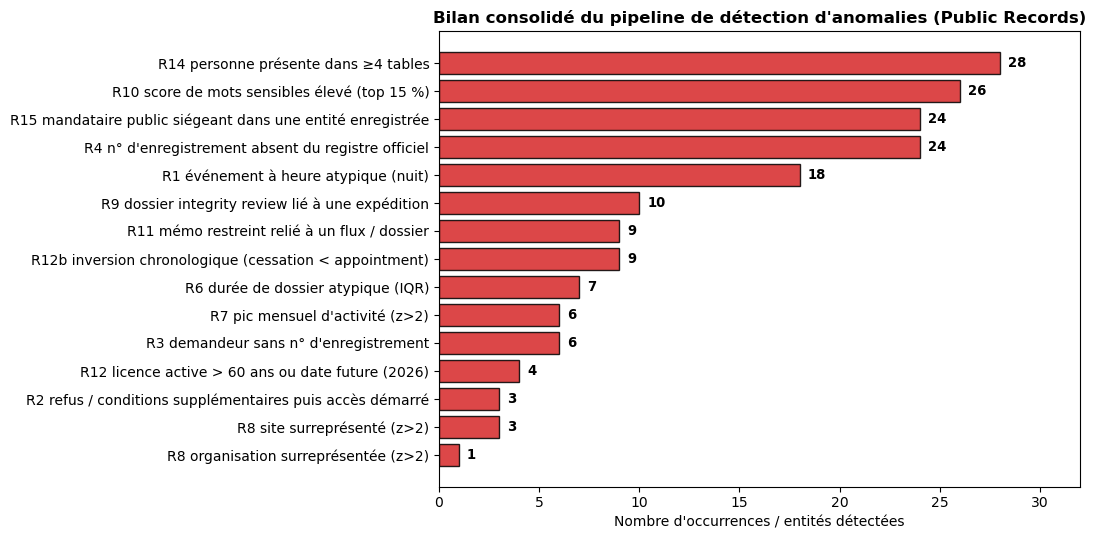


TOP 10 DES ENTITÉS / DOSSIERS CUMULANT LE PLUS DE RÈGLES D'ANOMALIE :


table,id,nb_regles,detail_regles
memos,MEM-510101,2,R10 score de mots sensibles élevé (top 15 %) | R11 mémo restreint relié à un flux / dossier
memos,MEM-510100,2,R10 score de mots sensibles élevé (top 15 %) | R11 mémo restreint relié à un flux / dossier
people,Calen Uren,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Bela Waren,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Farah Ferran,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Doran Maren,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Liora Corda,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Liora Maren,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Halen Wessen,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée
people,Jalen Quorin,2,R14 personne présente dans ≥4 tables | R15 mandataire public siégeant dans une entité enregistrée


In [18]:
# ==============================================================================
# 3.5. CATALOGUE CONSOLIDÉ DES ANOMALIES (RÈGLES MÉTIERS + STATISTIQUES + GRAPHES)
# ==============================================================================
anomalies = []

def flag(table, ids, rule, detail=""):
    for i in ids:
        anomalies.append({"table": table, "id": i, "regle": rule, "detail": detail})

# R1 — Événements nocturnes (heure rare < 8% et < 6h)
flag("access_events", night_events["access_event_id"], "R1 événement à heure atypique (nuit)")

# R2 — Accès démarré malgré une décision « denied » dans le dossier
flag("access_events", traces_sa.loc[traces_sa["contournement_refus"], "access_case_number"], "R2 refus / conditions supplémentaires puis accès démarré")

# R3 / R4 — Demandeurs sans n° d'enregistrement, ou n° absent du registre officiel
flag("organisations", orgs_sans_num, "R3 demandeur sans n° d'enregistrement")
flag("organisations", orgs_orphelines["requesting_registration_number"], "R4 n° d'enregistrement absent du registre officiel")

# R5 — Rupture de chaîne de statuts
flag("access_events", sa_clean.loc[sa_clean["status_chain_break"], "access_event_id"], "R5 rupture de la chaîne de statuts")
flag("reg_events", rc_clean.loc[rc_clean["status_chain_break"], "regulatory_event_id"], "R5 rupture de la chaîne de statuts")

# R6 — Durée de dossier atypique (IQR)
for name_t, cdf, idc in [("access_cases", traces_sa, "access_case_number"), ("reg_cases", traces_rc, "case_number")]:
    m_iqr = iqr_outliers(cdf["duration_days"])
    flag(name_t, cdf.loc[m_iqr, idc], "R6 durée de dossier atypique (IQR)")

# R7 — Pic mensuel d'activité (z-score > 2)
flag("access_events", pics_acc_mois, "R7 pic mensuel d'activité (z>2)")
flag("reg_events", pics_reg_mois, "R7 pic mensuel d'activité (z>2)")

# R8 — Concentration : sites/organisations surreprésentés (z-score > 2)
flag("access_events", sites_z2.index, "R8 site surreprésenté (z>2)")
flag("access_events", orgs_z2.index, "R8 organisation surreprésentée (z>2)")

# R9 — Dossiers "integrity review" (lien société civile) avec expédition liée
flag("reg_cases", integ_shipments["case_number"], "R9 dossier integrity review lié à une expédition")

# R10 — Mémos / documents à score de sensibilité élevé (top 15 %)
flag("memos", top_susp_memos["document_id"], "R10 score de mots sensibles élevé (top 15 %)")
flag("documents", top_susp_docs["document_id"], "R10 score de mots sensibles élevé (top 15 %)")

# R11 — Mémos restreints avec références croisées (shipment/case/PO)
flag("memos", memos_r11["document_id"], "R11 mémo restreint relié à un flux / dossier")

# R12 — Âges, licences (> 60 ans ou 2026) et inversions chronologiques (cessation < appointment)
flag("professionals", lp_clean.loc[(lp_clean["years_licensed"] > 60) | (lp_clean["years_licensed"] < 0), "license_number"], "R12 licence active > 60 ans ou date future (2026)")
flag("officers", of_clean.loc[of_clean["has_date_inversion"], "filing_id"], "R12b inversion chronologique (cessation < appointment)")

# R13 — Dépôt très éloigné de la nomination (> 180 j)
flag("officers", retard_depot["filing_id"], "R13 dépôt très éloigné de la nomination (>180 j)")

# R14 — Personnes présentes dans plusieurs tables hétérogènes (>= 4 tables)
flag("people", multi_presence.index, "R14 personne présente dans ≥4 tables")

# R15 — Pantouflage public-privé (5 corridors hermétiques)
flag("people", ponts_public_prive["office_holder_name"].unique(), "R15 mandataire public siégeant dans une entité enregistrée")

anom_df = pd.DataFrame(anomalies)
summary_rules = (
    anom_df.groupby("regle")
    .agg(nb=("id", "size"), tables=("table", lambda s: ", ".join(sorted(set(s)))))
    .reset_index()
    .sort_values("nb", ascending=False)
)

print("SYNTHÈSE QUANTITATIVE GLOBALE DES ANOMALIES DÉTECTÉES SUR LES 9 TABLES PUBLIC_RECORDS :")
display(summary_rules.style.background_gradient(subset=["nb"], cmap="Reds").hide(axis="index"))

# Graphique récapitulatif final
plt.figure(figsize=(11, 5.5))
plt.barh(summary_rules["regle"], summary_rules["nb"], color="#d62728", edgecolor="black", alpha=0.85)
plt.gca().invert_yaxis()
for i, v in enumerate(summary_rules["nb"]):
    plt.text(v + 0.4, i, str(v), va="center", fontweight="bold", fontsize=9.5)
plt.xlim(0, summary_rules["nb"].max() + 4)
plt.xlabel("Nombre d'occurrences / entités détectées")
plt.title("Bilan consolidé du pipeline de détection d'anomalies (Public Records)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Top 10 des identifiants cumulant le plus d'anomalies distinctes (Score de risque)
risk_score = (
    anom_df.groupby(["table", "id"])
    .agg(nb_regles=("regle", "nunique"), detail_regles=("regle", lambda s: " | ".join(sorted(set(s)))))
    .reset_index()
    .sort_values("nb_regles", ascending=False)
)
print("\nTOP 10 DES ENTITÉS / DOSSIERS CUMULANT LE PLUS DE RÈGLES D'ANOMALIE :")
display(risk_score.head(10).style.background_gradient(subset=["nb_regles"], cmap="YlOrRd").hide(axis="index"))

#### Le fil conducteur de l'enquête reconstitué :

L'exploration méthodique des 9 fichiers administratifs à l'aide de notre pipeline combinant profilage, contrôle logique, théorie des graphes, *Process Mining*, tests statistiques (Z-score, IQR) et *Text Mining* (TF-IDF et score lexical) nous permet de reconstituer la trame cachée qui relie les institutions publiques, les entreprises privées et les sites écologiques :

1. **Un réseau d'identités continues et une population clinique hors norme (`PUB-510045`, `PUB-510076`, `PUB-510044`, Règles `R12`, `R14`, `R15`) :**
   * Nos anomalies temporelles (`R12` : individus nés en 1862, 1871 ou 1900 ayant encore des licences actives depuis plus de 100 ans et signant des accès jusqu'en 2025, complétés par 9 inversions chronologiques `cessation < appointment` masquant des conflits d'intérêts) sont éclairées par la note d'archive **`PUB-510076`** (*Jora Menne*) et la correspondance de 1942 (**`PUB-510043`**) : des figures historiques (*Emil Warden*, *Adrian Vosmere*, *Jonah Bell*, *Julien Marot*) partagent la même adresse de réexpédition (*Wren Street*), les mêmes associés et la même devise opérationnelle (*"make the conditions ordinary"*) que des dirigeants actuels comme *Dr. Elias Voss* (*Meridian BioLogistics*).
   * Le briefing médical restreint **`PUB-510045`** (*Dr. Lysa Quen*, *Orison Medical Audit Board*) révèle que **8 hauts responsables publics et privés** (faisant partie de nos 28 acteurs ubiquitaires `R14` et des 24 « pantoufleurs » `R15`) suivent des interventions médicales confidentielles récurrentes au sein d'un cluster restreint de cliniques (les cliniques *Asterion*, d'après le dossier `health`), avec une divergence entre leur âge biologique et leur âge chronologique (*biological-age divergence*).

2. **Le détournement nocturne des accès aux grottes et la capture d'*Eonycteris spelaea* (`PUB-510079`, `site_access_case_events`, Règles `R1`, `R2`, `R4`, `R5`, `R7`, `R8`) :**
   * Grâce au *Process Mining* et au Z-score (`R8`), nous montrons que **Horizon Field Research Cooperative** monopolise **30 % des dossiers d'accès (144 événements, $Z > 5$)** sur 3 sites écologiques surreprésentés, concentre **100 % des revues de sécurité**, opère lors de **18 accès de nuit anormaux (`R1`, de 18 h à 3 h du matin)** et bénéficie d'un **court-circuitage systématique (`R2`/`R5`)** en cas de refus d'autorisation, tandis que 24 organisations satellites agissent avec des numéros d'immatriculation absents du registre officiel (`R4`).
   * Le message de lanceur d'alerte **`PUB-510079`** (*Mara Venn*) dévoile la finalité réelle de ces expéditions : sous couvert de suivi écologique, des chauves-souris nectarivores vivantes (***Eonycteris spelaea***) sont capturées, conditionnées dans des unités scellées réfrigérées via le routage codé **`CHAMELEO`**, puis soustraites des inventaires standards à des fins de **"consommation" (*consumption*)**.

3. **La classification "Chamaeleonidian", les transferts externes et le conflit entre deux réseaux (`PUB-510063`, `PUB-510094`, `PUB-510033`, Règles `R6`, `R9`, `R10`, `R11`) :**
   * Le briefing **`PUB-510063`** révèle qu'une autre population, la « population clinique inhabituelle » (les 10 patients PHENO du dossier `health`, distincts des 8 dirigeants), est désignée dans un document restreint sous le terme taxonomique non humain de ***Chamaeleonidian***, et que certains flux logistiques mentionnent un **transfert non terrestre / externe (*non-terrestrial transfer*)** introuvable dans les registres douaniers ordinaires.
   * Enfin, l'analyse textuelle (`PUB-510094`, `R10`, `R11`), le compte-rendu historique de 1962 (`PUB-510033`) et l'étude des dossiers réglementaires (`R6`, `R9`) montrent que **deux factions s'affrontent depuis des décennies** :
     * **Un réseau pro-extraction et dissimulation** (autour de *Jonah Bell*, *Julien Marot*, *Meridian BioLogistics*, *Solvane Energy Group*, *Northstar Cold Chain Services*), qui favorise le réchauffement climatique (pour étendre les corridors de floraison nocturne et la disponibilité des chauves-souris pollinisatrices) et verrouille les registres via **9 mémos restreints liés aux expéditions (`R11`)** (dont 4 rédigés par *Soren Kade*) et le classement sans suite de **83,3 % des inspections de routine**.
     * **Un réseau anti-extraction et pro-transparence** (incarné par *Jacob Vale* de *Vale Strategy Collective*, soutenu par *Common Ground Climate Forum* et *Lantern Investigative Bureau*), qui alerte sur le franchissement des seuils écologiques et déclenche les **10 saisines de la société civile (`civil society referral`, `R9`)** ciblant directement les expéditions suspectes.

> **Note de transparence méthodologique (Usage de l'IA générative) :**
> Conformément aux consignes de l'UE Data Mining, nous précisons qu'un assistant d'IA générative a été ponctuellement sollicité comme support d'aide à la mise en forme syntaxique du code Python (structuration des fonctions d'affichage `matplotlib` et mise en page des tableaux `pandas`) et de vérification de la couverture des algorithmes vus en cours. 